# IaCGOD repair-loop analysis (latest runs)

In [1]:
import sys, os, re, json, glob, warnings, itertools
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
sys.path.insert(0, "audit")
import repair_loop as rl

FINAL = Path("../results"); RUNS = "../runs"; DATA = Path("../data"); RES = Path("result/final")
CACHE = FINAL / "_analysis_cache"; CACHE.mkdir(exist_ok=True)
FIG = FINAL / "_figures"; FIG.mkdir(exist_ok=True)
plt.style.use("ggplot"); sns.set_palette("muted")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 70)

LABEL = {
 "CFN_RealAWS_DSV4F": "DeepSeek-V4-Flash", "CFN_RealAWS_GLM53F": "GLM-5.3-Flash", "CFN_RealAWS_Gemini38F": "Gemini-3.8-Flash",
 "CFN_RealAWS_Opus55": "Claude-Opus-5.5", "CFN_RealAWS_OpenCode_DSV4F": "OpenCode+DSV4F", "CFN_RealAWS_Gemini36F_L345": "Gemini-3.6-Flash (L3-5)",
 "CFN_RealAWS_DSV4F_DeployOnly_L345": "DSV4F deploy-only (L3-5)", "CFN_DPIaCEval_o3mini_DeployOnly": "o3-mini DPIaC-Eval",
 "TF_RealAWS_DSV4F": "DeepSeek-V4-Flash", "TF_RealAWS_GLM53F": "GLM-5.3-Flash", "TF_RealAWS_Gemini38F": "Gemini-3.8-Flash",
 "TF_RealAWS_Opus55": "Claude-Opus-5.5", "TF_RealAWS_OpenCode_DSV4F": "OpenCode+DSV4F", "TF_IaCEval_DSV4F_LintOnly": "DSV4F IaC-Eval (lint-only)",
}
for lang in ("CFN", "TF"):
    for c, l in (("IaCGOD", "IaCGOD"), ("NoDenseRAG", "no dense RAG"), ("OpenCodeRetriever", "OpenCode+Retriever"),
                 ("NoGraphRAG", "no GraphRAG"), ("NoPlanner", "no Planner"), ("TrivyAllSeverities", "Trivy all severities"),
                 ("NoRemediator", "no Remediator"), ("NoQueryRewrite", "no query rewrite")):
        LABEL[f"{lang}_Ablation_{c}"] = l
GROUPS = {
 "CFN main": [e for e in LABEL if e.startswith("CFN_") and "Ablation" not in e],
 "TF main": [e for e in LABEL if e.startswith("TF_") and "Ablation" not in e],
 "CFN ablation": [e for e in LABEL if e.startswith("CFN_Ablation")],
 "TF ablation": [e for e in LABEL if e.startswith("TF_Ablation")],
}
FULL = {"CFN": ["CFN_RealAWS_DSV4F", "CFN_RealAWS_GLM53F", "CFN_RealAWS_Gemini38F"], "TF": ["TF_RealAWS_DSV4F", "TF_RealAWS_GLM53F", "TF_RealAWS_Gemini38F"]}
SELECTED = [e for g in GROUPS.values() for e in g]
BUDGET = 15
lang_of = lambda e: "CFN" if e.startswith("CFN_") else "TF"
summary_status = pd.read_csv(FINAL / "SUMMARY.csv").set_index("experiment")
print(len(SELECTED), "experiments;", summary_status.loc[SELECTED, "fulfilled"].sum(), "fulfilled")

30 experiments; 14 fulfilled


In [2]:
COV_MAP_CFN = {"total_required_resources": "req", "total_generated_resources": "gen", "correct_resources": "correct", "missing_resources": "missing",
               "extra_resources": "extra", "coverage_pct": "cov_pct", "accuracy_pct": "acc_pct", "extra_resource_types": "extra_types", "missing_resource_types": "missing_types"}
COV_MAP_TF = {"resource_req": "req", "resource_gen": "gen", "resource_cor": "correct", "resource_missing": "missing", "resource_extra": "extra",
              "resource_cov_pct": "cov_pct", "resource_acc_pct": "acc_pct", "resource_extra_list": "extra_types", "resource_missing_list": "missing_types"}
import csv; csv.field_size_limit(sys.maxsize)

def load_runs(e):
    st = json.load(open(FINAL / e / "status.json"))
    cols = ["row_number", "run_id", "status", "final_validation_passed", "iterations_used", "llm_calls_total", "token_all_tokens", "duration_seconds", "ground_truth_path",
            "submitted_matched_validated", "final_verdict_source", "harness_turns"]
    r = pd.read_csv(FINAL / e / "results_final.csv", engine="python", usecols=lambda c: c in cols)
    ds = pd.read_csv(DATA / st["dataset"]); dcol = "difficulty" if "difficulty" in ds else "difficulty_level"
    r["difficulty"] = r.row_number.map(ds.drop_duplicates("row_number").set_index("row_number")[dcol])
    cv = pd.read_csv(RES / f"Coverage_{e}.csv")
    cv = cv.rename(columns=COV_MAP_CFN if lang_of(e) == "CFN" else COV_MAP_TF)
    if "row_number" not in cv:
        cv["row_number"] = r.row_number.values[cv.row_index.values]
    keep = ["row_number"] + [c for c in ["req", "gen", "correct", "missing", "extra", "cov_pct", "acc_pct", "extra_types", "missing_types"] if c in cv]
    r = r.merge(cv[keep].drop_duplicates("row_number"), on="row_number", how="left")
    r["passed"] = (r.final_validation_passed == True) & (r.iterations_used <= BUDGET)
    r["iterations_used"] = r.iterations_used.clip(upper=BUDGET)
    r["invalid"] = r.row_number.astype(int).astype(str).isin(st["invalid_rows"])
    r["exp"] = e; r["lang"] = lang_of(e)
    return r

runs = pd.concat([load_runs(e) for e in SELECTED], ignore_index=True)
print(runs.groupby("exp").agg(rows=("row_number", "size"), passed=("passed", "sum"), invalid=("invalid", "sum")).loc[SELECTED])

                                   rows  passed  invalid
exp                                                     
CFN_RealAWS_DSV4F                   250     239        3
CFN_RealAWS_GLM53F                  250     228        3
CFN_RealAWS_Gemini38F               250     248        0
CFN_RealAWS_Opus55                  250     246        0
CFN_RealAWS_OpenCode_DSV4F          250     227        2
CFN_RealAWS_Gemini36F_L345          137     136        0
CFN_RealAWS_DSV4F_DeployOnly_L345   134     124        2
CFN_DPIaCEval_o3mini_DeployOnly     153     138        2
TF_RealAWS_DSV4F                    250     246        0
TF_RealAWS_GLM53F                   250     246        0
TF_RealAWS_Gemini38F                250     249        1
TF_RealAWS_Opus55                   250     250        0
TF_RealAWS_OpenCode_DSV4F           250     242        4
TF_IaCEval_DSV4F_LintOnly           372     363        5
CFN_Ablation_IaCGOD                  50      49        0
CFN_Ablation_NoDenseRAG        

In [3]:
CLASSES_ALL = ["syntax", "schema", "security", "deploy"]
INDEX = None
def load_iters(e):
    global INDEX
    src = FINAL / e / "results_final.csv"; p = CACHE / f"iters_{e}.pkl"; p_ids = CACHE / f"iters_{e}.run_ids.json"
    rids = sorted(runs.loc[runs.exp == e, "run_id"].dropna().astype(str).unique())
    if p.exists() and p_ids.exists() and p.stat().st_mtime >= src.stat().st_mtime and json.load(open(p_ids)) == rids:
        return pd.read_pickle(p)
    if INDEX is None:
        INDEX = rl.index_runs(RUNS)
    meta = runs.loc[runs.exp == e, ["run_id", "row_number"]].dropna()
    blocking = "all" if "TrivyAllSeverities" in e else rl.BLOCKING_DEFAULT
    df = rl.build_iteration_table(meta, RUNS, lang_of(e), index=INDEX, blocking=blocking)
    df.to_pickle(p); json.dump(rids, open(p_ids, "w"))
    return df

its = []
for e in SELECTED:
    d = load_iters(e); d["exp"] = e; its.append(d)
iters = pd.concat(its, ignore_index=True)
for c in ["syntax", "schema", "security"]:
    iters[f"{c}_ran"] = iters[f"{c}_ran"].fillna(False).astype(bool)
    iters[f"{c}_ok"] = iters[f"{c}_ok"].fillna(True).astype(bool)
iters["deploy_ran"] = iters["deploy_ran"].fillna(False).astype(bool)
iters["deploy_ok"] = iters["deploy_ok"].fillna(False).astype(bool)
for c in CLASSES_ALL:
    iters[f"{c}_keys"] = iters[f"{c}_keys"].fillna("")
iters["lang"] = iters.exp.map(lang_of)
iters = iters[iters.iteration <= BUDGET]
iters = iters.sort_values(["exp", "run_id", "iteration"]).reset_index(drop=True)
meta_cols = runs[["exp", "run_id", "row_number", "difficulty", "passed", "invalid", "iterations_used", "token_all_tokens"]].drop_duplicates(["exp", "run_id"])
iters = iters.merge(meta_cols.drop(columns=["row_number"]), on=["exp", "run_id"], how="left")
print(iters.shape, "iteration rows;", iters.run_id.nunique(), "runs with iteration logs of", runs.run_id.nunique())
cover = iters.groupby("exp").run_id.nunique() / runs.groupby("exp").run_id.nunique()
display(cover.rename("share of runs with iteration logs").to_frame().T)

(12585, 43) iteration rows; 4094 runs with iteration logs of 4095


exp,CFN_Ablation_IaCGOD,CFN_Ablation_NoDenseRAG,CFN_Ablation_NoGraphRAG,CFN_Ablation_NoPlanner,CFN_Ablation_NoQueryRewrite,CFN_Ablation_NoRemediator,CFN_Ablation_OpenCodeRetriever,CFN_Ablation_TrivyAllSeverities,CFN_DPIaCEval_o3mini_DeployOnly,CFN_RealAWS_DSV4F,CFN_RealAWS_DSV4F_DeployOnly_L345,CFN_RealAWS_GLM53F,CFN_RealAWS_Gemini36F_L345,CFN_RealAWS_Gemini38F,CFN_RealAWS_OpenCode_DSV4F,CFN_RealAWS_Opus55,TF_Ablation_IaCGOD,TF_Ablation_NoDenseRAG,TF_Ablation_NoGraphRAG,TF_Ablation_NoPlanner,TF_Ablation_NoQueryRewrite,TF_Ablation_NoRemediator,TF_Ablation_OpenCodeRetriever,TF_Ablation_TrivyAllSeverities,TF_IaCEval_DSV4F_LintOnly,TF_RealAWS_DSV4F,TF_RealAWS_GLM53F,TF_RealAWS_Gemini38F,TF_RealAWS_OpenCode_DSV4F,TF_RealAWS_Opus55
share of runs with iteration logs,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.98,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## A. Iterations to pass

In [4]:
NS = [1, 3, 5, 10, 15]
FA_PASS = {}
for _e in SELECTED:
    _p = FINAL / f"{_e}_FirstAttempt" / "results_final.csv"
    if _p.exists():
        _f = pd.read_csv(_p, engine="python", usecols=["row_number", "final_validation_passed", "validity"])
        FA_PASS[_e] = set(_f[(_f.final_validation_passed == True) & (_f.validity == "valid_pass")].row_number.astype(int))
        pd.DataFrame({"row_number": sorted(FA_PASS[_e])}).to_csv(FINAL / _e / "first_attempt_override.csv", index=False)
        print("first-attempt overlay", _e, ":", len(FA_PASS[_e]), "rows with a valid first-attempt pass")
def fa_mask(r): return r.row_number.astype(int).isin(FA_PASS.get(r.exp.iloc[0], set()))
def pass_at(r, n): return float((((r.passed) & (r.iterations_used <= n)) | fa_mask(r)).sum() / len(r))
rows = []
for e in SELECTED:
    r = runs[runs.exp == e]; ok = r[r.passed]
    rows.append({"group": next(g for g, v in GROUPS.items() if e in v), "exp": e, "label": LABEL[e], "rows": len(r), "pass": int(r.passed.sum()),
                 **{f"p@{n}": round(100 * pass_at(r, n), 1) for n in NS},
                 "iters_mean": round(ok.iterations_used.mean(), 2), "iters_median": ok.iterations_used.median(), "iters_p90": ok.iterations_used.quantile(.9),
                 "first_try_%": round(100 * (((r.passed) & (r.iterations_used == 1)) | fa_mask(r)).sum() / len(r), 1),
                 "ktokens/scen": round(r.token_all_tokens.mean() / 1000, 0), "llm_calls/scen": round(r.llm_calls_total.mean(), 1)})
tabA = pd.DataFrame(rows)
for g in GROUPS:
    print("\n==", g); display(tabA[tabA.group == g].drop(columns=["group", "exp"]).set_index("label"))

first-attempt overlay TF_RealAWS_Gemini38F : 47 rows with a valid first-attempt pass

== CFN main


,rows,pass,p@1,p@3,p@5,p@10,p@15,iters_mean,iters_median,iters_p90,first_try_%,ktokens/scen,llm_calls/scen
label,,,,,,,,,,,,,
DeepSeek-V4-Flash,250,239,18.8,61.6,79.2,91.6,95.6,3.55,3.0,7.0,18.8,167.0,10.8
GLM-5.3-Flash,250,228,18.4,60.8,78.4,85.2,91.2,3.50,2.0,7.0,18.4,195.0,12.2
Gemini-3.8-Flash,250,248,49.2,90.8,95.6,98.4,99.2,2.00,2.0,3.0,49.2,66.0,5.1
Claude-Opus-5.5,250,246,61.6,94.0,97.6,98.4,98.4,1.55,1.0,2.0,61.6,19.0,4.0
OpenCode+DSV4F,250,227,31.6,70.4,82.0,88.0,90.8,2.70,2.0,5.0,31.6,42.0,13.5
Gemini-3.6-Flash (L3-5),137,136,31.4,81.8,94.2,97.8,99.3,2.48,2.0,4.0,31.4,48.0,6.4
DSV4F deploy-only (L3-5),134,124,22.4,59.7,72.4,89.6,92.5,3.49,2.0,7.0,22.4,254.0,12.1
o3-mini DPIaC-Eval,153,138,24.2,67.3,77.8,87.6,90.2,3.05,2.0,6.0,24.2,124.0,11.7



== TF main


,rows,pass,p@1,p@3,p@5,p@10,p@15,iters_mean,iters_median,iters_p90,first_try_%,ktokens/scen,llm_calls/scen
label,,,,,,,,,,,,,
DeepSeek-V4-Flash,250,246,40.0,74.0,84.4,95.2,98.4,2.91,2.0,7.0,40.0,141.0,8.0
GLM-5.3-Flash,250,246,20.8,59.2,82.0,93.2,98.4,3.67,3.0,7.0,20.8,183.0,10.3
Gemini-3.8-Flash,250,249,20.4,80.4,94.0,99.2,99.6,3.18,3.0,5.0,20.4,115.0,8.4
Claude-Opus-5.5,250,250,76.4,95.6,98.4,99.6,100.0,1.42,1.0,2.0,76.4,13.0,3.1
OpenCode+DSV4F,250,242,53.6,84.0,89.6,95.2,96.8,2.13,1.0,4.0,53.6,25.0,11.0
DSV4F IaC-Eval (lint-only),372,363,30.9,59.4,83.3,96.2,97.6,3.23,3.0,6.0,30.9,103.0,9.8



== CFN ablation


,rows,pass,p@1,p@3,p@5,p@10,p@15,iters_mean,iters_median,iters_p90,first_try_%,ktokens/scen,llm_calls/scen
label,,,,,,,,,,,,,
IaCGOD,50,49,26.0,74.0,88.0,94.0,98.0,3.04,2.0,5.6,26.0,180.0,8.2
no dense RAG,50,49,36.0,74.0,94.0,98.0,98.0,2.55,2.0,4.0,36.0,174.0,6.8
OpenCode+Retriever,50,47,26.0,64.0,86.0,94.0,94.0,2.83,2.0,4.4,26.0,64.0,17.7
no GraphRAG,50,50,38.0,92.0,98.0,98.0,100.0,2.18,2.0,3.0,38.0,102.0,5.3
no Planner,50,48,46.0,90.0,94.0,96.0,96.0,1.83,2.0,3.0,46.0,128.0,4.7
Trivy all severities,50,49,22.0,66.0,94.0,96.0,98.0,2.96,3.0,5.0,22.0,208.0,7.6
no Remediator,50,48,30.0,80.0,94.0,96.0,96.0,2.17,2.0,4.0,30.0,113.0,4.9
no query rewrite,50,49,28.0,80.0,90.0,96.0,98.0,2.63,2.0,5.0,28.0,172.0,5.8



== TF ablation


,rows,pass,p@1,p@3,p@5,p@10,p@15,iters_mean,iters_median,iters_p90,first_try_%,ktokens/scen,llm_calls/scen
label,,,,,,,,,,,,,
IaCGOD,50,50,30.0,78.0,86.0,96.0,100.0,2.92,2.0,6.1,30.0,108.0,7.5
no dense RAG,49,47,26.5,53.1,73.5,89.8,95.9,3.83,3.0,8.0,26.5,285.0,11.4
OpenCode+Retriever,50,47,36.0,82.0,92.0,94.0,94.0,2.02,2.0,4.0,36.0,74.0,13.7
no GraphRAG,50,48,40.0,86.0,92.0,94.0,96.0,2.23,2.0,3.3,40.0,168.0,6.9
no Planner,50,49,54.0,92.0,96.0,98.0,98.0,1.65,1.0,2.2,54.0,76.0,3.5
Trivy all severities,50,49,8.0,56.0,82.0,96.0,98.0,3.78,3.0,6.2,8.0,203.0,9.5
no Remediator,50,49,34.0,86.0,96.0,98.0,98.0,2.24,2.0,4.0,34.0,78.0,4.7
no query rewrite,50,49,40.0,88.0,98.0,98.0,98.0,2.02,2.0,3.2,40.0,100.0,4.6


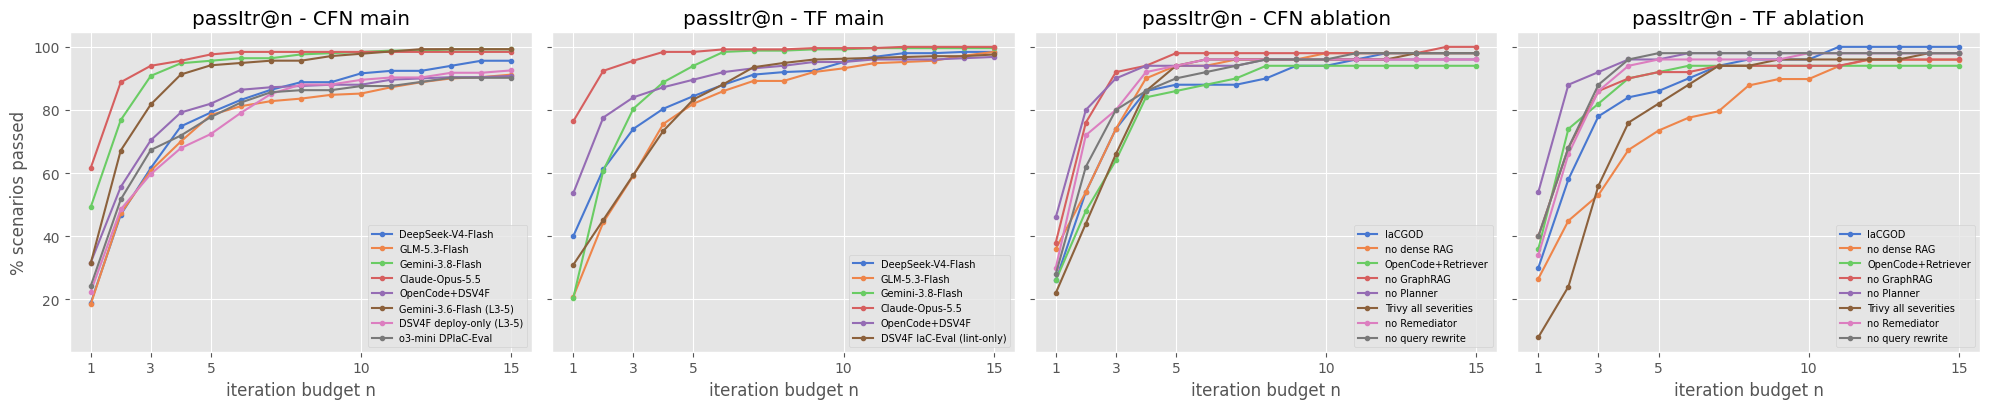

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(20, 4.2), sharey=True)
for ax, (g, exps) in zip(axs, GROUPS.items()):
    for e in exps:
        r = runs[runs.exp == e]
        ax.plot(range(1, 16), [100 * pass_at(r, n) for n in range(1, 16)], marker="o", ms=3, label=LABEL[e])
    ax.set_title(f"passItr@n - {g}"); ax.set_xlabel("iteration budget n"); ax.set_xticks([1, 3, 5, 10, 15])
    ax.legend(fontsize=7, loc="lower right")
axs[0].set_ylabel("% scenarios passed")
plt.tight_layout(); plt.savefig(FIG / "A_passitr_curves.png", dpi=150); plt.show()


== CFN main - mean iterations to pass by level  |  pass rate (%) by level


iterations                             pass %                               
difficulty                        1     2     3     4     5   6      1      2      3      4     5   6
exp                                                                                                  
DeepSeek-V4-Flash              1.98  2.83  4.65  4.11  4.16 NaN   94.0   96.0   96.0   94.0  98.0 NaN
GLM-5.3-Flash                  2.29  2.73  3.50  4.22  4.72 NaN   84.0   98.0   92.0   90.0  92.0 NaN
Gemini-3.8-Flash               1.39  1.82  1.72  2.80  2.24 NaN   98.0  100.0  100.0  100.0  98.0 NaN
Claude-Opus-5.5                1.35  1.32  1.53  1.92  1.63 NaN   96.0  100.0   98.0  100.0  98.0 NaN
OpenCode+DSV4F                 1.60  2.36  2.96  3.38  3.40 NaN   96.0   94.0   98.0   80.0  86.0 NaN
Gemini-3.6-Flash (L3-5)         NaN   NaN  2.30  2.71  2.44 NaN    NaN    NaN  100.0  100.0  97.6 NaN
DSV4F deploy-only (L3-5)        NaN   NaN  3.71  3.60  3.15 NaN    NaN    NaN   89.4   93.3  95.2 NaN
o3-mini DPIaC-Eval             2.31  2.32  3.00  4.53  3.69 NaN   94.1   94.9   97.6   78.9  80.6 NaN


== TF main - mean iterations to pass by level  |  pass rate (%) by level


iterations                               pass %                                  
difficulty                          1     2     3     4     5     6      1      2      3      4      5     6
exp                                                                                                         
DeepSeek-V4-Flash                1.96  2.08  2.08  3.31  5.26   NaN  100.0  100.0  100.0   98.0   94.0   NaN
GLM-5.3-Flash                    2.80  3.02  3.22  4.16  5.26   NaN  100.0   98.0  100.0  100.0   94.0   NaN
Gemini-3.8-Flash                 3.36  2.84  3.38  2.78  3.53   NaN  100.0  100.0  100.0  100.0   98.0   NaN
Claude-Opus-5.5                  1.40  1.22  1.20  1.26  2.04   NaN  100.0  100.0  100.0  100.0  100.0   NaN
OpenCode+DSV4F                   1.88  1.90  1.67  2.23  3.02   NaN  100.0   98.0   98.0   96.0   92.0   NaN
DSV4F IaC-Eval (lint-only)       3.14  2.96  3.28  3.18  3.24  3.57   90.3   96.3   98.8   98.2  100.0  98.5


== CFN ablation - mean iterations to pass by level  |  pass rate (%) by level


iterations                             pass %                                
difficulty                    1     2     3     4     5   6      1      2      3      4      5   6
exp                                                                                               
IaCGOD                     1.67  2.57  3.30  2.85  3.50 NaN  100.0  100.0  100.0  100.0   94.1 NaN
no dense RAG               1.67  1.43  2.70  2.54  3.12 NaN  100.0  100.0  100.0  100.0   94.1 NaN
OpenCode+Retriever         1.67  2.29  2.89  3.15  3.00 NaN  100.0  100.0   90.0  100.0   88.2 NaN
no GraphRAG                1.67  1.86  2.10  1.77  2.76 NaN  100.0  100.0  100.0  100.0  100.0 NaN
no Planner                 1.67  1.57  1.67  1.62  2.25 NaN  100.0  100.0   90.0  100.0   94.1 NaN
Trivy all severities       4.33  1.86  2.60  2.38  3.88 NaN  100.0  100.0  100.0  100.0   94.1 NaN
no Remediator              1.67  1.86  2.10  2.54  2.13 NaN  100.0  100.0  100.0  100.0   88.2 NaN
no query rewrite           1.33  2.00  2.80  2.00  3.56 NaN  100.0  100.0  100.0  100.0   94.1 NaN


== TF ablation - mean iterations to pass by level  |  pass rate (%) by level


iterations                             pass %                                
difficulty                    1     2     3     4     5   6      1      2      3      4      5   6
exp                                                                                               
IaCGOD                     2.33  1.71  3.00  2.92  3.47 NaN  100.0  100.0  100.0  100.0  100.0 NaN
no dense RAG               7.00  4.14  2.89  3.67  3.75 NaN  100.0  100.0  100.0   92.3   94.1 NaN
OpenCode+Retriever         1.67  2.00  1.60  2.00  2.40 NaN  100.0  100.0  100.0   92.3   88.2 NaN
no GraphRAG                3.33  1.71  2.70  2.15  2.00 NaN  100.0  100.0  100.0  100.0   88.2 NaN
no Planner                 3.33  1.29  1.70  1.46  1.62 NaN  100.0  100.0  100.0  100.0   94.1 NaN
Trivy all severities       4.00  2.86  3.20  4.38  4.00 NaN  100.0  100.0  100.0  100.0   94.1 NaN
no Remediator              2.67  1.57  2.90  2.23  2.06 NaN  100.0  100.0  100.0  100.0   94.1 NaN
no query rewrite           2.00  1.57  1.80  2.15  2.25 NaN  100.0  100.0  100.0  100.0   94.1 NaN

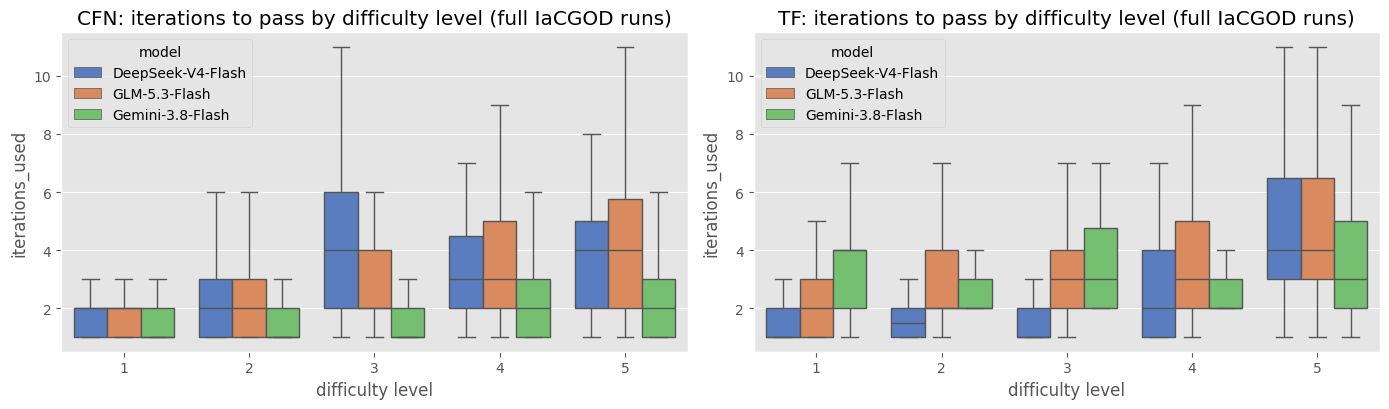

In [6]:
lv_it = runs[runs.passed].pivot_table(index="exp", columns="difficulty", values="iterations_used", aggfunc="mean").round(2)
lv_pr = runs.pivot_table(index="exp", columns="difficulty", values="passed", aggfunc="mean").mul(100).round(1)
for g, exps in GROUPS.items():
    print("\n==", g, "- mean iterations to pass by level  |  pass rate (%) by level")
    display(pd.concat([lv_it.loc[exps], lv_pr.loc[exps]], axis=1, keys=["iterations", "pass %"]).rename(index=LABEL))
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, lang in zip(axs, ("CFN", "TF")):
    d = runs[(runs.exp.isin(FULL[lang])) & runs.passed]
    sns.boxplot(data=d.assign(model=d.exp.map(LABEL)), x="difficulty", y="iterations_used", hue="model", ax=ax, showfliers=False)
    ax.set_title(f"{lang}: iterations to pass by difficulty level (full IaCGOD runs)"); ax.set_xlabel("difficulty level")
plt.tight_layout(); plt.savefig(FIG / "A_iters_by_level.png", dpi=150); plt.show()

## B. Resolve iterations per error class

In [7]:
CLASSES = ["syntax", "schema", "security", "deploy"]
def episodes(df):
    out = []
    for (e, rid), g in df.groupby(["exp", "run_id"], sort=False):
        it = g.iteration.values
        for cls in CLASSES:
            ran = g[f"{cls}_ran"].values; ok = g[f"{cls}_ok"].values
            fail = np.where(ran & ~ok)[0]
            if not len(fail): continue
            f0 = fail[0]; later = np.where(ran & ok & (np.arange(len(g)) > f0))[0]
            out.append((e, rid, cls, int(it[f0]), len(fail), len(later) > 0, (it[later[0]] - it[f0]) if len(later) else np.nan))
    return pd.DataFrame(out, columns=["exp", "run_id", "cls", "first_iter", "fail_iters", "resolved", "latency"])
ep = episodes(iters)
n_logs = iters.groupby("exp").run_id.nunique()
def ep_table(ep):
    g = ep.groupby(["exp", "cls"])
    t = pd.DataFrame({"runs_affected": g.size(), "resolved_%": g.resolved.mean() * 100, "mean_latency": g.latency.mean(), "median_latency": g.latency.median(),
                      "in_1_turn_%": g.apply(lambda x: 100 * (x.latency == 1).mean()), "mean_iters_failing": g.fail_iters.mean()}).round(2)
    t["share_of_runs_%"] = (t.runs_affected / t.index.get_level_values(0).map(n_logs) * 100).round(1)
    return t
tabB = ep_table(ep)
wide = tabB.unstack("cls").swaplevel(0, 1, axis=1)
for g, exps in GROUPS.items():
    print("\n==", g)
    cols = [(c, m) for c in CLASSES for m in ["share_of_runs_%", "resolved_%", "in_1_turn_%", "median_latency", "mean_latency"] if (c, m) in wide.columns]
    display(wide.loc[[x for x in exps if x in wide.index], cols].rename(index=LABEL))


== CFN main


cls                               syntax                                                             schema                                                           security                                        \
                         share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency   
exp                                                                                                                                                                                                                    
DeepSeek-V4-Flash                   19.2     100.00       81.25            1.0         1.29            60.4     100.00       72.85            1.0         1.37            28.8      98.61       76.39            1.0   
GLM-5.3-Flash                       18.0      95.56       88.89            1.0         1.07            65.6      98.78       70.12            1.0         1.46            24.4      96.72       72.13            1.0   
Gemini-3.8-Flash                     5.2     100.00      100.00            1.0         1.00            22.0     100.00       80.00            1.0         1.27            23.6     100.00       89.83            1.0   
Claude-Opus-5.5                      8.4     100.00      100.00            1.0         1.00            12.4     100.00      100.00            1.0         1.00            23.6      98.31       93.22            1.0   
OpenCode+DSV4F                       9.2     100.00       82.61            1.0         1.22            44.0      98.18       76.36            1.0         1.30            22.0     100.00       85.45            1.0   
Gemini-3.6-Flash (L3-5)              4.4     100.00      100.00            1.0         1.00            33.6     100.00       91.30            1.0         1.09            30.7     100.00       83.33            1.0   
DSV4F deploy-only (L3-5)            19.4     100.00       73.08            1.0         1.46            60.4     100.00       67.90            1.0         1.58             NaN        NaN         NaN            NaN   
o3-mini DPIaC-Eval                  39.9      96.72       86.89            1.0         1.19            46.4      98.59       71.83            1.0         1.41             0.7     100.00      100.00            1.0   

cls                                            deploy                                                     
                         mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency  
exp                                                                                                       
DeepSeek-V4-Flash                1.32            46.4      91.38       36.21            2.0         3.08  
GLM-5.3-Flash                    1.32            46.8      82.91       29.91            2.0         3.16  
Gemini-3.8-Flash                 1.10            26.0      96.92       56.92            1.0         2.08  
Claude-Opus-5.5                  1.05            14.4      91.67       61.11            1.0         1.52  
OpenCode+DSV4F                   1.16            36.4      81.32       39.56            2.0         2.14  
Gemini-3.6-Flash (L3-5)          1.19            36.5      98.00       50.00            1.0         2.31  
DSV4F deploy-only (L3-5)          NaN            53.7      86.11       27.78            2.0         3.39  
o3-mini DPIaC-Eval               1.00            51.0      83.33       37.18            2.0         2.80


== TF main


cls                                 syntax                                                             schema                                                           security                                        \
                           share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency   
exp                                                                                                                                                                                                                      
DeepSeek-V4-Flash                     39.6     100.00       55.56            1.0         1.89             NaN        NaN         NaN            NaN          NaN            25.6      98.44       90.62            1.0   
GLM-5.3-Flash                         51.6      99.22       50.39            1.0         2.02             NaN        NaN         NaN            NaN          NaN            23.6      98.31       83.05            1.0   
Gemini-3.8-Flash                      38.4     100.00       39.58            2.0         1.78             NaN        NaN         NaN            NaN          NaN            22.0     100.00       94.55            1.0   
Claude-Opus-5.5                        6.8     100.00       52.94            1.0         1.59             NaN        NaN         NaN            NaN          NaN            15.2     100.00       97.37            1.0   
OpenCode+DSV4F                        29.2     100.00       64.38            1.0         1.82             NaN        NaN         NaN            NaN          NaN            17.6      95.45       84.09            1.0   
DSV4F IaC-Eval (lint-only)            69.1      96.50       20.62            3.0         3.27             NaN        NaN         NaN            NaN          NaN             NaN        NaN         NaN            NaN   

cls                                              deploy                                                     
                           mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency  
exp                                                                                                         
DeepSeek-V4-Flash                  1.14            33.6      96.43       34.52            2.0         2.91  
GLM-5.3-Flash                      1.24            54.8      98.54       47.45            2.0         2.63  
Gemini-3.8-Flash                   1.07            94.0      99.57       77.87            1.0         1.38  
Claude-Opus-5.5                    1.03             6.0     100.00       53.33            1.0         2.73  
OpenCode+DSV4F                     1.26            21.2      88.68       41.51            2.0         2.32  
DSV4F IaC-Eval (lint-only)          NaN             NaN        NaN         NaN            NaN          NaN


== CFN ablation


cls                           syntax                                                             schema                                                           security                                        \
                     share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency   
exp                                                                                                                                                                                                                
IaCGOD                          14.0      100.0       100.0            1.0         1.00            62.0     100.00       80.65            1.0         1.42            38.0      94.74       89.47            1.0   
no dense RAG                     4.0      100.0        50.0            1.5         1.50            56.0     100.00       85.71            1.0         1.14            34.0      94.12       76.47            1.0   
OpenCode+Retriever              16.0      100.0        75.0            1.0         1.25            48.0      95.83       70.83            1.0         1.48            24.0      91.67       83.33            1.0   
no GraphRAG                      4.0      100.0        50.0            1.5         1.50            52.0     100.00       84.62            1.0         1.23            28.0     100.00       85.71            1.0   
no Planner                       NaN        NaN         NaN            NaN          NaN            38.0     100.00       89.47            1.0         1.11            24.0      91.67       83.33            1.0   
Trivy all severities             4.0      100.0       100.0            1.0         1.00            54.0     100.00       74.07            1.0         1.26            68.0      97.06       67.65            1.0   
no Remediator                    8.0      100.0       100.0            1.0         1.00            54.0     100.00       88.89            1.0         1.11            28.0      92.86       85.71            1.0   
no query rewrite                12.0      100.0       100.0            1.0         1.00            54.0     100.00       81.48            1.0         1.19            36.0      94.44       88.89            1.0   

cls                                        deploy                                                     
                     mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency  
exp                                                                                                   
IaCGOD                       1.06            30.0      100.0       66.67            1.0         2.40  
no dense RAG                 1.19            28.0      100.0       64.29            1.0         2.07  
OpenCode+Retriever           1.09            38.0      100.0       36.84            2.0         2.37  
no GraphRAG                  1.14             8.0      100.0       50.00            1.5         3.00  
no Planner                   1.09            10.0       80.0       40.00            1.5         2.25  
Trivy all severities         1.30            20.0      100.0       50.00            1.5         2.40  
no Remediator                1.08            20.0       90.0       30.00            2.0         1.89  
no query rewrite             1.06            20.0      100.0       40.00            3.0         3.10


== TF ablation


cls                           syntax                                                             schema                                                           security                                        \
                     share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency   
exp                                                                                                                                                                                                                
IaCGOD                          56.0     100.00       42.86            2.0         2.07             NaN        NaN         NaN            NaN          NaN            26.0      100.0       92.31            1.0   
no dense RAG                    65.3      96.88       31.25            2.0         2.77             NaN        NaN         NaN            NaN          NaN            34.7      100.0       88.24            1.0   
OpenCode+Retriever              40.8      95.00       65.00            1.0         1.42             NaN        NaN         NaN            NaN          NaN            22.4      100.0       90.91            1.0   
no GraphRAG                     42.0     100.00       76.19            1.0         1.24             NaN        NaN         NaN            NaN          NaN            22.0      100.0       90.91            1.0   
no Planner                      22.0     100.00       90.91            1.0         1.09             NaN        NaN         NaN            NaN          NaN            20.0      100.0       90.00            1.0   
Trivy all severities            60.0     100.00       66.67            1.0         1.57             NaN        NaN         NaN            NaN          NaN            82.0      100.0       36.59            2.0   
no Remediator                   44.0     100.00       81.82            1.0         1.41             NaN        NaN         NaN            NaN          NaN            24.0      100.0      100.00            1.0   
no query rewrite                36.0     100.00       72.22            1.0         1.33             NaN        NaN         NaN            NaN          NaN            30.0      100.0       93.33            1.0   

cls                                        deploy                                                     
                     mean_latency share_of_runs_% resolved_% in_1_turn_% median_latency mean_latency  
exp                                                                                                   
IaCGOD                       1.15            18.0     100.00       33.33            2.0         2.89  
no dense RAG                 1.47            28.6      92.86       50.00            1.0         2.46  
OpenCode+Retriever           1.09            22.4      90.91       81.82            1.0         1.20  
no GraphRAG                  1.09            28.0      85.71       64.29            1.0         2.17  
no Planner                   1.10            20.0      90.00       80.00            1.0         1.33  
Trivy all severities         2.32            26.0      92.31       84.62            1.0         1.25  
no Remediator                1.00            30.0      93.33       60.00            1.0         2.00  
no query rewrite             1.07            26.0      92.31       84.62            1.0         1.08

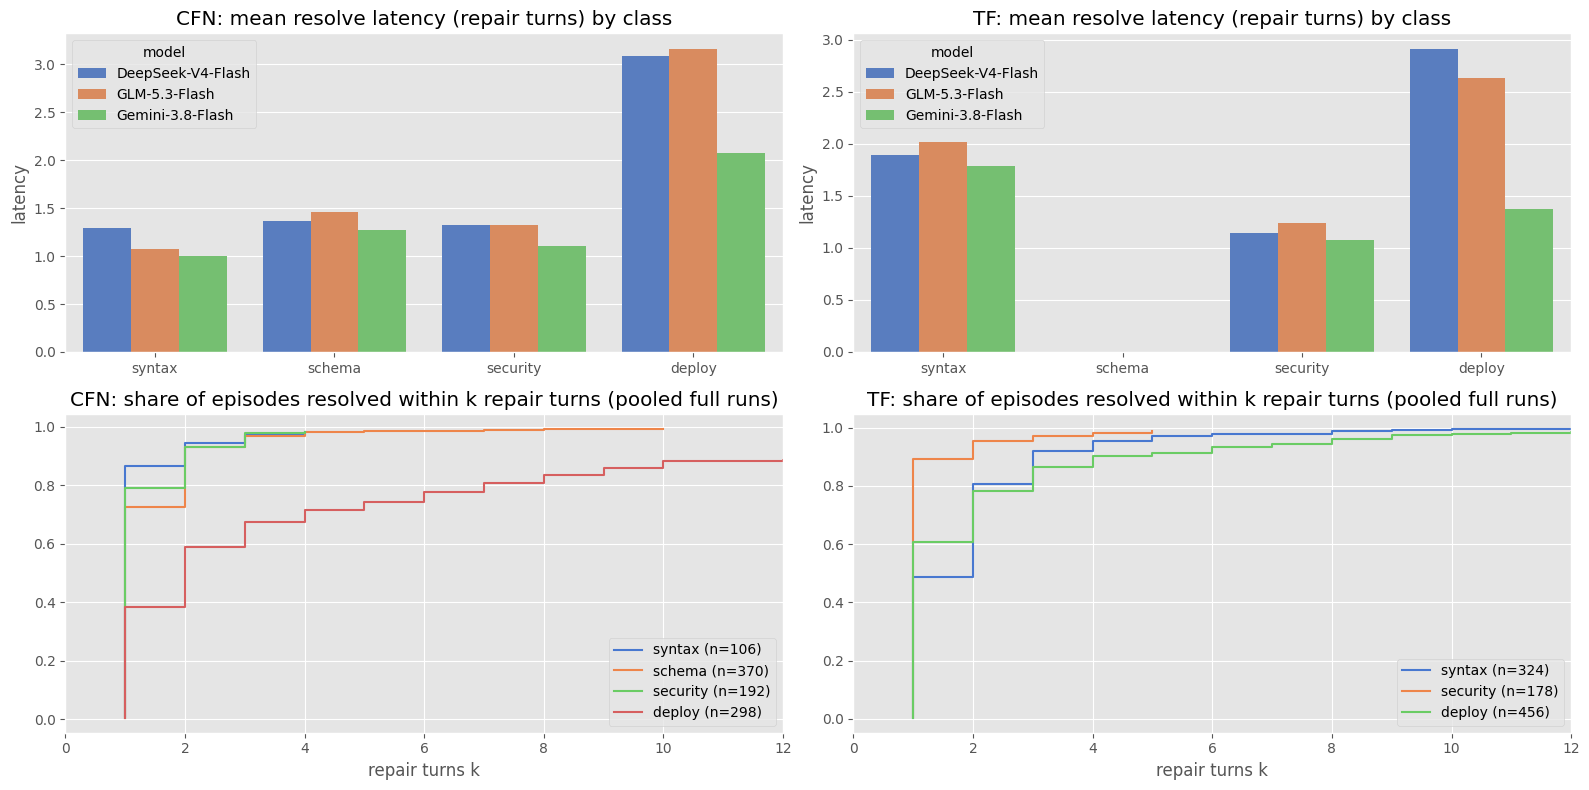

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8))
for ax, lang in zip(axs[0], ("CFN", "TF")):
    d = ep[ep.exp.isin(FULL[lang])].assign(model=lambda x: x.exp.map(LABEL))
    sns.barplot(data=d, x="cls", y="latency", hue="model", order=CLASSES, ax=ax, errorbar=None)
    ax.set_title(f"{lang}: mean resolve latency (repair turns) by class"); ax.set_xlabel("")
for ax, lang in zip(axs[1], ("CFN", "TF")):
    d = ep[ep.exp.isin(FULL[lang])]
    for cls in CLASSES:
        x = np.sort(d[d.cls == cls].latency.dropna().values)
        if len(x): ax.step(x, np.arange(1, len(x) + 1) / (d.cls == cls).sum(), where="post", label=f"{cls} (n={(d.cls == cls).sum()})")
    ax.set_xlim(0, 12); ax.set_title(f"{lang}: share of episodes resolved within k repair turns (pooled full runs)"); ax.set_xlabel("repair turns k"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "B_resolve_latency.png", dpi=150); plt.show()

## C. Error regressions

In [9]:
def turn_table(df):
    out = []
    for (e, rid), g in df.groupby(["exp", "run_id"], sort=False):
        recs = g.to_dict("records"); seen = set()
        def keys(r, other):
            ks = set()
            for c in ("syntax", "schema", "security"):
                if r[f"{c}_ran"] and other[f"{c}_ran"]:
                    ks |= {f"{c}:{k}" for k in str(r.get(f"{c}_keys") or "").split("|") if k}
            if r["deploy_ran"] and not r["deploy_ok"] and r.get("deploy_keys"):
                ks.add(f"deploy:{r['deploy_keys']}")
            return ks
        for k in range(len(recs) - 1):
            a, b = recs[k], recs[k + 1]
            Ka, Kb = keys(a, b), keys(b, a)
            all_a = {f"{c}:{k}" for c in ("syntax", "schema", "security") for k in str(a.get(f"{c}_keys") or "").split("|") if k}
            if a["deploy_ran"] and not a["deploy_ok"] and a.get("deploy_keys"): all_a.add(f"deploy:{a['deploy_keys']}")
            seen |= all_a
            if not (a["deploy_ran"] and b["deploy_ran"]):
                Ka_cmp = {x for x in Ka if not x.startswith("deploy:")}; Kb_cmp = {x for x in Kb if not x.startswith("deploy:")}
            else:
                Ka_cmp, Kb_cmp = Ka, Kb
            fixed, intro = Ka_cmp - Kb_cmp, Kb_cmp - Ka_cmp
            fixed_cls = [c for c in CLASSES if ((a[f"{c}_ran"] and not a[f"{c}_ok"]) and (b[f"{c}_ran"] and b[f"{c}_ok"]))]
            reg_cls = [c for c in ("syntax", "schema", "security") if a[f"{c}_ran"] and a[f"{c}_ok"] and b[f"{c}_ran"] and not b[f"{c}_ok"]]
            out.append(dict(exp=e, run_id=rid, i=a["iteration"], n_a=len(all_a), n_b=len(Kb_cmp), fixed=len(fixed), introduced=len(intro),
                            recurrent=len({x for x in intro if x in seen}), fixed_cls="+".join(fixed_cls), reg_cls="+".join(reg_cls),
                            no_progress=bool(Ka_cmp) and Ka_cmp == Kb_cmp, ctx_tokens=a.get("ctx_tokens"), n_queries=a.get("n_queries"),
                            ctx_cover=a.get("ctx_covers_failing_type"), has_turn=a.get("has_turn")))
    return pd.DataFrame(out)
turns = turn_table(iters[iters.iteration.notna()])
turns["lang"] = turns.exp.map(lang_of)
fail_turns = turns[turns.n_a > 0]
g = fail_turns.groupby("exp")
tabC = pd.DataFrame({
    "repair_turns": g.size(),
    "fixed/turn": g.fixed.mean(), "introduced/turn": g.introduced.mean(),
    "turns_with_new_error_%": g.apply(lambda x: 100 * (x.introduced > 0).mean()),
    "class_regression_%": g.apply(lambda x: 100 * (x.reg_cls != "").mean()),
    "recurrence_share_%": g.apply(lambda x: 100 * x.recurrent.sum() / max(1, x.introduced.sum())),
    "no_progress_%": g.apply(lambda x: 100 * x.no_progress.mean()),
}).round(2)
run_reg = fail_turns.assign(r=fail_turns.reg_cls != "").groupby(["exp", "run_id"]).r.any().groupby("exp").mean().mul(100).round(1)
tabC["runs_with_regression_%"] = run_reg
for gname, exps in GROUPS.items():
    print("\n==", gname); display(tabC.loc[[x for x in exps if x in tabC.index]].rename(index=LABEL))


== CFN main


,repair_turns,fixed/turn,introduced/turn,turns_with_new_error_%,class_regression_%,recurrence_share_%,no_progress_%,runs_with_regression_%
exp,,,,,,,,
DeepSeek-V4-Flash,764,0.95,0.36,32.33,6.94,18.48,19.50,17.2
GLM-5.3-Flash,878,0.81,0.36,29.04,8.31,15.65,30.87,25.5
Gemini-3.8-Flash,275,0.93,0.26,22.55,8.36,14.08,17.09,17.3
Claude-Opus-5.5,192,0.91,0.11,10.94,2.60,14.29,26.04,5.2
OpenCode+DSV4F,489,0.91,0.25,22.29,4.29,12.50,21.88,10.8
Gemini-3.6-Flash (L3-5),215,0.92,0.28,24.19,6.05,9.84,14.42,11.7
DSV4F deploy-only (L3-5),449,0.85,0.39,34.97,6.68,18.39,27.62,24.0
o3-mini DPIaC-Eval,493,0.79,0.38,35.70,9.33,23.40,24.95,22.4



== TF main


,repair_turns,fixed/turn,introduced/turn,turns_with_new_error_%,class_regression_%,recurrence_share_%,no_progress_%,runs_with_regression_%
exp,,,,,,,,
DeepSeek-V4-Flash,518,0.97,0.42,34.75,3.86,20.74,16.22,10.7
GLM-5.3-Flash,714,0.88,0.40,33.19,6.02,21.48,18.77,16.7
Gemini-3.8-Flash,556,0.88,0.19,18.17,4.32,19.05,12.59,9.3
Claude-Opus-5.5,106,0.90,0.20,19.81,0.94,14.29,15.09,1.7
OpenCode+DSV4F,375,0.93,0.35,30.40,5.60,30.00,16.27,12.2
DSV4F IaC-Eval (lint-only),935,0.61,0.30,22.46,0.00,18.51,50.48,0.0



== CFN ablation


,repair_turns,fixed/turn,introduced/turn,turns_with_new_error_%,class_regression_%,recurrence_share_%,no_progress_%,runs_with_regression_%
exp,,,,,,,,
IaCGOD,114,0.96,0.21,18.42,7.89,20.83,15.79,10.8
no dense RAG,90,0.93,0.17,14.44,8.89,20.00,20.00,18.8
OpenCode+Retriever,111,0.88,0.21,12.61,3.60,0.00,29.73,11.1
no GraphRAG,59,1.20,0.20,16.95,6.78,8.33,6.78,9.7
no Planner,68,0.88,0.15,13.24,10.29,50.00,27.94,11.1
Trivy all severities,110,1.24,0.26,24.55,10.00,17.24,10.00,15.4
no Remediator,84,1.06,0.19,16.67,10.71,37.50,17.86,11.4
no query rewrite,94,1.03,0.17,15.96,8.51,31.25,21.28,8.3



== TF ablation


,repair_turns,fixed/turn,introduced/turn,turns_with_new_error_%,class_regression_%,recurrence_share_%,no_progress_%,runs_with_regression_%
exp,,,,,,,,
IaCGOD,96,0.96,0.30,26.04,4.17,6.90,17.71,8.6
no dense RAG,161,0.64,0.21,20.50,6.21,29.41,36.65,16.7
OpenCode+Retriever,55,1.09,0.18,14.55,3.64,10.00,10.91,6.7
no GraphRAG,87,0.69,0.16,16.09,9.20,28.57,27.59,13.3
no Planner,46,1.04,0.22,21.74,10.87,30.00,6.52,13.0
Trivy all severities,150,1.03,0.32,30.00,9.33,8.33,13.33,26.1
no Remediator,75,0.99,0.23,22.67,6.67,47.06,14.67,15.2
no query rewrite,64,1.03,0.16,14.06,3.12,20.00,14.06,6.7


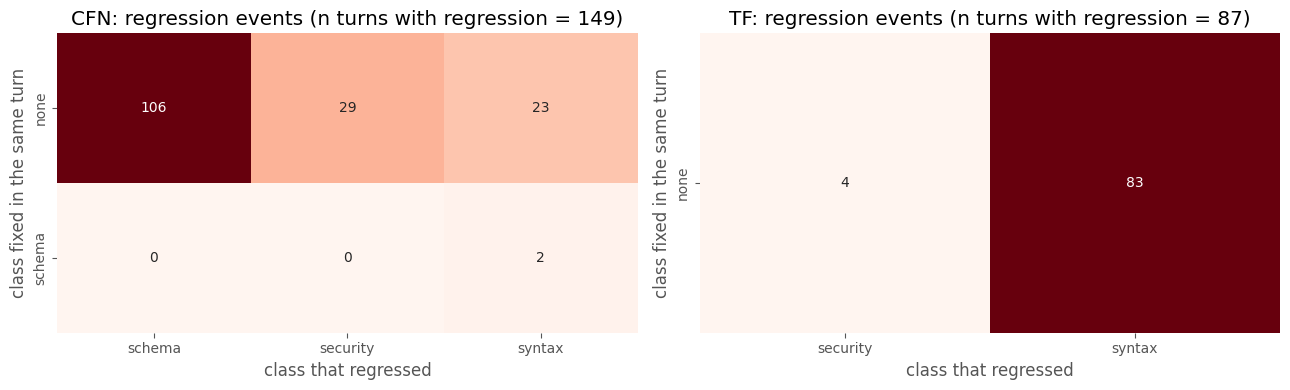


CFN: errors that reappeared after being absent (top 12; total 157)


,reappearances
error,
schema:E3002,38
security:AWS-0015,29
syntax:yaml-syntax,19
schema:E0000,14
schema:E3003,7
schema:E3004,7
schema:E1017,6
schema:E3012,5
security:AWS-0013,4



TF: errors that reappeared after being absent (top 12; total 181)


,reappearances
error,
syntax:init: Failed to install provider,57
syntax:Unsupported argument,34
syntax:init: Invalid character,17
syntax:init: Unsupported block type,9
syntax:Missing required argument,8
syntax:init: Argument or block definition required,7
syntax:init: Invalid block definition,6
syntax:init: Missing newline after argument,6
syntax:Unsupported block type,5


In [10]:
REG_MATRICES = {}
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, lang in zip(axs, ("CFN", "TF")):
    t = fail_turns[fail_turns.exp.isin(FULL[lang]) & (fail_turns.reg_cls != "")]
    rows = []
    for _, r in t.iterrows():
        for rc in r.reg_cls.split("+"):
            for fc in (r.fixed_cls.split("+") if r.fixed_cls else ["none"]):
                rows.append((fc, rc))
    m = pd.crosstab(pd.Series([a for a, b in rows], name="class fixed in the same turn"), pd.Series([b for a, b in rows], name="class that regressed"))
    REG_MATRICES[lang] = m
    sns.heatmap(m, annot=True, fmt="d", cmap="Reds", ax=ax, cbar=False); ax.set_title(f"{lang}: regression events (n turns with regression = {len(t)})")
plt.tight_layout(); plt.savefig(FIG / "C_regression_matrix.png", dpi=150); plt.show()
rec = []
for (e, rid), g in iters.groupby(["exp", "run_id"], sort=False):
    prev = None; seen = set()
    for r in g.to_dict("records"):
        ks = set()
        for c in ("syntax", "schema", "security"):
            ks |= {f"{c}:{k}" for k in str(r.get(f"{c}_keys") or "").split("|") if k}
        if prev is not None:
            for k in (ks - prev) & seen: rec.append((lang_of(e), k))
        seen |= ks; prev = ks
rec = pd.DataFrame(rec, columns=["lang", "error"])
for lang in ("CFN", "TF"):
    print(f"\n{lang}: errors that reappeared after being absent (top 12; total {int((rec.lang == lang).sum())})")
    display(rec[rec.lang == lang].error.value_counts().head(12).to_frame("reappearances"))

In [11]:
def failing_at(r):
    f = [c for c in ("syntax", "schema", "security") if r[f"{c}_ran"] and not r[f"{c}_ok"]]
    if r["deploy_ran"] and not r["deploy_ok"]: f.append("deploy")
    return "+".join(f) or "none"
_it = iters.set_index(["exp", "run_id", "iteration"])
REG_FROM = {}
for lang in ("CFN", "TF"):
    t = fail_turns[fail_turns.exp.isin(FULL[lang]) & (fail_turns.reg_cls != "")]
    rows = []
    for _, r in t.iterrows():
        fa = failing_at(_it.loc[(r.exp, r.run_id, r.i)])
        for rc in r.reg_cls.split("+"):
            rows.append((fa, rc))
    m = pd.crosstab(pd.Series([a for a, b in rows], name="class failing at i"), pd.Series([b for a, b in rows], name="class that regressed"))
    REG_FROM[lang] = m
    tot = fail_turns[fail_turns.exp.isin(FULL[lang])]
    print(f"\n{lang}: {len(t)} repair turns with a class regression of {len(tot)} repair turns"); display(m)


CFN: 149 repair turns with a class regression of 1917 repair turns


class that regressed,schema,security,syntax
class failing at i,,,
deploy,69,29,10
schema,0,0,14
security,37,0,1



TF: 87 repair turns with a class regression of 1788 repair turns


class that regressed,security,syntax
class failing at i,,
deploy,4,72
security,0,11


## D. Retrieved context

In [12]:
tt = turns[(turns.has_turn == True)]
g = tt.groupby("exp")
run_ctx = tt.groupby(["exp", "run_id"]).ctx_tokens.sum().rename("ctx_total").reset_index().merge(
    runs[["exp", "run_id", "token_all_tokens"]], on=["exp", "run_id"])
run_ctx["share_%"] = 100 * run_ctx.ctx_total / run_ctx.token_all_tokens
hit = tt[tt.ctx_cover.notna()].groupby("exp").ctx_cover.mean().mul(100)
tabD = pd.DataFrame({"turns_with_retrieval": g.size(), "ctx_tokens_median": g.ctx_tokens.median(), "ctx_tokens_mean": g.ctx_tokens.mean().round(0),
                     "ctx_tokens_p90": g.ctx_tokens.quantile(.9), "queries/turn": g.n_queries.mean().round(2),
                     "ctx_share_of_run_tokens_median_%": run_ctx.groupby("exp")["share_%"].median().round(2), "ctx_covers_failing_type_%": hit.round(1)})
for gname, exps in GROUPS.items():
    d = tabD.loc[[x for x in exps if x in tabD.index]]
    if len(d): print("\n==", gname); display(d.rename(index=LABEL))


== CFN main


,turns_with_retrieval,ctx_tokens_median,ctx_tokens_mean,ctx_tokens_p90,queries/turn,ctx_share_of_run_tokens_median_%,ctx_covers_failing_type_%
exp,,,,,,,
DeepSeek-V4-Flash,764,469.5,805.0,1638.6,3.19,1.81,88.813559
GLM-5.3-Flash,878,482.0,786.0,1957.3,3.51,1.71,86.0
Gemini-3.8-Flash,275,401.0,604.0,1221.6,2.51,1.64,77.435897
Claude-Opus-5.5,192,460.0,875.0,2153.7,3.61,3.85,53.921569
Gemini-3.6-Flash (L3-5),215,408.0,601.0,1122.0,1.67,1.91,74.850299
DSV4F deploy-only (L3-5),449,514.0,756.0,1513.2,3.86,1.42,96.111111
o3-mini DPIaC-Eval,493,504.0,791.0,1988.4,1.87,2.57,91.383812



== TF main


,turns_with_retrieval,ctx_tokens_median,ctx_tokens_mean,ctx_tokens_p90,queries/turn,ctx_share_of_run_tokens_median_%,ctx_covers_failing_type_%
exp,,,,,,,
DeepSeek-V4-Flash,525,1062.0,1818.0,4376.4,3.02,2.78,68.231047
GLM-5.3-Flash,714,1098.0,1885.0,4375.2,2.45,4.77,73.289902
Gemini-3.8-Flash,556,1517.5,1889.0,4222.0,1.41,5.40,47.747748
Claude-Opus-5.5,106,942.0,1378.0,3096.0,3.32,4.00,45.205479
DSV4F IaC-Eval (lint-only),936,1993.0,2370.0,4491.0,1.43,8.25,NaN



== CFN ablation


,turns_with_retrieval,ctx_tokens_median,ctx_tokens_mean,ctx_tokens_p90,queries/turn,ctx_share_of_run_tokens_median_%,ctx_covers_failing_type_%
exp,,,,,,,
IaCGOD,114,465.5,803.0,1294.6,3.53,1.24,78.75
no dense RAG,90,341.5,757.0,1176.4,4.24,0.84,80.769231
no GraphRAG,59,144.0,238.0,577.0,4.29,0.36,76.923077
no Planner,68,558.5,802.0,1142.2,4.47,1.40,79.487179
Trivy all severities,110,532.5,871.0,1401.7,4.00,1.26,73.770492
no Remediator,84,577.0,1132.0,3324.9,4.44,1.66,83.72093
no query rewrite,94,423.0,837.0,1817.9,1.84,1.00,79.245283



== TF ablation


,turns_with_retrieval,ctx_tokens_median,ctx_tokens_mean,ctx_tokens_p90,queries/turn,ctx_share_of_run_tokens_median_%,ctx_covers_failing_type_%
exp,,,,,,,
IaCGOD,96,1678.5,2340.0,5789.5,2.82,4.68,26.315789
no dense RAG,161,2766.0,3305.0,6453.0,4.57,4.00,27.586207
no GraphRAG,87,205.0,297.0,619.0,5.09,0.32,47.058824
no Planner,46,1761.5,2639.0,5714.5,4.80,2.94,45.0
Trivy all severities,150,854.0,1820.0,4740.3,3.09,2.88,18.27957
no Remediator,75,1597.0,2347.0,6272.2,4.52,3.54,53.125
no query rewrite,64,1481.5,2558.0,6308.4,1.52,3.39,53.125


,lang,turn type,turns,turns with >=1 error fixed %,new errors introduced/turn
0,CFN,context size: small (tokens 7-312),1296,63.50,0.25
1,CFN,context size: medium (tokens 313-690),1294,71.25,0.27
2,CFN,context size: large (tokens 692-8590),1295,73.98,0.43
3,CFN,context covers a failing resource type: False,408,75.74,0.16
4,CFN,context covers a failing resource type: True,2356,71.73,0.32
5,TF,context size: small (tokens 9-834),1170,75.21,0.31
6,TF,context size: medium (tokens 836-2382),1168,67.72,0.31
7,TF,context size: large (tokens 2385-14716),1170,66.15,0.29
8,TF,context covers a failing resource type: False,438,84.02,0.14
9,TF,context covers a failing resource type: True,589,72.84,0.50


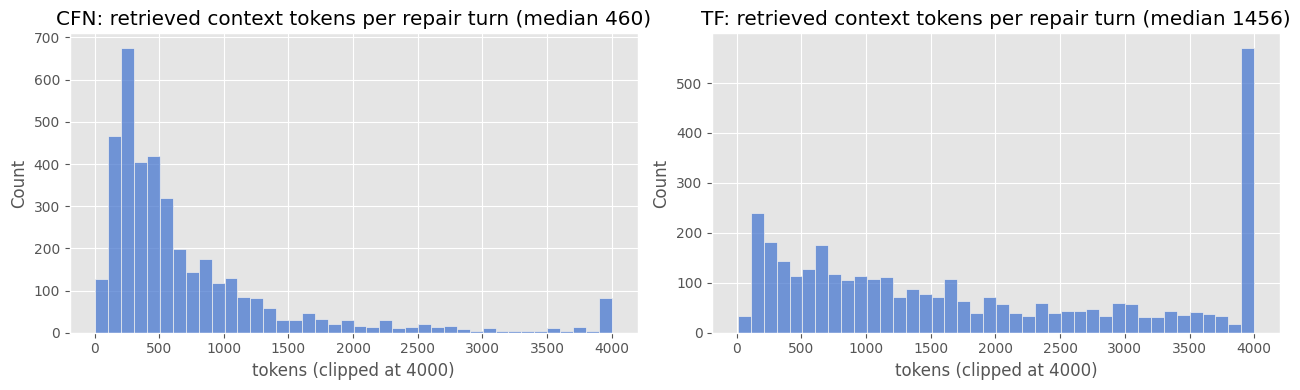

In [13]:
tt2 = tt[tt.n_a > 0].copy(); tt2["progress"] = (tt2.fixed > 0)
tt2["ctx_bucket"] = tt2.groupby("lang").ctx_tokens.transform(lambda s: pd.qcut(s, 3, labels=["small", "medium", "large"], duplicates="drop"))
res = []
for lang in ("CFN", "TF"):
    d = tt2[tt2.lang == lang]
    for b, x in d.groupby("ctx_bucket"): res.append((lang, f"context size: {b} (tokens {int(x.ctx_tokens.min())}-{int(x.ctx_tokens.max())})", len(x), 100 * x.progress.mean(), x.introduced.mean()))
    for h, x in d[d.ctx_cover.notna()].groupby("ctx_cover"): res.append((lang, f"context covers a failing resource type: {bool(h)}", len(x), 100 * x.progress.mean(), x.introduced.mean()))
effD = pd.DataFrame(res, columns=["lang", "turn type", "turns", "turns with >=1 error fixed %", "new errors introduced/turn"]).round(2)
display(effD)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, lang in zip(axs, ("CFN", "TF")):
    d = tt[tt.lang == lang]
    sns.histplot(d.ctx_tokens.clip(upper=4000), bins=40, ax=ax); ax.set_title(f"{lang}: retrieved context tokens per repair turn (median {d.ctx_tokens.median():.0f})"); ax.set_xlabel("tokens (clipped at 4000)")
plt.tight_layout(); plt.savefig(FIG / "D_context_tokens.png", dpi=150); plt.show()

## E. Over-provisioning


== CFN main


,scenarios,required/scen,generated/scen,extra/scen,missing/scen,over_ratio_mean,scenarios_with_extra_%,extra_share_%,coverage_%,accuracy_%
exp,,,,,,,,,,
DeepSeek-V4-Flash,250,10.46,11.50,2.48,1.43,1.27,50.80,21.53,86.37,81.06
GLM-5.3-Flash,250,10.46,11.60,2.46,1.32,1.27,55.20,21.21,85.40,79.28
Gemini-3.8-Flash,250,10.46,11.05,1.98,1.38,1.18,47.60,17.89,87.20,84.22
Claude-Opus-5.5,250,10.46,12.93,3.51,1.04,1.40,54.40,27.17,89.95,79.34
OpenCode+DSV4F,250,10.46,11.12,2.13,1.46,1.16,47.20,19.17,86.34,84.69
Gemini-3.6-Flash (L3-5),137,14.82,14.79,2.04,2.07,1.03,53.28,13.82,84.25,86.47
DSV4F deploy-only (L3-5),134,14.97,16.40,3.54,2.12,1.12,60.45,21.62,83.72,82.07
o3-mini DPIaC-Eval,153,7.08,7.99,2.08,1.17,1.50,56.86,26.02,87.54,79.03



== TF main


,scenarios,required/scen,generated/scen,extra/scen,missing/scen,over_ratio_mean,scenarios_with_extra_%,extra_share_%,coverage_%,accuracy_%
exp,,,,,,,,,,
DeepSeek-V4-Flash,250,10.67,12.41,3.78,2.04,1.61,62.80,30.45,87.51,76.43
GLM-5.3-Flash,250,10.67,12.09,3.31,1.89,1.34,61.60,27.39,88.11,79.71
Gemini-3.8-Flash,250,10.67,11.84,2.81,1.64,1.31,51.60,23.75,90.13,82.75
Claude-Opus-5.5,250,10.67,13.29,4.29,1.67,1.49,64.00,32.29,89.78,76.75
OpenCode+DSV4F,250,10.67,11.04,2.50,2.12,1.20,51.20,22.60,85.86,83.13
DSV4F IaC-Eval (lint-only),372,4.73,9.66,6.00,1.06,2.67,81.45,62.06,86.01,49.11



== CFN ablation


,scenarios,required/scen,generated/scen,extra/scen,missing/scen,over_ratio_mean,scenarios_with_extra_%,extra_share_%,coverage_%,accuracy_%
exp,,,,,,,,,,
IaCGOD,50,13.78,16.38,4.38,1.78,1.26,64.0,26.74,85.96,78.43
no dense RAG,50,13.78,16.60,4.60,1.78,1.27,62.0,27.71,86.33,77.92
OpenCode+Retriever,50,13.78,14.88,2.88,1.78,1.14,54.0,19.35,84.77,83.13
no GraphRAG,50,13.78,17.34,5.10,1.54,1.30,66.0,29.41,86.64,76.53
no Planner,50,13.78,15.86,3.74,1.66,1.16,60.0,23.58,87.17,81.03
Trivy all severities,50,13.78,17.94,5.68,1.52,1.53,74.0,31.66,87.80,73.07
no Remediator,50,13.78,15.78,3.78,1.78,1.25,68.0,23.95,87.13,78.81
no query rewrite,50,13.78,17.52,5.92,2.18,1.66,72.0,33.79,84.26,73.88



== TF ablation


,scenarios,required/scen,generated/scen,extra/scen,missing/scen,over_ratio_mean,scenarios_with_extra_%,extra_share_%,coverage_%,accuracy_%
exp,,,,,,,,,,
IaCGOD,50,13.22,15.96,5.04,2.30,1.36,60.00,31.58,84.56,75.97
no dense RAG,49,13.10,18.20,7.10,2.00,1.66,73.47,39.01,86.27,71.33
OpenCode+Retriever,50,13.22,16.32,4.92,1.82,1.30,62.00,30.15,85.80,78.11
no GraphRAG,50,13.22,18.12,6.72,1.82,1.61,68.00,37.09,87.14,71.93
no Planner,50,13.22,15.42,4.16,1.96,1.38,54.00,26.98,86.83,81.07
Trivy all severities,50,13.22,24.24,12.78,1.76,2.40,86.00,52.72,88.32,56.14
no Remediator,50,13.22,17.66,5.86,1.42,1.57,64.00,33.18,90.08,77.24
no query rewrite,50,13.22,17.46,6.28,2.04,1.52,78.00,35.97,84.88,68.01



extra resources per scenario by difficulty level


difficulty,1,2,3,4,5,6
exp,,,,,,
IaCGOD,2.67,0.43,5.50,2.38,7.18,NaN
no dense RAG,2.00,1.57,3.90,3.15,7.82,NaN
no GraphRAG,0.67,2.86,5.60,3.85,7.47,NaN
no Planner,1.67,0.57,3.70,1.62,7.06,NaN
no query rewrite,12.33,1.43,6.30,2.38,9.12,NaN
no Remediator,2.00,2.00,4.40,2.85,5.18,NaN
OpenCode+Retriever,4.00,0.14,3.00,1.77,4.59,NaN
Trivy all severities,10.67,0.43,6.90,3.92,7.59,NaN
o3-mini DPIaC-Eval,1.88,1.59,1.90,3.42,2.19,NaN


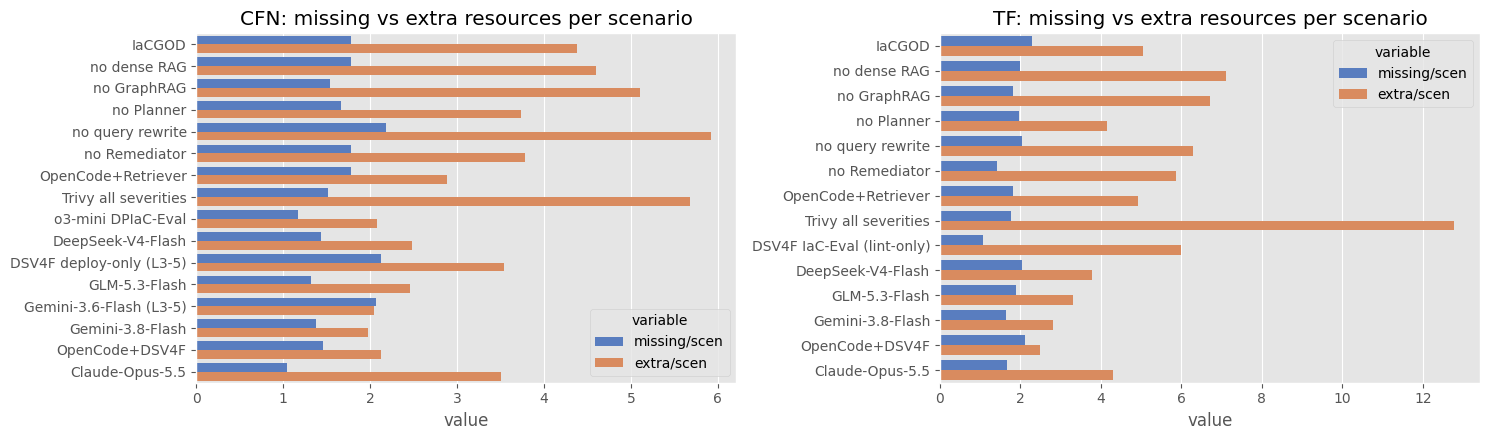

In [14]:
cov = runs[runs.req.notna()].copy()
cov["over_ratio"] = cov.gen / cov.req.replace(0, np.nan)
g = cov.groupby("exp")
tabE = pd.DataFrame({"scenarios": g.size(), "required/scen": g.req.mean(), "generated/scen": g.gen.mean(), "extra/scen": g.extra.mean(), "missing/scen": g.missing.mean(),
                     "over_ratio_mean": g.over_ratio.mean(), "scenarios_with_extra_%": g.apply(lambda x: 100 * (x.extra > 0).mean()),
                     "extra_share_%": g.apply(lambda x: 100 * x.extra.sum() / max(1, x.gen.sum())), "coverage_%": g.cov_pct.mean(), "accuracy_%": g.acc_pct.mean()}).round(2)
for gname, exps in GROUPS.items():
    print("\n==", gname); display(tabE.loc[[x for x in exps if x in tabE.index]].rename(index=LABEL))
lv = cov.pivot_table(index="exp", columns="difficulty", values="extra", aggfunc="mean").round(2)
print("\nextra resources per scenario by difficulty level"); display(lv.rename(index=LABEL))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, lang in zip(axs, ("CFN", "TF")):
    d = tabE[tabE.index.map(lang_of) == lang].rename(index=LABEL).reset_index().rename(columns={"exp": "run"})
    d2 = d.melt(id_vars="run", value_vars=["missing/scen", "extra/scen"])
    sns.barplot(data=d2, y="run", x="value", hue="variable", ax=ax); ax.set_title(f"{lang}: missing vs extra resources per scenario"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "E_over_provisioning.png", dpi=150); plt.show()

In [15]:
def top_types(col, exps, n=12):
    s = cov[cov.exp.isin(exps)][col].dropna().astype(str).str.split(";").explode()
    s = s[s != ""]
    return s.value_counts().head(n)
for lang in ("CFN", "TF"):
    print(f"\n{lang}: top extra types | top missing types (full IaCGOD runs)")
    display(pd.concat([top_types("extra_types", FULL[lang]).rename("extra"), top_types("missing_types", FULL[lang]).rename("missing")], axis=1))
for lang in ("CFN", "TF"):
    a = top_types("extra_types", [f"{lang}_Ablation_IaCGOD"], 400); b = top_types("extra_types", [f"{lang}_Ablation_TrivyAllSeverities"], 400)
    d = pd.concat([a.rename("IaCGOD"), b.rename("Trivy all severities")], axis=1).fillna(0)
    d["delta"] = d["Trivy all severities"] - d["IaCGOD"]
    print(f"\n{lang}: extra types that grow most when all Trivy severities must be clean (ablation, 50 scenarios)"); display(d.sort_values("delta", ascending=False).head(8))


CFN: top extra types | top missing types (full IaCGOD runs)


,extra,missing
AWS::Route53::RecordSet,243.0,NaN
AWS::IAM::Role,134.0,112.0
AWS::Lambda::Function,103.0,NaN
AWS::KMS::Key,91.0,NaN
AWS::S3::BucketPolicy,73.0,NaN
AWS::KMS::Alias,72.0,NaN
AWS::SSM::Parameter,66.0,NaN
AWS::S3::Bucket,57.0,NaN
AWS::Logs::LogGroup,46.0,NaN
AWS::Lambda::Permission,39.0,NaN



TF: top extra types | top missing types (full IaCGOD runs)


,extra,missing
aws_route_table_association,156.0,112.0
aws_kms_alias,155.0,NaN
aws_subnet,150.0,105.0
aws_s3_bucket_versioning,144.0,NaN
aws_s3_bucket_server_side_encryption_configuration,124.0,NaN
aws_iam_role_policy_attachment,122.0,97.0
aws_iam_role_policy,101.0,32.0
aws_s3_bucket_public_access_block,96.0,NaN
aws_route_table,93.0,27.0
aws_s3_bucket,92.0,NaN



CFN: extra types that grow most when all Trivy severities must be clean (ablation, 50 scenarios)


,IaCGOD,Trivy all severities,delta
extra_types,,,
AWS::KMS::Key,5.0,27.0,22.0
AWS::KMS::Alias,8.0,24.0,16.0
AWS::EC2::NetworkAclEntry,6.0,18.0,12.0
AWS::IAM::Role,9.0,19.0,10.0
AWS::S3::Bucket,5.0,13.0,8.0
AWS::S3::BucketPolicy,7.0,15.0,8.0
AWS::EC2::FlowLog,0.0,7.0,7.0
AWS::EC2::VPCEndpoint,4.0,9.0,5.0



TF: extra types that grow most when all Trivy severities must be clean (ablation, 50 scenarios)


,IaCGOD,Trivy all severities,delta
extra_types,,,
aws_kms_key,5.0,34.0,29.0
aws_iam_role,2.0,29.0,27.0
aws_kms_alias,10.0,36.0,26.0
aws_s3_bucket_ownership_controls,3.0,29.0,26.0
aws_s3_bucket_logging,1.0,25.0,24.0
aws_cloudwatch_log_group,2.0,26.0,24.0
aws_flow_log,0.0,21.0,21.0
aws_s3_bucket_versioning,20.0,41.0,21.0


In [16]:
import json as _json
ip = iters[iters.template_parsed == True].sort_values(["exp", "run_id", "iteration"])
f = ip.groupby(["exp", "run_id"]).agg(first=("n_resources", "first"), last=("n_resources", "last"), n=("iteration", "size"),
                                         t_first=("res_types", "first"), t_last=("res_types", "last"))
f = f[f.n >= 2].reset_index(); f["delta"] = f["last"] - f["first"]
sec_runs = set(ep[ep.cls == "security"].run_id)
f["had_security_issue"] = f.run_id.isin(sec_runs)
tabE2 = f.groupby("exp").agg(runs=("delta", "size"), mean_first=("first", "mean"), mean_last=("last", "mean"), mean_delta=("delta", "mean"),
                              grew_pct=("delta", lambda x: 100 * (x > 0).mean()), shrank_pct=("delta", lambda x: 100 * (x < 0).mean())).round(2)
d_sec = f.groupby(["exp", "had_security_issue"]).delta.mean().unstack().round(2).rename(columns={False: "delta (no security issue)", True: "delta (security issue)"})
display(pd.concat([tabE2, d_sec], axis=1).rename(index=LABEL))
from collections import Counter
for lang in ("CFN", "TF"):
    add, rem = Counter(), Counter()
    for r in f[f.exp.isin(FULL[lang])].itertuples():
        a, b = Counter(_json.loads(r.t_first)), Counter(_json.loads(r.t_last))
        for k in set(a) | set(b):
            d = b[k] - a[k]
            if d > 0: add[k] += d
            elif d < 0: rem[k] += -d
    print(f"\n{lang}: resource types added by the repair loop (instances) | removed")
    display(pd.concat([pd.Series(dict(add.most_common(10)), name="added"), pd.Series(dict(rem.most_common(10)), name="removed")], axis=1).fillna(0).astype(int))
last = iters[iters.template_parsed == True].sort_values("iteration").groupby(["exp", "run_id"]).n_resources.last().rename("parsed_n").reset_index()
chk = runs[["exp", "run_id", "gen"]].merge(last, on=["exp", "run_id"]).dropna()
print("correlation of the parsed resource count with the coverage tool's generated count:", round(chk.gen.corr(chk.parsed_n), 3), "on", len(chk), "runs;",
      "exact match in", round(100 * (chk.gen == chk.parsed_n).mean(), 1), "%")

,runs,mean_first,mean_last,mean_delta,grew_pct,shrank_pct,delta (no security issue),delta (security issue)
exp,,,,,,,,
IaCGOD,37,16.68,17.95,1.27,37.84,5.41,0.39,2.11
no dense RAG,32,20.00,21.06,1.06,37.50,9.38,0.40,1.65
no GraphRAG,31,17.77,19.23,1.45,38.71,3.23,-0.18,3.43
no Planner,27,18.96,19.96,1.00,25.93,0.00,0.07,2.17
no query rewrite,35,19.57,21.03,1.46,40.00,5.71,0.24,2.61
no Remediator,34,16.65,17.71,1.06,32.35,2.94,0.30,2.14
OpenCode+Retriever,35,15.31,15.37,0.06,20.00,2.86,1.30,-2.33
Trivy all severities,39,17.41,20.31,2.90,71.79,5.13,-0.20,3.35
o3-mini DPIaC-Eval,116,8.96,9.40,0.44,26.72,4.31,0.43,1.00



CFN: resource types added by the repair loop (instances) | removed


,added,removed
AWS::KMS::Key,86,0
AWS::IAM::Role,63,7
AWS::KMS::Alias,41,0
AWS::Lambda::Function,34,0
AWS::EC2::VPCEndpoint,31,0
AWS::EC2::NetworkAclEntry,31,0
AWS::EC2::SubnetRouteTableAssociation,29,0
AWS::EC2::Subnet,29,0
AWS::CloudWatch::Alarm,21,0
AWS::IAM::Policy,15,0



TF: resource types added by the repair loop (instances) | removed


,added,removed
aws_kms_key,35,0
aws_s3_bucket_server_side_encryption_configuration,31,0
aws_s3_bucket_versioning,27,0
aws_s3_bucket_public_access_block,27,0
aws_kms_alias,22,0
random_id,22,0
aws_s3_bucket_ownership_controls,21,0
aws_s3_bucket,19,3
aws_vpc_endpoint,16,0
aws_security_group_rule,14,2


correlation of the parsed resource count with the coverage tool's generated count: 0.997 on 4093 runs; exact match in 99.8 %


## F. More analyses

state,passed at iteration 1,deploy,other,schema,security,syntax,syntax+schema
exp,,,,,,,
IaCGOD,26.0,2.0,0.0,52.0,8.0,4.0,8.0
no dense RAG,36.0,4.0,0.0,46.0,12.0,0.0,2.0
no GraphRAG,38.0,4.0,0.0,46.0,8.0,0.0,4.0
no Planner,46.0,4.0,0.0,36.0,14.0,0.0,0.0
no query rewrite,28.0,6.0,0.0,42.0,14.0,0.0,10.0
no Remediator,30.0,6.0,0.0,48.0,10.0,0.0,6.0
OpenCode+Retriever,26.0,12.0,0.0,36.0,12.0,4.0,10.0
Trivy all severities,22.0,2.0,0.0,44.0,28.0,0.0,4.0
o3-mini DPIaC-Eval,24.2,16.3,0.0,23.5,0.7,19.6,15.7


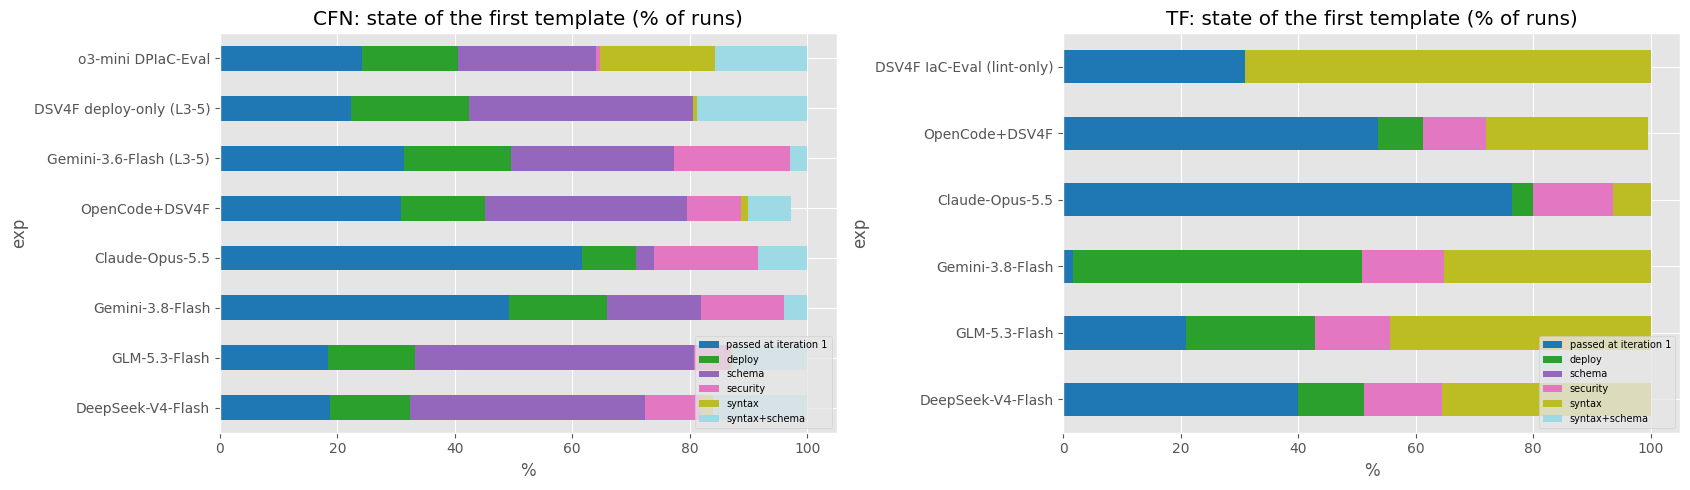

In [17]:
first = iters[iters.iteration == 1].copy()
def state(r):
    if r.validation_passed: return "passed at iteration 1"
    f = [c for c in ("syntax", "schema", "security") if r[f"{c}_ran"] and not r[f"{c}_ok"]]
    if not f and r.deploy_ran and not r.deploy_ok: f = ["deploy"]
    return "+".join(f) if f else "other"
first["state"] = first.apply(state, axis=1)
tabF1 = first.groupby("exp").state.value_counts(normalize=True).mul(100).round(1).unstack().fillna(0)
cols = ["passed at iteration 1"] + [c for c in tabF1.columns if c != "passed at iteration 1"]
display(tabF1[cols].rename(index=LABEL))
top = [c for c in cols if tabF1[c].max() >= 4]
fig, axs = plt.subplots(1, 2, figsize=(17, 5))
for ax, lang in zip(axs, ("CFN", "TF")):
    d = tabF1.loc[[e for e in SELECTED if lang_of(e) == lang and "Ablation" not in e], top].rename(index=LABEL)
    d.plot(kind="barh", stacked=True, ax=ax, colormap="tab20"); ax.set_title(f"{lang}: state of the first template (% of runs)"); ax.set_xlabel("%"); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "F1_first_attempt.png", dpi=150); plt.show()

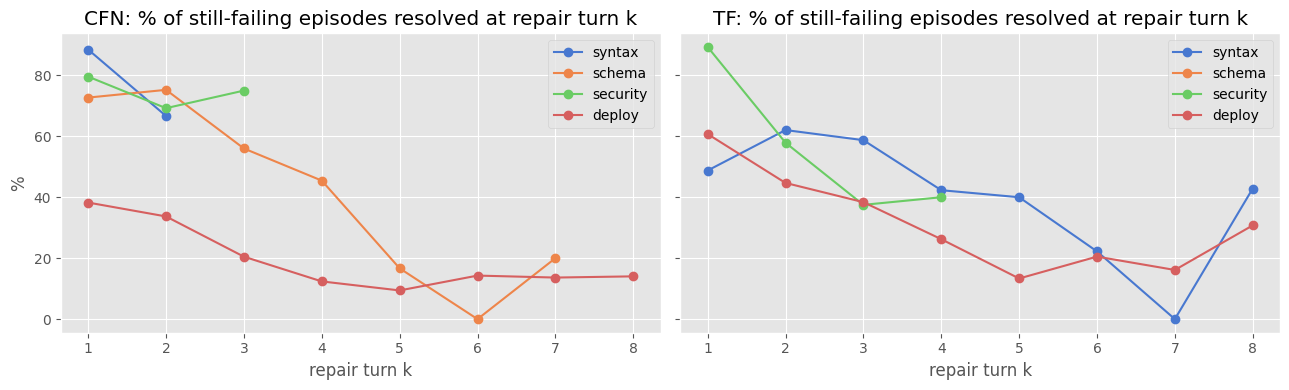

turn_k            1     2     3     4     5     6     7     8
lang cls                                                     
CFN  deploy    38.3  33.7  20.5  12.4   9.4  14.3  13.6  14.0
     schema    72.7  75.2  56.0  45.5  16.7   0.0  20.0   NaN
     security  79.6  69.2  75.0   NaN   NaN   NaN   NaN   NaN
     syntax    88.5  66.7   NaN   NaN   NaN   NaN   NaN   NaN
TF   deploy    60.7  44.7  38.4  26.2  13.3  20.5  16.1  30.8
     security  89.3  57.9  37.5  40.0   NaN   NaN   NaN   NaN
     syntax    48.8  62.0  58.7  42.3  40.0  22.2   0.0  42.9

In [18]:
last_it = iters.groupby(["exp", "run_id"]).iteration.max().rename("last_iter").reset_index()
epc = ep.merge(last_it, on=["exp", "run_id"]); epc["remaining"] = epc.last_iter - epc.first_iter
rows = []
for lang in ("CFN", "TF"):
    d = epc[epc.exp.isin(FULL[lang])]
    for cls in CLASSES:
        x = d[d.cls == cls]
        for k in range(1, 9):
            at_risk = ((x.remaining >= k) & ((x.latency.isna()) | (x.latency >= k))).sum()
            events = (x.latency == k).sum()
            rows.append((lang, cls, k, at_risk, events, events / at_risk if at_risk else np.nan))
haz = pd.DataFrame(rows, columns=["lang", "cls", "turn_k", "at_risk", "resolved", "hazard"])
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, lang in zip(axs, ("CFN", "TF")):
    for cls in CLASSES:
        h = haz[(haz.lang == lang) & (haz.cls == cls) & (haz.at_risk >= 5)]
        ax.plot(h.turn_k, h.hazard * 100, marker="o", label=cls)
    ax.set_title(f"{lang}: % of still-failing episodes resolved at repair turn k"); ax.set_xlabel("repair turn k"); ax.legend()
axs[0].set_ylabel("%"); plt.tight_layout(); plt.savefig(FIG / "F2_hazard.png", dpi=150); plt.show()
display(haz[haz.at_risk >= 5].pivot_table(index=["lang", "cls"], columns="turn_k", values="hazard").mul(100).round(1))

,run,n,"rho(required resources, iterations)",p,"rho(difficulty level, iterations)",p
exp,,,,,,
CFN_RealAWS_DSV4F,DeepSeek-V4-Flash,239,0.36,0.0000,0.38,0.0000
CFN_RealAWS_GLM53F,GLM-5.3-Flash,228,0.34,0.0000,0.36,0.0000
CFN_RealAWS_Gemini38F,Gemini-3.8-Flash,248,0.27,0.0000,0.30,0.0000
CFN_RealAWS_Opus55,Claude-Opus-5.5,246,0.23,0.0004,0.22,0.0005
CFN_RealAWS_OpenCode_DSV4F,OpenCode+DSV4F,227,0.34,0.0000,0.36,0.0000
CFN_RealAWS_Gemini36F_L345,Gemini-3.6-Flash (L3-5),136,0.05,0.5898,0.07,0.3987
CFN_RealAWS_DSV4F_DeployOnly_L345,DSV4F deploy-only (L3-5),124,0.01,0.9451,-0.09,0.3366
CFN_DPIaCEval_o3mini_DeployOnly,o3-mini DPIaC-Eval,138,0.36,0.0000,0.34,0.0001
TF_RealAWS_DSV4F,DeepSeek-V4-Flash,246,0.37,0.0000,0.43,0.0000


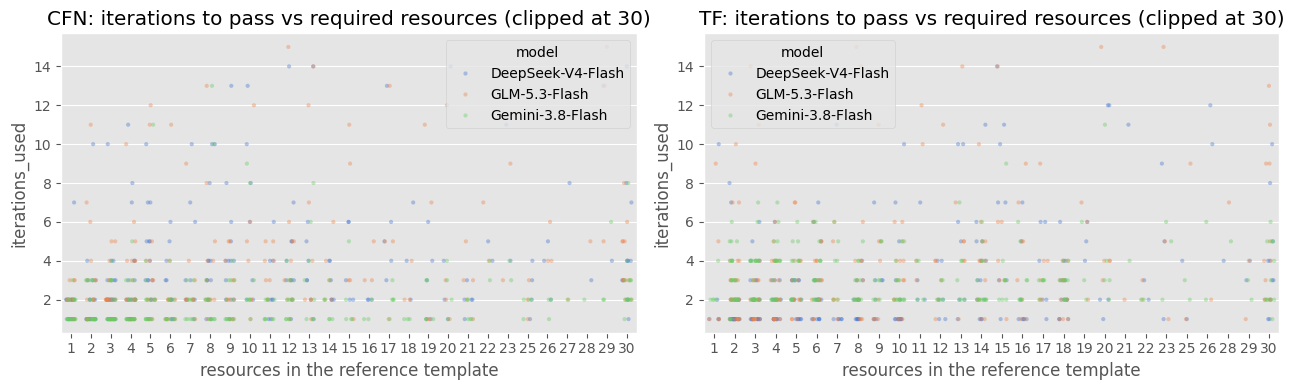

In [19]:
rows = []
for e in SELECTED:
    d = runs[(runs.exp == e) & runs.passed & runs.req.notna()]
    if len(d) > 8:
        rho, p = stats.spearmanr(d.req, d.iterations_used); rho2, p2 = stats.spearmanr(d.difficulty.fillna(0), d.iterations_used)
        rows.append((LABEL[e], e, len(d), round(rho, 2), round(p, 4), round(rho2, 2), round(p2, 4)))
display(pd.DataFrame(rows, columns=["run", "exp", "n", "rho(required resources, iterations)", "p", "rho(difficulty level, iterations)", "p "]).set_index("exp"))
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, lang in zip(axs, ("CFN", "TF")):
    d = runs[runs.exp.isin(FULL[lang]) & runs.passed & runs.req.notna()]
    sns.stripplot(data=d.assign(model=d.exp.map(LABEL)), x=d.req.clip(upper=30), y="iterations_used", hue="model", ax=ax, alpha=.4, size=3, jitter=.25)
    ax.set_title(f"{lang}: iterations to pass vs required resources (clipped at 30)"); ax.set_xlabel("resources in the reference template")
plt.tight_layout(); plt.savefig(FIG / "F3_complexity.png", dpi=150); plt.show()

In [20]:
for lang in ("CFN", "TF"):
    w = {}
    for e in FULL[lang]:
        d = runs[runs.exp == e].set_index("row_number")
        w[LABEL[e]] = d.iterations_used.where(d.passed, 16)
    w = pd.DataFrame(w).dropna()
    print(f"\n{lang}: Spearman correlation of iterations per scenario between models (n = {len(w)} shared scenarios)"); display(w.corr(method="spearman").round(2))
    w["mean_iters"] = w.mean(axis=1); w["models_failing"] = (w.drop(columns="mean_iters") >= 16).sum(axis=1)
    path = runs[runs.exp == FULL[lang][0]].set_index("row_number").ground_truth_path.str.split("/").str[-2:].str.join("/")
    hard = w.sort_values("mean_iters", ascending=False).head(12).join(path.rename("scenario")); hard["difficulty"] = runs[runs.exp == FULL[lang][0]].set_index("row_number").difficulty
    print(f"{lang}: 12 hardest scenarios (mean iterations over the full runs); scenarios failed by >=2 models: {(w.models_failing >= 2).sum()}")
    display(hard)


CFN: Spearman correlation of iterations per scenario between models (n = 250 shared scenarios)


,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash
DeepSeek-V4-Flash,1.00,0.50,0.45
GLM-5.3-Flash,0.50,1.00,0.48
Gemini-3.8-Flash,0.45,0.48,1.00


CFN: 12 hardest scenarios (mean iterations over the full runs); scenarios failed by >=2 models: 5


,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash,mean_iters,models_failing,scenario,difficulty
row_number,,,,,,,
6,16.0,16.0,16.0,16.000000,3,cloudformation/core_network.yaml,1
174,6.0,16.0,16.0,12.666667,2,templates/elasticbeanstalk-sample.template,5
152,16.0,12.0,9.0,12.333333,1,cloudformation/image-builder.yaml,4
119,16.0,15.0,6.0,12.333333,1,service/service-ec2-private-discovery.yml,4
123,13.0,16.0,8.0,12.333333,1,cloudformation/image-builder.json,4
150,10.0,16.0,10.0,12.000000,1,chaos/multi-region-scenario.yaml,4
263,16.0,16.0,4.0,12.000000,2,aws-config-conformance-packs/Operational-Best-Practices-for-CloudW...,2
159,14.0,14.0,8.0,12.000000,0,cloudformation_collected_templates_new/template_04525_prxu.org-hos...,4
131,10.0,13.0,13.0,12.000000,0,templates/gateway.yaml,4



TF: Spearman correlation of iterations per scenario between models (n = 250 shared scenarios)


,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash
DeepSeek-V4-Flash,1.00,0.52,0.18
GLM-5.3-Flash,0.52,1.00,0.20
Gemini-3.8-Flash,0.18,0.20,1.00


TF: 12 hardest scenarios (mean iterations over the full runs); scenarios failed by >=2 models: 1


,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash,mean_iters,models_failing,scenario,difficulty
row_number,,,,,,,
249,16.0,16.0,16.0,16.000000,3,scenarios_greenfield/terrads_bf3ef706d7fd,5
311,12.0,15.0,11.0,12.666667,0,scenarios_greenfield/terrads_a6b6f6412452,4
184,16.0,13.0,6.0,11.666667,1,scenarios_greenfield/terrads_8bad01c5fde3,5
174,11.0,14.0,9.0,11.333333,0,scenarios/terrads_05edc40999d7,5
185,12.0,16.0,6.0,11.333333,1,scenarios/terrads_f60d1837f9eb,5
208,10.0,14.0,7.0,10.333333,0,scenarios/terrads_858f5e6cf636,5
370,5.0,15.0,6.0,8.666667,0,scenarios/gh_20964d89,5
192,7.0,16.0,3.0,8.666667,1,scenarios_greenfield/terrads_eb98ef1eb786,5
201,16.0,5.0,5.0,8.666667,1,scenarios_greenfield/terrads_e9ee10871093,5


In [21]:
rows = []
for lang in ("CFN", "TF"):
    base = runs[runs.exp == f"{lang}_Ablation_IaCGOD"].set_index("row_number")
    for e in GROUPS[f"{lang} ablation"]:
        if e.endswith("_IaCGOD"): continue
        a = runs[runs.exp == e].set_index("row_number"); idx = base.index.intersection(a.index)
        b_only = int((base.loc[idx].passed & ~a.loc[idx].passed).sum()); a_only = int((~base.loc[idx].passed & a.loc[idx].passed).sum())
        p_mc = stats.binomtest(b_only, b_only + a_only, .5).pvalue if b_only + a_only else 1.0
        both = idx[(base.loc[idx].passed & a.loc[idx].passed).values]
        x, y = base.loc[both].iterations_used.values, a.loc[both].iterations_used.values
        p_w = stats.wilcoxon(x, y).pvalue if len(both) > 5 and np.any(x != y) else np.nan
        rows.append((lang, LABEL[e], len(idx), int(a.loc[idx].passed.sum()), b_only, a_only, round(p_mc, 3), len(both), round(x.mean(), 2), round(y.mean(), 2), round(p_w, 3) if p_w == p_w else np.nan,
                     round(100 * a.loc[idx].acc_pct.mean() / 100, 1), round(base.loc[idx].acc_pct.mean(), 1)))
tabF5 = pd.DataFrame(rows, columns=["lang", "condition", "scenarios", "passes", "only IaCGOD passes", "only ablation passes", "McNemar p", "commonly passed", "iters IaCGOD", "iters ablation", "Wilcoxon p",
                                    "accuracy % ablation", "accuracy % IaCGOD"])
display(tabF5)

,lang,condition,scenarios,passes,only IaCGOD passes,only ablation passes,McNemar p,commonly passed,iters IaCGOD,iters ablation,Wilcoxon p,accuracy % ablation,accuracy % IaCGOD
0,CFN,no dense RAG,50,49,0,0,1.00,49,3.04,2.55,0.277,77.9,78.4
1,CFN,OpenCode+Retriever,50,47,2,0,0.50,47,3.02,2.83,0.856,83.1,78.4
2,CFN,no GraphRAG,50,50,0,1,1.00,49,3.04,2.20,0.013,76.5,78.4
3,CFN,no Planner,50,48,1,0,1.00,48,3.08,1.83,0.000,81.0,78.4
4,CFN,Trivy all severities,50,49,0,0,1.00,49,3.04,2.96,0.643,73.1,78.4
5,CFN,no Remediator,50,48,1,0,1.00,48,2.88,2.17,0.029,78.8,78.4
6,CFN,no query rewrite,50,49,0,0,1.00,49,3.04,2.63,0.196,73.9,78.4
7,TF,no dense RAG,49,47,2,0,0.50,47,2.77,3.83,0.050,71.3,75.6
8,TF,OpenCode+Retriever,50,47,3,0,0.25,47,2.70,2.02,0.064,78.1,76.0
9,TF,no GraphRAG,50,48,2,0,0.50,48,2.75,2.23,0.081,71.9,76.0


In [22]:
rows = []
for e in SELECTED:
    r = runs[runs.exp == e]; p, f_ = r[r.passed], r[~r.passed]
    rows.append((LABEL[e], e, len(f_), round(p.iterations_used.mean(), 2), round(f_.iterations_used.mean(), 2) if len(f_) else np.nan,
                 round(p.token_all_tokens.mean() / 1000), round(f_.token_all_tokens.mean() / 1000) if len(f_) else np.nan,
                 round(f_.token_all_tokens.sum() / r.token_all_tokens.sum() * 100, 1), round(r.token_all_tokens.sum() / max(1, len(p)) / 1000),
                 round(p.duration_seconds.mean() / 60, 1), round(f_.duration_seconds.mean() / 60, 1) if len(f_) else np.nan))
tabF6 = pd.DataFrame(rows, columns=["run", "exp", "failed runs", "iters passed", "iters failed", "ktokens passed", "ktokens failed", "% of tokens on failed runs", "ktokens per passing scenario", "min passed", "min failed"]).set_index("exp")
display(tabF6.rename(index=LABEL))

,run,failed runs,iters passed,iters failed,ktokens passed,ktokens failed,% of tokens on failed runs,ktokens per passing scenario,min passed,min failed
exp,,,,,,,,,,
DeepSeek-V4-Flash,DeepSeek-V4-Flash,11,3.55,15.00,128,1007.0,26.6,174,20.0,126.3
GLM-5.3-Flash,GLM-5.3-Flash,22,3.50,15.00,122,946.0,42.7,214,19.3,71.0
Gemini-3.8-Flash,Gemini-3.8-Flash,2,2.00,15.00,55,1387.0,16.8,66,12.0,83.2
Claude-Opus-5.5,Claude-Opus-5.5,4,1.55,15.00,17,140.0,11.8,19,5.8,73.5
OpenCode+DSV4F,OpenCode+DSV4F,23,2.70,7.48,33,128.0,28.2,46,12.6,33.0
Gemini-3.6-Flash (L3-5),Gemini-3.6-Flash (L3-5),1,2.48,15.00,44,642.0,9.7,49,9.9,42.4
DSV4F deploy-only (L3-5),DSV4F deploy-only (L3-5),10,3.49,15.00,150,1549.0,45.5,275,29.7,186.7
o3-mini DPIaC-Eval,o3-mini DPIaC-Eval,15,3.05,15.00,58,736.0,58.1,138,18.7,145.5
DeepSeek-V4-Flash,DeepSeek-V4-Flash,4,2.91,15.00,115,1768.0,20.0,144,15.8,74.0


In [23]:
def err_set(r):
    s = set()
    for c in ("syntax", "schema", "security"): s |= {f"{c}:{k}" for k in str(r.get(f"{c}_keys") or "").split("|") if k}
    if r["deploy_ran"] and not r["deploy_ok"]: s |= {f"deploy:{k}" for k in str(r.get("deploy_keys") or "").split("|") if k}
    return frozenset(s)
FAILED = set(runs.loc[~runs.passed, "run_id"])
rows = []
for (e, rid), g in iters.groupby(["exp", "run_id"], sort=False):
    recs = g.to_dict("records")
    if rid not in FAILED: continue
    sets = [err_set(r) for r in recs]
    stuck = len(sets) >= 3 and sets[-1] == sets[-2] == sets[-3] and bool(sets[-1])
    last = recs[-1]
    final = [c for c in ("syntax", "schema", "security") if last[f"{c}_ran"] and not last[f"{c}_ok"]]
    if not final and last["deploy_ran"] and not last["deploy_ok"]: final = ["deploy"]
    rows.append((e, rid, stuck, "+".join(final) or "none visible", len(recs)))
fails = pd.DataFrame(rows, columns=["exp", "run_id", "stuck", "final_failing", "iterations"])
t7 = fails.groupby("exp").agg(failed_runs=("run_id", "size"), stuck_pct=("stuck", lambda x: 100 * x.mean())).round(1)
t8 = fails.groupby("exp").final_failing.value_counts(normalize=True).mul(100).round(1).unstack().fillna(0)
display(pd.concat([t7, t8], axis=1).rename(index=LABEL))

,failed_runs,stuck_pct,deploy,none visible,schema,security,syntax,syntax+schema
exp,,,,,,,,
IaCGOD,1,0.0,0.0,0.0,0.0,100.0,0.0,0.0
no dense RAG,1,100.0,0.0,0.0,0.0,100.0,0.0,0.0
no Planner,2,50.0,50.0,0.0,0.0,50.0,0.0,0.0
no query rewrite,1,0.0,0.0,0.0,100.0,0.0,0.0,0.0
no Remediator,2,0.0,50.0,0.0,0.0,50.0,0.0,0.0
OpenCode+Retriever,3,0.0,33.3,0.0,33.3,33.3,0.0,0.0
Trivy all severities,1,0.0,0.0,0.0,0.0,100.0,0.0,0.0
o3-mini DPIaC-Eval,15,26.7,73.3,0.0,6.7,0.0,6.7,13.3
DeepSeek-V4-Flash,11,18.2,72.7,0.0,0.0,18.2,0.0,9.1


In [24]:
def key_counts(cls, exps):
    m = iters.exp.isin(exps) & iters[f"{cls}_ran"] & ~iters[f"{cls}_ok"] if cls != "deploy" else iters.exp.isin(exps) & iters.deploy_ran & ~iters.deploy_ok
    s = iters.loc[m, f"{cls}_keys"].str.split("|").explode()
    return len(iters[m]), s[s != ""].value_counts()
for lang in ("CFN", "TF"):
    for cls in (["syntax", "schema", "security", "deploy"] if lang == "CFN" else ["syntax", "security", "deploy"]):
        n, vc = key_counts(cls, FULL[lang])
        t = vc.head(8).to_frame("iterations"); t["% of failing iterations"] = (100 * t.iterations / n).round(1)
        print(f"\n{lang} - {cls}: top identifiers ({n} failing iterations in the full runs)"); display(t)
rows = []
for e in [x for x in SELECTED if lang_of(x) == "TF"]:
    m = iters.exp.eq(e) & iters.syntax_ran & ~iters.syntax_ok
    ks = iters.loc[m, "syntax_keys"]
    rows.append((LABEL[e], e, int(m.sum()), round(100 * (ks == "init: Failed to install provider").mean(), 1) if m.sum() else np.nan))
display(pd.DataFrame(rows, columns=["run", "exp", "failing syntax iterations", "% that are only a provider-install failure (environment)"]).set_index("exp"))
f1 = iters[(iters.iteration == 1) & (iters.lang == "TF") & iters.deploy_ran & ~iters.deploy_ok]
for e in FULL["TF"]:
    s = f1[f1.exp == e].deploy_keys.str.split("|").explode().value_counts().head(5)
    print(f"\n{LABEL[e]} (TF): top first-attempt deployment failures ({int((f1.exp == e).sum())} runs)"); display(s.to_frame("runs"))


CFN - syntax: top identifiers (130 failing iterations in the full runs)


,iterations,% of failing iterations
syntax_keys,,
yaml-syntax,130,100.0



CFN - schema: top identifiers (638 failing iterations in the full runs)


,iterations,% of failing iterations
schema_keys,,
E3002,203,31.8
E0000,92,14.4
E3003,85,13.3
E3004,62,9.7
E3006,61,9.6
E6101,52,8.2
E3012,35,5.5
E1019,33,5.2



CFN - security: top identifiers (233 failing iterations in the full runs)


...

,runs
deploy_keys,
apply: No value for required variable,5
aws_kms_alias,3
aws_iam_role_policy_attachment,3
aws_sqs_queue,2
aws_kms_key,2



GLM-5.3-Flash (TF): top first-attempt deployment failures (55 runs)


,runs
deploy_keys,
apply: invalid AWS Region:,26
apply: Invalid provider configuration,26
aws_iam_role_policy_attachment,5
aws_sqs_queue,3
aws_nat_gateway,3



Gemini-3.8-Flash (TF): top first-attempt deployment failures (123 runs)


,runs
deploy_keys,
apply: Invalid provider configuration,119
apply: invalid AWS Region:,119
init: Error: Failed to install provider,3
apply: No value for required variable,1


## G. Error identifiers, recurrence and provider configuration (for RQ3)

In [25]:
STATIC = ["syntax", "schema", "security"]
rows, runrows = [], []
for (e, rid), g in iters.groupby(["exp", "run_id"], sort=False):
    recs = g.to_dict("records")
    ks = [{c: {k for k in str(r.get(f"{c}_keys") or "").split("|") if k} for c in CLASSES} for r in recs]
    for i in range(len(recs) - 1):
        for c in CLASSES:
            if not (recs[i][f"{c}_ran"] and recs[i + 1][f"{c}_ran"]): continue
            a, b = ks[i][c], ks[i + 1][c]
            if a: rows.append((e, c, len(a), len(a - b)))
    ranj = {c: [j for j, r in enumerate(recs) if r[f"{c}_ran"]] for c in STATIC}
    rec = any(k in ks[J[t]][c] and k not in ks[J[t - 1]][c] and any(k in ks[J[m]][c] for m in range(t - 1))
              for c in STATIC for J in [ranj[c]] for t in range(1, len(J)) for k in ks[J[t]][c])
    pers = len(recs) >= 2 and any(len(ranj[c]) == len(recs) and all(k in ks[j][c] for j in ranj[c]) for c in STATIC for k in ks[0][c])
    dep = [j for j, r in enumerate(recs) if r["deploy_ran"]]
    pers_dep = len(dep) >= 2 and any(all(k in ks[j]["deploy"] for j in dep) for k in ks[dep[0]]["deploy"])
    runrows.append((e, rid, rec, pers, pers_dep, len(recs) >= 2))
fx = pd.DataFrame(rows, columns=["exp", "cls", "found", "fixed"])
t1 = fx.groupby(["exp", "cls"]).apply(lambda x: 100 * x.fixed.sum() / x.found.sum()).unstack().round(1)
t1["findings (security)"] = fx[fx.cls == "security"].groupby("exp").found.sum()
rr = pd.DataFrame(runrows, columns=["exp", "run_id", "recurrence", "persist_static", "persist_deploy", "multi"])
t2 = rr[rr.multi].groupby("exp").agg(runs_ge2_iterations=("run_id", "size"), recurrence_pct=("recurrence", lambda x: 100 * x.mean()),
                                      persistent_static_pct=("persist_static", lambda x: 100 * x.mean()), persistent_deploy_pct=("persist_deploy", lambda x: 100 * x.mean())).round(1)
print("share of identifiers present at iteration i that are gone at i+1 (%), by class"); display(pd.concat([t1, t2], axis=1).rename(index=LABEL))

share of identifiers present at iteration i that are gone at i+1 (%), by class


,deploy,schema,security,syntax,findings (security),runs_ge2_iterations,recurrence_pct,persistent_static_pct,persistent_deploy_pct
exp,,,,,,,,,
IaCGOD,62.5,88.1,74.3,100.0,35.0,37,8.1,0.0,0.0
no dense RAG,59.4,98.1,64.3,66.7,28.0,32,6.2,0.0,0.0
no GraphRAG,63.6,95.7,100.0,66.7,19.0,31,3.2,0.0,0.0
no Planner,36.0,97.4,81.8,NaN,22.0,27,7.4,0.0,3.7
no query rewrite,40.9,98.1,90.0,100.0,30.0,36,2.8,0.0,0.0
no Remediator,62.5,93.2,76.0,100.0,25.0,35,5.7,0.0,0.0
OpenCode+Retriever,46.7,86.7,53.6,80.0,28.0,36,0.0,0.0,0.0
Trivy all severities,53.6,94.3,93.5,100.0,77.0,39,2.6,0.0,0.0
o3-mini DPIaC-Eval,54.1,79.1,100.0,57.9,1.0,116,7.8,1.7,2.6


In [26]:
def ident_table(exps, cls, top=8):
    cnt, unres = {}, {}
    for e in exps:
        c_s, c_u = {}, {}
        for rid, g in iters[iters.exp == e].groupby("run_id"):
            recs = g.to_dict("records")
            seen = set(); 
            for r in recs:
                if cls == "deploy" and not (r["deploy_ran"] and not r["deploy_ok"]): continue
                if cls != "deploy" and (not r[f"{cls}_ran"] or r[f"{cls}_ok"]): continue
                seen |= {k for k in str(r.get(f"{cls}_keys") or "").split("|") if k}
            last = recs[-1]; last_keys = {k for k in str(last.get(f"{cls}_keys") or "").split("|") if k} if rid in FAILED else set()
            for k in seen: c_s[k] = c_s.get(k, 0) + 1
            for k in last_keys: c_u[k] = c_u.get(k, 0) + 1
            c_s["(any)"] = c_s.get("(any)", 0) + (1 if seen else 0); c_u["(any)"] = c_u.get("(any)", 0) + (1 if last_keys else 0)
        cnt[e], unres[e] = c_s, c_u
    keys = pd.Series({k: sum(cnt[e].get(k, 0) for e in exps) for e in exps for k in cnt[e] if k != "(any)"}).sort_values(ascending=False).head(top).index.tolist() + ["(any)"]
    return pd.DataFrame({LABEL[e]: [f"{cnt[e].get(k, 0)} ({unres[e].get(k, 0)})" if cnt[e].get(k, 0) else "-" for k in keys] for e in exps}, index=keys)
RQ3_RUNS = {"CFN": ["CFN_RealAWS_DSV4F", "CFN_RealAWS_GLM53F", "CFN_RealAWS_Gemini38F", "CFN_RealAWS_OpenCode_DSV4F"], "TF": ["TF_RealAWS_DSV4F", "TF_RealAWS_GLM53F", "TF_RealAWS_Gemini38F"]}
G2 = {}
for lang in ("CFN", "TF"):
    for cls in (STATIC if lang == "CFN" else ["syntax", "security"]) + ["deploy"]:
        G2[(lang, cls)] = ident_table(RQ3_RUNS[lang], cls)
        print(f"\\n{lang} - {cls}: scenarios affected (unresolved at the end)"); display(G2[(lang, cls)])

\nCFN - syntax: scenarios affected (unresolved at the end)


,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash,OpenCode+DSV4F
yaml-syntax,48 (1),45 (3),13 (0),23 (0)
(any),48 (1),45 (3),13 (0),23 (0)


\nCFN - schema: scenarios affected (unresolved at the end)


,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash,OpenCode+DSV4F
E3002,71 (0),81 (0),14 (0),42 (0)
E0000,26 (1),41 (3),13 (0),14 (0)
E3003,28 (0),36 (0),6 (0),13 (0)
E3004,23 (0),28 (0),3 (0),13 (0)
E6101,11 (0),26 (0),11 (0),7 (0)
E1019,13 (0),17 (0),2 (0),11 (0)
E3012,13 (0),18 (0),2 (0),9 (0)
E3030,7 (0),19 (0),2 (0),9 (0)
(any),151 (1),164 (5),55 (0),109 (2)


\nCFN - security: scenarios affected (unresolved at the end)


...

,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash
init: Failed to install provider,18 (0),39 (1),71 (0)
Unsupported argument,47 (1),52 (0),8 (0)
Missing required argument,7 (1),34 (0),1 (0)
Unsupported block type,12 (0),25 (0),2 (0)
Unsupported attribute,7 (0),15 (0),2 (0)
Invalid resource type,9 (0),10 (1),3 (0)
Value for unconfigurable attribute,6 (0),6 (0),1 (0)
Reference to undeclared resource,4 (1),2 (0),6 (0)
(any),99 (1),129 (3),96 (0)


\nTF - security: scenarios affected (unresolved at the end)


,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash
AWS-0164,36 (0),36 (0),34 (0)
AWS-0104,19 (1),9 (0),14 (0)
AWS-0132,14 (0),9 (0),9 (0)
AWS-0028,5 (0),1 (0),2 (0)
AWS-0131,5 (0),1 (0),1 (0)
AWS-0087,2 (0),2 (0),2 (0)
AWS-0091,2 (0),2 (0),2 (0)
AWS-0093,2 (0),2 (0),2 (0)
(any),64 (1),59 (0),55 (0)


\nTF - deploy: scenarios affected (unresolved at the end)


,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash
apply: invalid AWS Region:,-,75 (0),230 (0)
apply: Invalid provider configuration,-,75 (0),230 (0)
aws_iam_role,18 (0),27 (0),12 (1)
aws_kms_alias,19 (0),15 (0),7 (1)
aws_s3_bucket,13 (0),16 (0),8 (0)
apply: No value for required variable,13 (0),4 (0),1 (0)
aws_key_pair,4 (0),5 (0),4 (1)
aws_iam_policy,6 (0),6 (0),1 (0)
(any),84 (2),137 (1),235 (1)


In [27]:
KEY = "apply: Invalid provider configuration"
rows = []
for e in [x for x in SELECTED if lang_of(x) == "TF"]:
    n_runs, first, later, reappear = 0, 0, 0, 0
    for rid, g in iters[iters.exp == e].groupby("run_id"):
        recs = g.to_dict("records")
        has = [KEY in str(r.get("deploy_keys") or "").split("|") for r in recs]
        if not any(has): continue
        n_runs += 1
        if has[0]: first += 1
        else: later += 1
        if any(has[j] and not has[j - 1] and any(has[:j - 1]) for j in range(1, len(has))): reappear += 1
    rows.append((LABEL[e], e, iters[iters.exp == e].run_id.nunique(), n_runs, first, later, reappear))
g3df = pd.DataFrame(rows, columns=["run", "exp", "runs", "runs with a missing provider configuration", "at the first attempt", "only after a working first attempt", "came back after being fixed"]).set_index("exp")
display(g3df)

,run,runs,runs with a missing provider configuration,at the first attempt,only after a working first attempt,came back after being fixed
exp,,,,,,
TF_RealAWS_DSV4F,DeepSeek-V4-Flash,250,0,0,0,0
TF_RealAWS_GLM53F,GLM-5.3-Flash,250,75,26,49,1
TF_RealAWS_Gemini38F,Gemini-3.8-Flash,250,230,119,111,5
TF_RealAWS_Opus55,Claude-Opus-5.5,250,0,0,0,0
TF_RealAWS_OpenCode_DSV4F,OpenCode+DSV4F,250,0,0,0,0
TF_IaCEval_DSV4F_LintOnly,DSV4F IaC-Eval (lint-only),372,0,0,0,0
TF_Ablation_IaCGOD,IaCGOD,50,0,0,0,0
TF_Ablation_NoDenseRAG,no dense RAG,49,0,0,0,0
TF_Ablation_OpenCodeRetriever,OpenCode+Retriever,49,0,0,0,0


In [28]:
g4rows = []
for lang in ("CFN", "TF"):
    ex = RQ3_RUNS[lang]
    w = pd.DataFrame({LABEL[e]: runs[runs.exp == e].set_index("row_number").passed for e in ex}).dropna()
    failed_any = w[~w.all(axis=1)]; failed_all = w[~w.any(axis=1)]
    print(f"{lang}: {len(w)} shared scenarios; failed by >=1 run: {len(failed_any)}; of these solved by another run: {int((failed_any.any(axis=1)).sum())}; failed by all {len(ex)} runs: {len(failed_all)}")
    g4rows.append((lang, "(all runs)", len(w), len(failed_any), int(failed_any.any(axis=1).sum()), ", ".join(str(i) for i in failed_all.index.tolist())))
    for e in ex:
        f_ = w[~w[LABEL[e]]]; print(f"   {LABEL[e]}: failed {len(f_)}, solved by some other run: {int(f_.drop(columns=LABEL[e]).any(axis=1).sum())}")
        g4rows.append((lang, LABEL[e], len(w), len(f_), int(f_.drop(columns=LABEL[e]).any(axis=1).sum()), ""))
    print("   failed by all runs (row_number):", failed_all.index.tolist())
    wm = w[[LABEL[e] for e in ex if e in FULL[lang]]]; fm = wm[~wm.all(axis=1)]
    print(f"   IaCGOD models only ({wm.shape[1]} runs): failed by >=1: {len(fm)}; solved by another: {int(fm.any(axis=1).sum())}; failed by all: {wm[~wm.any(axis=1)].index.tolist()}")
    g4rows.append((lang, "(IaCGOD models only)", len(wm), len(fm), int(fm.any(axis=1).sum()), ", ".join(str(i) for i in wm[~wm.any(axis=1)].index.tolist())))

CFN: 250 shared scenarios; failed by >=1 run: 44; of these solved by another run: 43; failed by all 4 runs: 1
   DeepSeek-V4-Flash: failed 11, solved by some other run: 10
   GLM-5.3-Flash: failed 22, solved by some other run: 21
   Gemini-3.8-Flash: failed 2, solved by some other run: 1
   OpenCode+DSV4F: failed 23, solved by some other run: 22
   failed by all runs (row_number): [6]
   IaCGOD models only (3 runs): failed by >=1: 29; solved by another: 28; failed by all: [6]
TF: 250 shared scenarios; failed by >=1 run: 7; of these solved by another run: 6; failed by all 3 runs: 1
   DeepSeek-V4-Flash: failed 4, solved by some other run: 3
   GLM-5.3-Flash: failed 4, solved by some other run: 3
   Gemini-3.8-Flash: failed 1, solved by some other run: 0
   failed by all runs (row_number): [249]
   IaCGOD models only (3 runs): failed by >=1: 7; solved by another: 6; failed by all: [249]


In [29]:
t = runs.groupby("exp").apply(lambda x: pd.Series({"rows": len(x), "invalid": int(x.invalid.sum()), "pass_% (all rows)": round(100 * x.passed.mean(), 1),
                                                   "pass_% (invalid excluded)": round(100 * x[~x.invalid].passed.mean(), 1)}))
tabG5 = t.loc[SELECTED]
display(tabG5.rename(index=LABEL))

,rows,invalid,pass_% (all rows),pass_% (invalid excluded)
exp,,,,
DeepSeek-V4-Flash,250.0,3.0,95.6,96.8
GLM-5.3-Flash,250.0,3.0,91.2,92.3
Gemini-3.8-Flash,250.0,0.0,99.2,99.2
Claude-Opus-5.5,250.0,0.0,98.4,98.4
OpenCode+DSV4F,250.0,2.0,90.8,91.5
Gemini-3.6-Flash (L3-5),137.0,0.0,99.3,99.3
DSV4F deploy-only (L3-5),134.0,2.0,92.5,93.9
o3-mini DPIaC-Eval,153.0,2.0,90.2,91.4
DeepSeek-V4-Flash,250.0,0.0,98.4,98.4


In [30]:
oc = runs[runs.exp.str.contains("OpenCode") & runs.final_verdict_source.notna()]
rows = []
for e, g in oc.groupby("exp"):
    for label, x in (("passed", g[g.passed]), ("failed", g[~g.passed])):
        rows.append((LABEL[e], e, label, len(x), round(100 * x.submitted_matched_validated.astype(float).mean(), 1), x.final_verdict_source.value_counts().to_dict(), x.status.value_counts().to_dict(),
                     round(x.harness_turns.mean(), 1)))
tabG6 = pd.DataFrame(rows, columns=["run", "exp", "outcome", "runs", "matched_pct", "verdict_source", "status", "harness_turns"])
display(tabG6.rename(columns={"matched_pct": "submitted template = validated template (%)", "verdict_source": "final verdict source",
                              "harness_turns": "mean harness turns"}).set_index("exp"))

,run,outcome,runs,submitted template = validated template (%),final verdict source,status,mean harness turns
exp,,,,,,,
CFN_Ablation_OpenCodeRetriever,OpenCode+Retriever,passed,47,100.0,{'recorded': 47},{'ok': 47},15.8
CFN_Ablation_OpenCodeRetriever,OpenCode+Retriever,failed,3,0.0,"{'revalidated': 2, 'recorded': 1}",{'ok': 3},47.7
CFN_RealAWS_OpenCode_DSV4F,OpenCode+DSV4F,passed,227,92.1,"{'recorded': 208, 'deployed_at_finalize': 18, 'revalidated': 1}","{'ok': 219, 'harness_timeout': 6, 'harness_error': 2}",11.6
CFN_RealAWS_OpenCode_DSV4F,OpenCode+DSV4F,failed,23,26.1,"{'deployed_at_finalize': 12, 'recorded': 6, 'revalidated': 5}","{'ok': 20, 'harness_timeout': 2, 'harness_error': 1}",32.0
TF_Ablation_OpenCodeRetriever,OpenCode+Retriever,passed,47,100.0,{'recorded': 47},{'ok': 47},13.7
TF_Ablation_OpenCodeRetriever,OpenCode+Retriever,failed,3,0.0,"{'recorded': 1, 'revalidated': 1, 'deployed_at_finalize': 1}","{'ok': 2, 'harness_timeout': 1}",12.7
TF_RealAWS_OpenCode_DSV4F,OpenCode+DSV4F,passed,242,100.0,{'recorded': 242},{'ok': 242},9.4
TF_RealAWS_OpenCode_DSV4F,OpenCode+DSV4F,failed,8,25.0,"{'revalidated': 6, 'deployed_at_finalize': 2}",{'ok': 8},61.0


## H. Ablation deep dive

calls/scen                              ktokens/scen                             
agent                  engineer planner remediator retriever     engineer planner remediator retriever
exp                                                                                                   
IaCGOD                     3.28     1.0       2.28      1.64        81.37    7.08      76.05     15.15
no dense RAG               2.80     1.0       1.80      1.22        87.25    5.66      69.03     11.85
no GraphRAG                2.18     1.0       1.18      0.90        55.91    5.33      32.05      8.99
no Planner                 2.36     0.0       1.36      0.96        66.25    0.00      53.11      8.38
Trivy all severities       3.20     1.0       2.20      1.22       100.99    5.37      86.80     14.62
no Remediator              2.68     1.0       0.00      1.24        96.47    5.62       0.00     10.93
no query rewrite           2.88     1.0       1.88      0.00        91.79    5.44      75.18      0.00
IaCGOD                     2.92     1.0       1.92      1.66        45.18    5.11      47.21     10.19
no dense RAG               4.29     1.0       3.29      2.88       117.03    5.29     143.72     19.46
no GraphRAG                2.74     1.0       1.74      1.42        82.57    6.22      68.38     10.90
no Planner                 1.92     0.0       0.92      0.70        37.60    0.00      33.25      5.13
Trivy all severities       4.00     1.0       3.00      1.48        95.88    5.85      91.78      9.83
no Remediator              2.50     1.0       0.00      1.20        64.63    5.14       0.00      7.86
no query rewrite           2.28     1.0       1.28      0.00        50.32    5.91      43.39      0.00

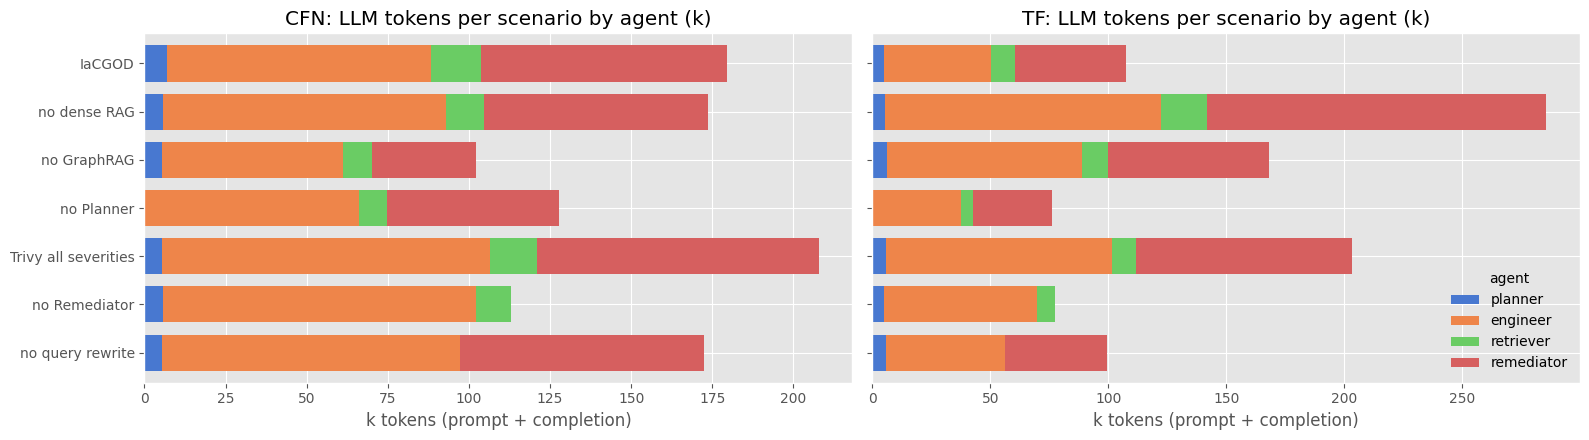

In [31]:
ABL_EXPS = GROUPS["CFN ablation"] + GROUPS["TF ablation"]
p_calls = CACHE / "agent_calls_ablation.pkl"
abl_runs = runs[runs.exp.isin(ABL_EXPS)][["exp", "run_id"]].dropna()
if p_calls.exists() and set(abl_runs.run_id) <= set(pd.read_pickle(p_calls).run_id):
    calls = pd.read_pickle(p_calls)
else:
    loc = {}
    for dp, dn, fn in os.walk(RUNS):
        if "llm_calls.jsonl" in fn:
            loc.setdefault(os.path.basename(dp), os.path.join(dp, "llm_calls.jsonl"))
    recs = []
    for rid in abl_runs.run_id.unique():
        f = loc.get(str(rid))
        if not f: continue
        for line in open(f):
            try: d = json.loads(line)
            except Exception: continue
            tu = d.get("token_usage") or {}
            recs.append(dict(run_id=rid, agent=d.get("agent"), iteration=d.get("iteration"),
                             prompt=tu.get("prompt_tokens") or 0, completion=tu.get("completion_tokens") or 0,
                             reasoning=tu.get("reasoning_tokens") or 0, cached=tu.get("cache_read_input_tokens") or 0))
    calls = pd.DataFrame(recs); calls.to_pickle(p_calls)
calls = calls.merge(abl_runs, on="run_id")
calls["tokens"] = calls.prompt + calls.completion
n_runs = abl_runs.groupby("exp").run_id.nunique()
per_agent = (calls.groupby(["exp", "agent"]).agg(calls=("agent", "size"), ktokens=("tokens", "sum"))
             .reset_index())
per_agent["calls/scen"] = per_agent.calls / per_agent.exp.map(n_runs)
per_agent["ktokens/scen"] = per_agent.ktokens / 1000 / per_agent.exp.map(n_runs)
tabH1 = per_agent.pivot_table(index="exp", columns="agent", values=["calls/scen", "ktokens/scen"]).round(2).fillna(0)
tabH1 = tabH1.loc[[e for e in ABL_EXPS if e in tabH1.index]]
display(tabH1.rename(index=LABEL))

fig, axs = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
AGENTS = ["planner", "engineer", "retriever", "remediator"]
for ax, lang in zip(axs, ("CFN", "TF")):
    exps = [e for e in GROUPS[f"{lang} ablation"] if e in tabH1.index and "OpenCode" not in e]
    t = tabH1.loc[exps, "ktokens/scen"].reindex(columns=AGENTS).fillna(0)
    t.index = [LABEL[e] for e in exps]
    t.plot.barh(stacked=True, ax=ax, width=0.75)
    ax.set_title(f"{lang}: LLM tokens per scenario by agent (k)"); ax.set_xlabel("k tokens (prompt + completion)")
    ax.invert_yaxis()
axs[1].legend(title="agent", frameon=False, loc="lower right"); axs[0].get_legend().remove()
plt.tight_layout(); plt.savefig(FIG / "H1_tokens_by_agent.png", dpi=150); plt.show()

,lang,condition,role,n,first_try,rate,ci_lo,ci_hi
0,CFN,IaCGOD,same first generation,50,13,0.260,0.159,0.396
1,CFN,no dense RAG,same first generation,50,18,0.360,0.241,0.499
2,CFN,OpenCode+Retriever,different harness,50,13,0.260,0.159,0.396
3,CFN,no GraphRAG,same first generation,50,19,0.380,0.259,0.518
4,CFN,no Planner,changes generation (Planner),50,23,0.460,0.330,0.596
5,CFN,Trivy all severities,changes the gate,50,11,0.220,0.128,0.352
6,CFN,no Remediator,same first generation,50,15,0.300,0.191,0.438
7,CFN,no query rewrite,same first generation,50,14,0.280,0.175,0.417
8,TF,IaCGOD,same first generation,50,15,0.300,0.191,0.438
9,TF,no dense RAG,same first generation,49,13,0.265,0.162,0.403


noise floor (same first-generation pipeline):


,min,max,mean
lang,,,
CFN,0.260,0.38,0.316
TF,0.265,0.40,0.341


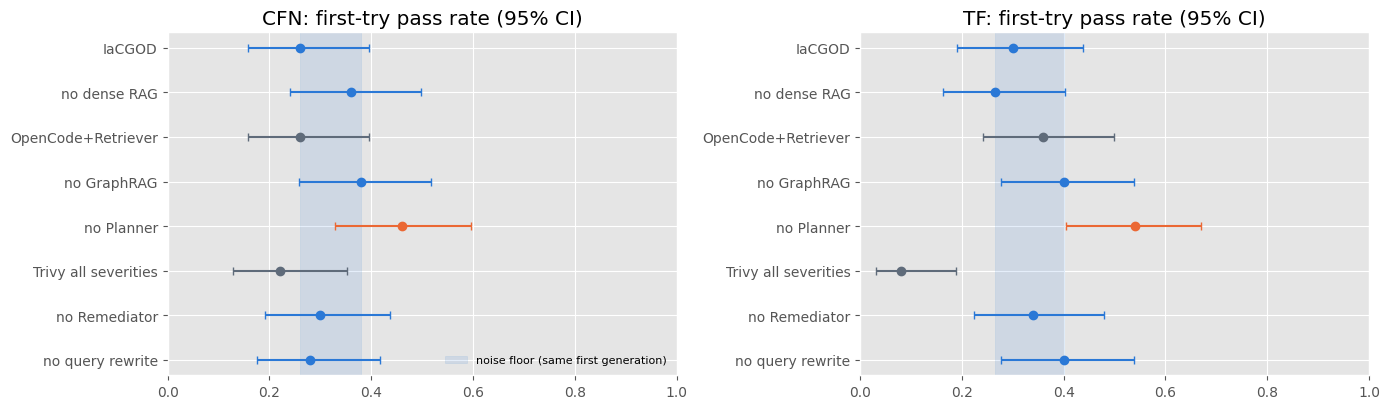

In [32]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h
GEN_SAME = ("IaCGOD", "NoDenseRAG", "NoGraphRAG", "NoRemediator", "NoQueryRewrite")
rows = []
for e in ABL_EXPS:
    d = runs[runs.exp == e]; k = int((d.passed & (d.iterations_used == 1)).sum()); n = len(d)
    lo, hi = wilson(k, n); cond = e.split("_Ablation_")[1]
    role = ("same first generation" if cond in GEN_SAME else "changes generation (Planner)" if cond == "NoPlanner"
            else "changes the gate" if cond == "TrivyAllSeverities" else "different harness")
    rows.append(dict(lang=lang_of(e), exp=e, condition=LABEL[e], role=role, n=n, first_try=k, rate=k / n, ci_lo=lo, ci_hi=hi))
tabH2 = pd.DataFrame(rows)
band = tabH2[tabH2.role == "same first generation"].groupby("lang").rate.agg(["min", "max", "mean"])
display(tabH2.drop(columns="exp").round(3)); print("noise floor (same first-generation pipeline):"); display(band.round(3))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for ax, lang in zip(axs, ("CFN", "TF")):
    t = tabH2[tabH2.lang == lang].reset_index(drop=True)
    ax.axvspan(band.loc[lang, "min"], band.loc[lang, "max"], color="#2a78d6", alpha=0.12, label="noise floor (same first generation)")
    for i, r in t.iterrows():
        col = "#2a78d6" if r.role == "same first generation" else "#eb6834" if "Planner" in r.role else "#5f6b7a"
        ax.errorbar(r.rate, i, xerr=[[r.rate - r.ci_lo], [r.ci_hi - r.rate]], fmt="o", color=col, capsize=3)
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.condition); ax.invert_yaxis()
    ax.set_title(f"{lang}: first-try pass rate (95% CI)"); ax.set_xlim(0, 1)
axs[0].legend(frameon=False, loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "H2_first_try.png", dpi=150); plt.show()

,lang,condition,first_fail,repaired,repaired_pct,repair_turns_mean,repair_turns_median,resolved in 1 turn %,resolved in <=3 turns %,p_vs_IaCGOD_unpaired,paired_scenarios,paired_turns_IaCGOD,paired_turns_cond,p_paired
0,CFN,IaCGOD,37,36,97.297,2.778,2.0,37.838,81.081,NaN,36,2.778,2.778,NaN
1,CFN,no dense RAG,32,31,96.875,2.452,2.0,28.125,84.375,0.633,27,2.889,2.556,0.957
2,CFN,OpenCode+Retriever,37,34,91.892,2.529,2.0,29.730,78.378,0.608,28,2.964,2.679,0.664
3,CFN,no GraphRAG,31,31,100.000,1.903,1.0,61.290,90.323,0.044,23,3.043,2.043,0.026
4,CFN,no Planner,27,25,92.593,1.600,1.0,62.963,88.889,0.017,23,3.522,1.652,0.002
5,CFN,Trivy all severities,39,38,97.436,2.526,2.0,28.205,82.051,0.497,30,3.033,2.567,0.758
6,CFN,no Remediator,35,33,94.286,1.697,1.0,60.000,88.571,0.056,30,2.767,1.767,0.051
7,CFN,no query rewrite,36,35,97.222,2.286,2.0,47.222,80.556,0.398,31,3.065,2.323,0.137
8,TF,IaCGOD,35,35,100.000,2.743,2.0,40.000,77.143,NaN,35,2.743,2.743,NaN
9,TF,no dense RAG,36,34,94.444,3.912,3.0,25.000,55.556,0.050,26,2.654,3.885,0.106


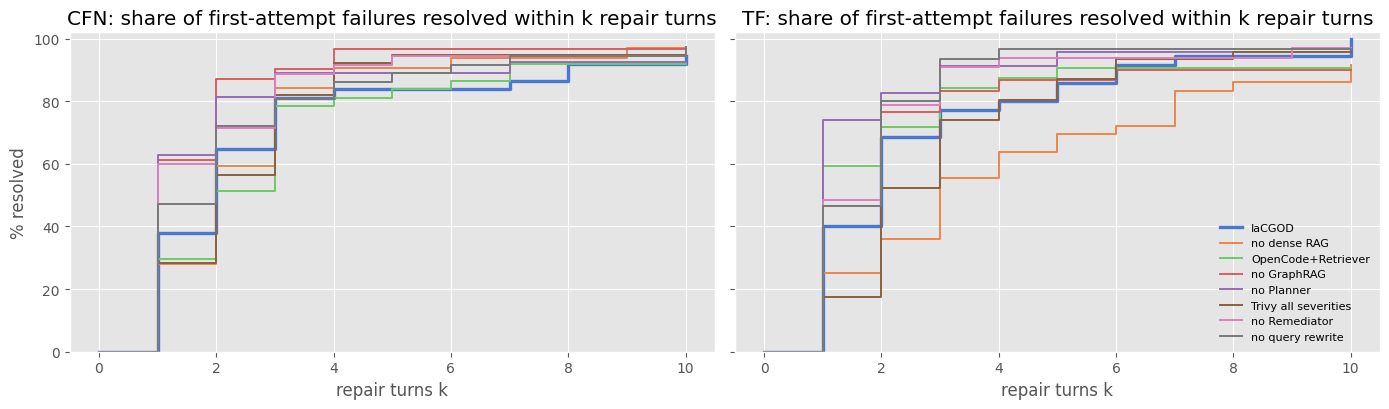

In [33]:
fail1 = runs[runs.exp.isin(ABL_EXPS) & ~(runs.passed & (runs.iterations_used == 1))].copy()
fail1["repair_turns"] = fail1.iterations_used - 1
rows = []
for lang in ("CFN", "TF"):
    base = fail1[fail1.exp == f"{lang}_Ablation_IaCGOD"]
    for e in GROUPS[f"{lang} ablation"]:
        d = fail1[fail1.exp == e]; ok = d[d.passed]
        p_mw = stats.mannwhitneyu(base[base.passed].repair_turns, ok.repair_turns).pvalue if not e.endswith("_IaCGOD") and len(ok) > 3 else np.nan
        shared = set(base.row_number) & set(d.row_number)
        bb = base.set_index("row_number").loc[list(shared)]; dd = d.set_index("row_number").loc[list(shared)]
        both = [r for r in shared if bb.loc[r, "passed"] and dd.loc[r, "passed"]]
        x, y = bb.loc[both, "repair_turns"].values, dd.loc[both, "repair_turns"].values
        p_w = stats.wilcoxon(x, y).pvalue if not e.endswith("_IaCGOD") and len(both) > 5 and np.any(x != y) else np.nan
        rows.append(dict(lang=lang, condition=LABEL[e], first_fail=len(d), repaired=len(ok), repaired_pct=100 * len(ok) / max(1, len(d)),
                         repair_turns_mean=ok.repair_turns.mean(), repair_turns_median=ok.repair_turns.median(),
                         **{"resolved in 1 turn %": 100 * (ok.repair_turns == 1).sum() / max(1, len(d)),
                            "resolved in <=3 turns %": 100 * (ok.repair_turns <= 3).sum() / max(1, len(d))},
                         p_vs_IaCGOD_unpaired=p_mw, paired_scenarios=len(both),
                         paired_turns_IaCGOD=x.mean() if len(both) else np.nan, paired_turns_cond=y.mean() if len(both) else np.nan, p_paired=p_w))
tabH3 = pd.DataFrame(rows).round(3)
display(tabH3)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, lang in zip(axs, ("CFN", "TF")):
    for e in GROUPS[f"{lang} ablation"]:
        d = fail1[fail1.exp == e]
        ks = np.arange(0, 11); cum = [100 * (d.passed & (d.repair_turns <= k)).sum() / max(1, len(d)) for k in ks]
        ax.step(ks, cum, where="post", lw=2.4 if e.endswith("_IaCGOD") else 1.4, label=LABEL[e])
    ax.set_title(f"{lang}: share of first-attempt failures resolved within k repair turns"); ax.set_xlabel("repair turns k"); ax.set_ylim(0, 102)
axs[0].set_ylabel("% resolved"); axs[1].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "H3_repair_curves.png", dpi=150); plt.show()

In [34]:
rt = turns[turns.exp.isin(ABL_EXPS) & (turns.n_a > 0)]
g = rt.groupby("exp")
tabH4 = pd.DataFrame({"repair turns": g.size(), "errors fixed/turn": g.fixed.mean(), "errors introduced/turn": g.introduced.mean(),
                      "net progress/turn": (g.fixed.sum() - g.introduced.sum()) / g.size(),
                      "stuck turns %": 100 * g.no_progress.mean(), "turns with a class regression %": 100 * g.apply(lambda x: (x.reg_cls != "").mean())})
rep_tok = (calls[calls.iteration.fillna(0) >= 1].groupby(["exp", "agent"]).tokens.sum().unstack(fill_value=0))
rep_turns = calls[calls.iteration.fillna(0) >= 1].groupby("exp").apply(lambda x: x[["run_id", "iteration"]].drop_duplicates().shape[0])
tabH4["k tokens / repair turn"] = (rep_tok.sum(axis=1) / rep_turns / 1000)
tabH4 = tabH4.loc[[e for e in ABL_EXPS if e in tabH4.index]].round(2)
display(tabH4.rename(index=LABEL))

,repair turns,errors fixed/turn,errors introduced/turn,net progress/turn,stuck turns %,turns with a class regression %,k tokens / repair turn
exp,,,,,,,
IaCGOD,114,0.96,0.21,0.75,15.79,7.89,69.08
no dense RAG,90,0.93,0.17,0.77,20.00,8.89,79.92
OpenCode+Retriever,111,0.88,0.21,0.68,29.73,3.60,NaN
no GraphRAG,59,1.20,0.20,1.00,6.78,6.78,63.16
no Planner,68,0.88,0.15,0.74,27.94,10.29,79.53
Trivy all severities,110,1.24,0.26,0.97,10.00,10.00,81.75
no Remediator,84,1.06,0.19,0.87,17.86,10.71,53.23
no query rewrite,94,1.03,0.17,0.86,21.28,8.51,76.21
IaCGOD,96,0.96,0.30,0.66,17.71,4.17,48.40


,resources/scen,extra/scen,accuracy %,coverage %,Trivy-clean %,HIGH+CRIT failed/scen,MEDIUM failed/scen,LOW failed/scen,intent strict %
exp,,,,,,,,,
IaCGOD,16.38,4.38,78.43,85.96,32.00,0.02,0.60,1.30,70.00
no dense RAG,16.60,4.60,77.92,86.33,36.00,0.02,0.42,1.08,72.00
OpenCode+Retriever,14.88,2.88,83.13,84.77,36.00,0.02,0.42,1.04,68.00
no GraphRAG,17.34,5.10,76.53,86.64,38.00,0.00,0.44,1.44,72.00
no Planner,15.86,3.74,81.03,87.17,40.00,0.02,0.38,1.06,90.00
Trivy all severities,17.94,5.68,73.07,87.80,98.00,0.02,0.00,0.00,84.00
no Remediator,15.78,3.78,78.81,87.13,36.00,0.02,0.48,1.02,80.00
no query rewrite,17.52,5.92,73.88,84.26,36.00,0.00,0.44,0.92,70.00
IaCGOD,15.96,5.04,75.97,84.56,20.00,0.00,1.36,1.86,82.00


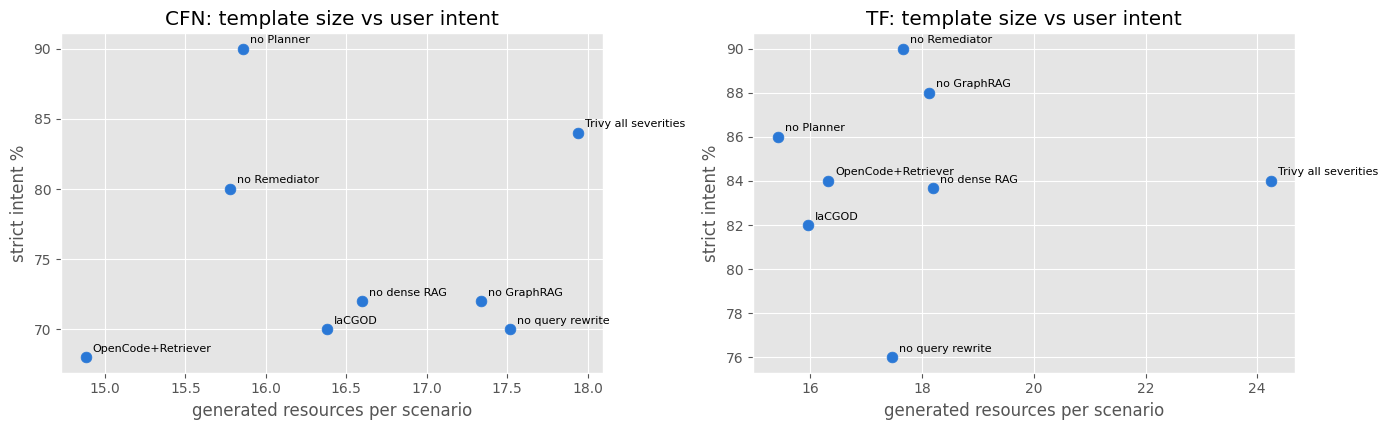

In [35]:
tv = []
for e in ABL_EXPS:
    f = RES / f"Trivy_{e}.csv"
    if f.exists():
        t = pd.read_csv(f); t["exp"] = e; tv.append(t)
tv = pd.concat(tv, ignore_index=True)
tv = tv[tv.error.isna()] if "error" in tv else tv
sec = tv.groupby("exp").agg(**{"Trivy-clean %": ("trivy_passed", lambda s: 100 * s.mean()),
                               "HIGH+CRIT failed/scen": ("severity_high_failed", "mean"),
                               "MEDIUM failed/scen": ("severity_medium_failed", "mean"), "LOW failed/scen": ("severity_low_failed", "mean")})
size = runs[runs.exp.isin(ABL_EXPS)].groupby("exp").agg(**{"resources/scen": ("gen", "mean"), "extra/scen": ("extra", "mean"),
                                                         "accuracy %": ("acc_pct", "mean"), "coverage %": ("cov_pct", "mean")})
intent_p = Path("ablation_selection/intent_results")
NAME = {"IaCGOD": "baseline", "NoDenseRAG": "no-dense-rag", "NoGraphRAG": "no-graphrag", "NoPlanner": "no-planner", "NoRemediator": "no-remediator",
        "NoQueryRewrite": "no-query-rewrite", "TrivyAllSeverities": "trivy-all-sev", "OpenCodeRetriever": "opencode-retriever"}
ints = {}
for e in ABL_EXPS:
    f = intent_p / f"{NAME[e.split('_Ablation_')[1]]}.csv"
    if f.exists():
        it = pd.read_csv(f); it = it[(it.lang == lang_of(e).lower()) & it.intent_status.isin(["evaluated", "unevaluable"])]
        ints[e] = 100 * it.intent_strict.astype(bool).mean()
tabH5 = size.join(sec)
tabH5["intent strict %"] = pd.Series(ints)
tabH5 = tabH5.loc[[e for e in ABL_EXPS if e in tabH5.index]].round(2)
display(tabH5.rename(index=LABEL))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, lang in zip(axs, ("CFN", "TF")):
    t = tabH5.loc[[e for e in GROUPS[f"{lang} ablation"] if e in tabH5.index]]
    ax.scatter(t["resources/scen"], t["intent strict %"], s=60, color="#2a78d6")
    for e, r in t.iterrows():
        ax.annotate(LABEL[e], (r["resources/scen"], r["intent strict %"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax.set_xlabel("generated resources per scenario"); ax.set_ylabel("strict intent %"); ax.set_title(f"{lang}: template size vs user intent")
plt.tight_layout(); plt.savefig(FIG / "H5_size_vs_intent.png", dpi=150); plt.show()

first_try_pct             iters_mean          
band                               L1-2    L3  L4-5       L1-2   L3 L4-5
lang condition                                                          
CFN  IaCGOD                        30.0  20.0  26.7        2.3  3.3  3.6
     OpenCode+Retriever            50.0  20.0  20.0        2.1  4.1  3.4
     Trivy all severities          30.0  10.0  23.3        2.6  2.6  3.6
     no GraphRAG                   60.0  30.0  33.3        1.8  2.1  2.3
     no Planner                    60.0  50.0  40.0        1.6  3.0  2.4
     no Remediator                 50.0  40.0  20.0        1.8  2.1  3.2
     no dense RAG                  70.0  40.0  23.3        1.5  2.7  3.3
     no query rewrite              60.0  10.0  23.3        1.8  2.8  3.3
TF   IaCGOD                        50.0  50.0  16.7        1.9  3.0  3.2
     OpenCode+Retriever            40.0  60.0  26.7        1.9  1.6  2.3
     Trivy all severities          20.0  10.0   3.3        3.2  3.2  4.5
     no GraphRAG                   40.0  60.0  33.3        2.2  2.7  2.9
     no Planner                    50.0  60.0  53.3        1.9  1.7  2.0
     no Remediator                 50.0  40.0  26.7        1.9  2.9  2.6
     no dense RAG                  20.0  55.6  20.0        5.0  2.9  4.5
     no query rewrite              50.0  50.0  33.3        1.7  1.8  2.6

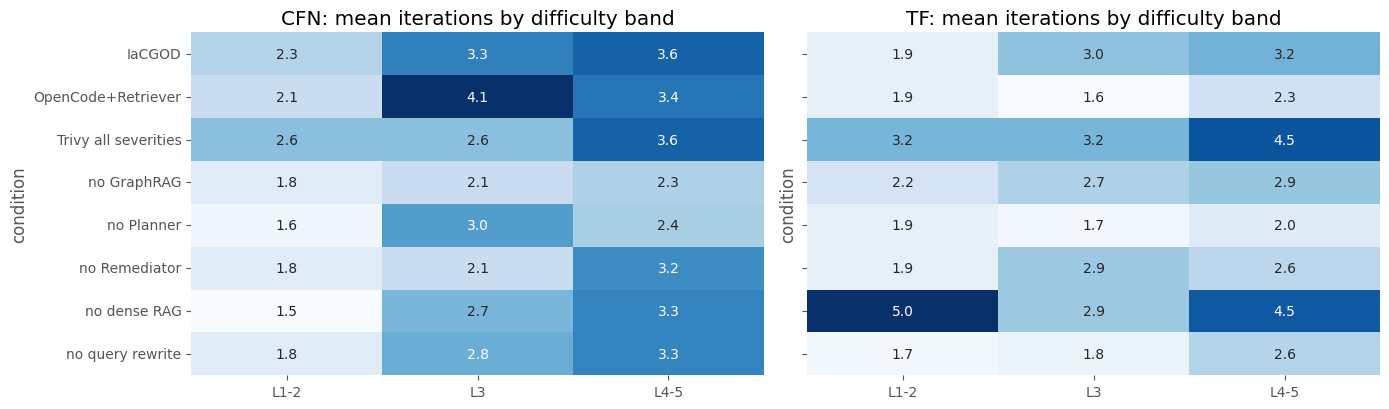

In [36]:
lv = runs[runs.exp.isin(ABL_EXPS)].copy()
lv["band"] = pd.cut(lv.difficulty, [0, 2, 3, 5], labels=["L1-2", "L3", "L4-5"])
lv["first_try"] = lv.passed & (lv.iterations_used == 1)
tabH6 = lv.groupby(["lang", "band", "exp"]).agg(n=("row_number", "size"), first_try_pct=("first_try", lambda s: 100 * s.mean()),
                                                iters_mean=("iterations_used", "mean"), pass_pct=("passed", lambda s: 100 * s.mean())).reset_index()
tabH6["condition"] = tabH6.exp.map(LABEL)
display(tabH6.pivot_table(index=["lang", "condition"], columns="band", values=["iters_mean", "first_try_pct"]).round(1))
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, lang in zip(axs, ("CFN", "TF")):
    t = tabH6[tabH6.lang == lang].pivot_table(index="condition", columns="band", values="iters_mean")
    sns.heatmap(t, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar=False); ax.set_title(f"{lang}: mean iterations by difficulty band"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "H6_iters_by_band.png", dpi=150); plt.show()

In [37]:
for name, df_ in {"H1_agent_calls_tokens": tabH1.reset_index(), "H2_first_try": tabH2, "H3_repair_stage": tabH3,
                  "H4_repair_turns": tabH4.reset_index(), "H5_quality_intent": tabH5.reset_index(), "H6_by_difficulty": tabH6}.items():
    df_.to_csv(FINAL / "repair_loop_tables" / f"{name}.csv", index=False)
print("exported H1-H6 to", FINAL / "repair_loop_tables")

exported H1-H6 to ../IaCGOD/final_results/repair_loop_tables


## I. Error categories (RQ3)

In [38]:
import error_categories as ec
SEC_CHECKS = json.load(open(DATA / "security_checks.json"))
RQ3_FULL = {lang: FULL[lang] + [f"{lang}_RealAWS_Opus55"] for lang in ("CFN", "TF")}
I_EXPS = RQ3_FULL["CFN"] + RQ3_FULL["TF"]
def load_msgs(e):
    global INDEX
    src = FINAL / e / "results_final.csv"; p = CACHE / f"msgs_{e}.pkl"
    rids = sorted(runs.loc[runs.exp == e, "run_id"].dropna().astype(str).unique())
    if p.exists() and p.stat().st_mtime >= src.stat().st_mtime:
        c = pd.read_pickle(p)
        if c["run_ids"] == rids:
            return c["df"]
    if INDEX is None:
        INDEX = rl.index_runs(RUNS)
    blocking = "all" if "TrivyAllSeverities" in e else rl.BLOCKING_DEFAULT
    d = ec.extract_messages(rids, RUNS, lang_of(e), INDEX, blocking=blocking)
    pd.to_pickle({"run_ids": rids, "df": d}, p)
    return d
msgs = pd.concat([load_msgs(e).assign(exp=e) for e in I_EXPS], ignore_index=True)
msgs["iteration"] = msgs.iteration.astype(int); msgs["lang"] = msgs.exp.map(lang_of)
_cc = [ec.categorise(r.lang, r.cls, r.stage, r.key, r.sub, r.msg, SEC_CHECKS) for r in msgs.itertuples()]
msgs["category"] = [c for c, _ in _cc]; msgs["rule"] = [r_ for _, r_ in _cc]
msgs["cat_stage"] = msgs.category.map(ec.STAGE_OF).fillna("-")
msgs["identifier"] = np.where(msgs.stage == "yaml", "yaml-syntax/" + msgs["sub"].astype(str), msgs.key)
_chk = iters[iters.exp.isin(I_EXPS)].assign(iteration=lambda x: x.iteration.astype(int))
_agree = []
for cls in CLASSES:
    a = _chk[_chk[f"{cls}_keys"] != ""].set_index(["exp", "run_id", "iteration"])[f"{cls}_keys"].str.split("|").map(set)
    b = msgs[msgs.cls == cls].groupby(["exp", "run_id", "iteration"]).key.agg(set)
    j = a.to_frame("a").join(b.rename("b"), how="outer")
    _agree.append((cls, len(j), round(100 * (j.a == j.b).mean(), 1)))
display(pd.DataFrame(_agree, columns=["class", "iterations with identifiers", "same identifier set as the iteration table (%)"]))
print(len(msgs), "identifier occurrences in", msgs.groupby(["exp", "run_id", "iteration"]).ngroups, "failing iterations")

,class,iterations with identifiers,same identifier set as the iteration table (%)
0,syntax,873,100.0
1,schema,672,100.0
2,security,552,100.0
3,deploy,2089,100.0


12046 identifier occurrences in 4051 failing iterations


In [39]:
_one = msgs.drop_duplicates(["lang", "cls", "identifier", "exp", "run_id", "iteration"])
identI = (_one.groupby(["lang", "cls", "identifier"]).size().rename("iterations").to_frame()
          .join(msgs.groupby(["lang", "cls", "identifier"]).size().rename("occurrences"))
          .join(_one.drop_duplicates(["lang", "cls", "identifier", "exp", "run_id"]).groupby(["lang", "cls", "identifier"]).size().rename("scenarios"))
          .reset_index().sort_values(["lang", "cls", "iterations"], ascending=[True, True, False]))
with pd.option_context("display.max_rows", 1000, "display.max_colwidth", 90):
    for (lang, cls), d in identI.groupby(["lang", "cls"], sort=False):
        print(f"\n{lang} - {cls}: {len(d)} identifiers"); display(d.drop(columns=["lang", "cls"]).set_index("identifier"))


CFN - deploy: 178 identifiers


,iterations,occurrences,scenarios
identifier,,,
AWS::IAM::Role,203,344,98
stack-level,185,187,66
parameter,108,307,73
unknown-resource,83,83,47
AWS::StepFunctions::StateMachine,67,67,14
AWS::KMS::Key,64,75,27
AWS::EC2::VPC,57,58,20
AWS::EC2::InternetGateway,55,55,20
AWS::Cognito::UserPoolClient,40,57,20



CFN - schema: 60 identifiers


,iterations,occurrences,scenarios
identifier,,,
E3002,204,467,167
E0000,113,125,101
E3003,85,252,70
E3004,62,158,54
E3006,61,98,26
E6101,52,106,48
E3012,35,73,33
E1019,33,73,32
E3030,33,67,31



CFN - security: 28 identifiers


...

,iterations,occurrences,scenarios
identifier,,,
apply: Invalid provider configuration,313,313,305
apply: invalid AWS Region:,313,313,305
aws_iam_role,85,122,60
aws_kms_alias,54,74,46
aws_s3_bucket,44,119,38
aws_vpc,31,31,10
aws_cloudwatch_log_group,28,28,11
aws_key_pair,27,27,15
aws_iam_policy,23,26,13



TF - security: 24 identifiers


,iterations,occurrences,scenarios
identifier,,,
AWS-0164,133,271,125
AWS-0104,66,126,51
AWS-0132,46,97,42
AWS-0053,19,19,3
AWS-0054,18,18,5
AWS-0086,9,56,7
AWS-0087,9,56,7
AWS-0091,9,56,7
AWS-0093,9,56,7



TF - syntax: 112 identifiers


,iterations,occurrences,scenarios
identifier,,,
init: Failed to install provider,310,310,143
Unsupported argument,143,319,108
Missing required argument,55,206,42
Unsupported block type,42,75,39
Invalid resource type,40,48,22
Unsupported attribute,28,36,24
init: Invalid character,21,56,11
init: Unsupported block type,17,25,8
Reference to undeclared resource,14,32,12


In [40]:
def clean_msg(s, n=160):
    s = re.sub(r"\(Service: [^)]*\)|\(RequestToken[^)]*\)|\(SDK Attempt Count: \d+\)|Request ?ID: [\w-]+|RequestID: [\w-]+|"
               r"operation error [^,]+, https response error StatusCode: \d+, ,?", "", str(s))
    s = re.sub(r"arn:aws[^\s\"']+", "<arn>", s); s = re.sub(r"\s+", " ", s).strip()
    return s[:n]
_one = msgs.drop_duplicates(["lang", "cls", "identifier", "category", "exp", "run_id", "iteration"])
mapI = (_one.groupby(["lang", "cls", "identifier", "cat_stage", "category", "rule"]).size().rename("iterations").to_frame()
        .join(msgs.groupby(["lang", "cls", "identifier", "cat_stage", "category", "rule"]).agg(occurrences=("msg", "size"),
                                                                                           example_message=("msg", lambda s: clean_msg(s.iloc[0]))))
        .reset_index().sort_values(["lang", "cls", "iterations"], ascending=[True, True, False]))
mapI["security_check_title"] = mapI.apply(lambda r: ec.security_category(r.identifier, SEC_CHECKS)[2] if r.cls == "security" else "", axis=1)
TABLES_ = FINAL / "repair_loop_tables"
mapI.to_csv(TABLES_ / "I_category_mapping.csv", index=False)
ec.rules_table().to_csv(TABLES_ / "I_category_rules.csv", index=False)
print("security rule ids and their categories (from the titles in security_checks.json):")
display(mapI[mapI.cls == "security"].groupby(["identifier", "security_check_title", "category"]).iterations.sum().reset_index()
        .sort_values("iterations", ascending=False).set_index("identifier"))
print("occurrences per category and language:")
display(msgs.groupby(["cat_stage", "category", "lang"]).size().unstack("lang").fillna(0).astype(int))

security rule ids and their categories (from the titles in security_checks.json):


,security_check_title,category,iterations
identifier,,,
AWS-0164,Instances in a subnet should not receive a public IP address by de...,Network exposure,232
AWS-0132,S3 encryption should use Customer Managed Keys,Encryption missing or weak,139
AWS-0104,A security group rule should not allow unrestricted egress to any ...,Network exposure,122
AWS-0136,SNS topic not encrypted with CMK.,Encryption missing or weak,23
AWS-0345,Disallow unrestricted S3 IAM Policies,Access control and public access,21
AWS-0095,Unencrypted SNS topic.,Encryption missing or weak,21
AWS-0028,aws_instance should activate session tokens for Instance Metadata ...,Access control and public access,20
AWS-0053,Load balancer is exposed to the internet.,Network exposure,19
AWS-0093,S3 Access block should restrict public bucket to limit access,Access control and public access,19


occurrences per category and language:


lang                                                          CFN   TF
cat_stage   category                                                  
-           (collateral: cancelled by another failure)       1291    0
Deployment  IAM and permission errors                         152   86
            Missing provider configuration                      0  626
            Missing value                                     308   28
            No actionable message                             303   32
            Referenced resource or service not available      145   66
            Resource configuration rejected by the provider   803  317
            Template creates no resources                      13    6
Environment Name collision with leftover resource             102  504
            Provider installation                               0  327
            Quota or service limit                             34   44
            Transient provider failure or account state        42    0
Schema      Invalid property or argument                      552  527
            Invalid reference or dependency                   596  166
            Invalid value or type                             416  118
            Missing required property                         273  234
Security    Access control and public access                  118  252
            Encryption missing or weak                        276  133
            Logging and monitoring                              2    1
            Network exposure                                  347  442
Syntax      Malformed template                                246  802
            YAML formatting (yamllint)                       1316    0

In [41]:
_dep = msgs[msgs.cls == "deploy"].groupby(["exp", "run_id", "iteration"]).category.agg(lambda s: set(s) == {ec.COLLATERAL})
_only_coll = (_dep[_dep].reset_index()[["exp", "run_id", "iteration"]]
              .assign(cls="deploy", stage="deploy", category="No actionable message", cat_stage="Deployment", rule="only cancelled resources",
                      identifier="(only cancelled resources)", key="(only cancelled resources)", msg="Resource creation cancelled"))
occ = pd.concat([msgs[msgs.category != ec.COLLATERAL], _only_coll], ignore_index=True)
occ["lang"] = occ.exp.map(lang_of)
it_cats = occ.groupby(["exp", "run_id", "iteration"]).category.agg(set).to_dict()
occ_cls = occ.groupby(["exp", "run_id", "iteration", "category"]).cls.agg(set).to_dict()
fail_iters = iters[iters.exp.isin(I_EXPS) & ~iters.validation_passed.astype(bool)].assign(iteration=lambda x: x.iteration.astype(int))
_k = list(zip(fail_iters.exp, fail_iters.run_id, fail_iters.iteration))
fail_iters = fail_iters.assign(cats=[it_cats.get(k, set()) for k in _k])
_rows = []
for lang in ("CFN", "TF"):
    f = fail_iters[fail_iters.lang == lang]
    _rows.append(dict(lang=lang, failing_iterations=len(f),
                      **{"with >=1 unmapped identifier %": round(100 * f.cats.map(lambda s: ec.UNMAPPED in s).mean(), 2),
                         "only unmapped identifiers %": round(100 * f.cats.map(lambda s: s == {ec.UNMAPPED}).mean(), 2),
                         "no identifier at all %": round(100 * f.cats.map(lambda s: not s).mean(), 2),
                         "only environment categories %": round(100 * f.cats.map(lambda s: bool(s) and all(ec.STAGE_OF.get(c) == "Environment" for c in s)).mean(), 2)}))
tabI_unmapped = pd.DataFrame(_rows).set_index("lang"); display(tabI_unmapped)

,failing_iterations,with >=1 unmapped identifier %,only unmapped identifiers %,no identifier at all %,only environment categories %
lang,,,,,
CFN,2148,0.0,0.0,0.00,3.82
TF,1910,0.0,0.0,0.37,26.81


In [42]:
FAILED_RUNS = set(runs.loc[~runs.passed, "run_id"].astype(str))
CLS_RAN = {"syntax": "syntax_ran", "schema": "schema_ran", "security": "security_ran", "deploy": "deploy_ran"}
_ep = []
for (e, rid), g in iters[iters.exp.isin(I_EXPS)].groupby(["exp", "run_id"], sort=False):
    g = g.sort_values("iteration"); its = g.iteration.astype(int).tolist(); ok = g.validation_passed.astype(bool).tolist()
    ran = g[list(CLS_RAN.values())].to_dict("records")
    cats = [it_cats.get((e, rid, i), set()) for i in its]
    for c in set().union(*cats):
        f = next(k for k, s in enumerate(cats) if c in s)
        obs = occ_cls.get((e, rid, its[f], c), set())
        res = next((k for k in range(f + 1, len(its)) if c not in cats[k] and (ok[k] or any(ran[k][CLS_RAN[x]] for x in obs))), None)
        _ep.append((e, rid, c, res is not None, (its[res] - its[f]) if res is not None else np.nan, str(rid) in FAILED_RUNS and c in cats[-1]))
epI = pd.DataFrame(_ep, columns=["exp", "run_id", "category", "resolved", "latency", "unresolved"])

def category_table(lang):
    ex = RQ3_FULL[lang]; e_ = epI[epI.exp.isin(ex)]; f_ = fail_iters[fail_iters.exp.isin(ex)]
    o_ = occ[occ.exp.isin(ex)].drop_duplicates(["category", "identifier", "exp", "run_id", "iteration"])
    out = []
    for stage, cat in ec.CATEGORIES + [("-", ec.UNMAPPED)]:
        x = e_[e_.category == cat]
        if not len(x): continue
        row = {"stage": stage, "category": cat}
        for e in ex:
            xe = x[x.exp == e]; row[f"{LABEL[e]} blocked"] = len(xe); row[f"{LABEL[e]} unresolved"] = int(xe.unresolved.sum())
        row["% of failing iterations"] = round(100 * f_.cats.map(lambda s: cat in s).mean(), 1)
        row["episodes"] = len(x); row["resolved %"] = round(100 * x.resolved.mean(), 1); row["resolved in 1 turn %"] = round(100 * (x.latency == 1).mean(), 1)
        oc = o_[o_.category == cat]; top = oc.identifier.value_counts().index[0]
        row["example identifier"] = top; row["example message"] = clean_msg(oc[oc.identifier == top].msg.iloc[0], 140)
        out.append(row)
    return pd.DataFrame(out)
tabI = {}
for lang in ("CFN", "TF"):
    tabI[lang] = category_table(lang)
    tabI[lang].to_csv(TABLES_ / f"I_error_categories_{lang}.csv", index=False)
    v = tabI[lang].copy()
    for e in RQ3_FULL[lang]:
        v[LABEL[e]] = v[f"{LABEL[e]} blocked"].astype(str) + " (" + v[f"{LABEL[e]} unresolved"].astype(str) + ")"
    print(f"\n{lang}: scenarios in which the category blocked >= 1 iteration (unresolved in the last iteration of a failed run); "
          f"{int((fail_iters.lang == lang).sum())} failing iterations")
    with pd.option_context("display.max_colwidth", 70):
        display(v.set_index(["stage", "category"])[[LABEL[e] for e in RQ3_FULL[lang]] + ["% of failing iterations", "episodes", "resolved %",
                                                                                         "resolved in 1 turn %", "example identifier", "example message"]])
print("exported I_error_categories_CFN.csv, I_error_categories_TF.csv, I_category_mapping.csv, I_category_rules.csv")


CFN: scenarios in which the category blocked >= 1 iteration (unresolved in the last iteration of a failed run); 2148 failing iterations


DeepSeek-V4-Flash GLM-5.3-Flash Gemini-3.8-Flash Claude-Opus-5.5  % of failing iterations  episodes  resolved %  resolved in 1 turn %  \
stage       category                                                                                                                                                                                
Syntax      Malformed template                                         26 (1)        43 (3)           13 (0)          21 (0)                      5.7       103        98.1                  90.3   
            YAML formatting (yamllint)                                 33 (0)         8 (0)            1 (0)           0 (0)                      2.5        42       100.0                  81.0   
Schema      Invalid property or argument                               82 (0)        86 (0)           17 (0)           1 (0)                     11.0       186       100.0                  88.7   
            Missing required property                                  33 (0)        38 (0)            6 (0)           0 (0)                      4.3        77       100.0                  92.2   
            Invalid value or type                                      57 (0)        77 (0)           27 (0)          12 (0)                      9.9       173       100.0                  90.8   
            Invalid reference or dependency                            68 (0)        72 (2)           14 (0)           3 (0)                     11.0       157        98.7                  87.9   
Security    Encryption missing or weak                                 36 (2)        33 (2)           29 (0)          35 (0)                      7.7       133        97.7                  71.4   
            Network exposure                                           33 (0)        32 (1)           29 (0)          29 (1)                      6.6       123        97.6                  91.9   
            Access control and public access                           25 (0)         8 (1)            9 (0)           4 (0)                      2.3        46        97.8                  78.3   
            Logging and monitoring                                      1 (0)         1 (0)            0 (0)           0 (0)                      0.1         2       100.0                  50.0   
Deployment  Missing value                                              30 (0)        22 (1)           20 (0)           2 (1)                      5.1        74        98.6                  77.0   
            IAM and permission errors                                  23 (0)        27 (1)           11 (0)           3 (0)                      6.0        64       100.0                  59.4   
            Referenced resource or service not available               27 (0)        20 (0)           10 (1)           5 (0)                      5.1        62       100.0                  75.8   
            Resource configuration rejected by the provider            66 (4)        71 (3)           22 (1)          15 (1)                     19.6       174        96.6                  50.0   
            Template creates no resources                               4 (0)         3 (0)            3 (0)           1 (0)                      0.6        11       100.0                  72.7   
            No actionable message                                      26 (4)        35 (8)           15 (0)          12 (0)                     13.9        88        89.8                  55.7   
Environment Name collision with leftover resource                      15 (1)        12 (1)            4 (0)           7 (0)                      3.8        38        97.4                  81.6   
            Quota or service limit                                      2 (0)         2 (1)            1 (0)           1 (1)                      1.6         6        66.7                  33.3   
            Transient provider failure or account state                 1 (0)         0 (0)            2 (0)           1


TF: scenarios in which the category blocked >= 1 iteration (unresolved in the last iteration of a failed run); 1910 failing iterations


DeepSeek-V4-Flash GLM-5.3-Flash Gemini-3.8-Flash Claude-Opus-5.5  % of failing iterations  episodes  resolved %  resolved in 1 turn %  \
stage       category                                                                                                                                                                                
Syntax      Malformed template                                         19 (0)        19 (1)           10 (0)           1 (0)                      4.0        49       100.0                  93.9   
Schema      Invalid property or argument                               62 (1)        75 (1)           14 (0)           1 (0)                     12.2       152       100.0                  79.6   
            Missing required property                                  12 (1)        38 (0)            1 (0)           0 (0)                      3.8        51       100.0                  86.3   
            Invalid value or type                                      22 (0)        38 (0)            4 (0)           0 (0)                      3.9        64       100.0                  93.8   
            Invalid reference or dependency                            27 (1)        27 (1)           14 (0)           0 (0)                      5.3        68        98.5                  85.3   
Security    Encryption missing or weak                                 21 (1)        15 (0)           11 (0)          10 (0)                      4.0        57        98.2                  82.5   
            Network exposure                                           47 (1)        44 (0)           43 (0)          28 (0)                      9.7       162        98.8                  92.6   
            Access control and public access                           13 (0)         8 (0)            7 (0)           1 (0)                      1.6        29       100.0                  89.7   
            Logging and monitoring                                      1 (0)         0 (0)            0 (0)           0 (0)                      0.1         1       100.0                 100.0   
Deployment  Missing value                                              13 (0)         4 (0)            1 (0)           0 (0)                      1.0        18       100.0                  94.4   
            IAM and permission errors                                  17 (0)        16 (1)            6 (0)           0 (0)                      4.0        39       100.0                  69.2   
            Referenced resource or service not available               12 (1)        14 (0)            6 (0)           1 (0)                      2.6        33       100.0                  75.8   
            Resource configuration rejected by the provider            47 (1)        52 (0)           18 (0)          13 (0)                     11.3       130        99.2                  77.7   
            Template creates no resources                               3 (0)         1 (0)            1 (0)           0 (0)                      0.3         5       100.0                 100.0   
            Missing provider configuration                              0 (0)        75 (0)          230 (0)           0 (0)                     16.4       305       100.0                  92.8   
            No actionable message                                       3 (0)         7 (0)            3 (0)           2 (0)                      1.7        15       100.0                  53.3   
Environment Provider installation                                      19 (0)        40 (1)           77 (0)          18 (0)                     17.1       154       100.0                  31.2   
            Name collision with leftover resource                      33 (0)        35 (0)            9 (1)           7 (0)                      9.1        84       100.0                  54.8   
            Quota or service limit                                      9 (0)         3 (0)            0 (0)           0

exported I_error_categories_CFN.csv, I_error_categories_TF.csv, I_category_mapping.csv, I_category_rules.csv


## J. Baseline comparisons and cost (RQ1, RQ2)

In [43]:
def load_pass(e):
    d = pd.read_csv(FINAL / e / "results_final.csv", engine="python", usecols=["row_number", "validity", "iterations_used"]).drop_duplicates("row_number")
    return (d.validity.eq("valid_pass") & (d.iterations_used <= BUDGET)).set_axis(d.row_number)
def mcnemar(a, b, lang, A, B, subset, idx=None):
    idx = a.index.intersection(b.index) if idx is None else a.index.intersection(b.index).intersection(idx)
    a, b = a.loc[idx], b.loc[idx]; oa, ob = int((a & ~b).sum()), int((~a & b).sum())
    p = stats.binomtest(oa, oa + ob, .5).pvalue if oa + ob else 1.0
    return dict(lang=lang, A=A, B=B, subset=subset, scenarios=len(idx), pass_A=int(a.sum()), pass_B=int(b.sum()), only_A=oa, only_B=ob, p=p,
                p_text="< 0.001" if p < 0.001 else f"{p:.3f}")
ZS = {"DSV4F": "OneShot_DSV4F", "GLM53F": "OneShot_GLM53F", "Gemini38F": "OneShot_Gemini38F", "Opus55": "ZeroShot_Opus55"}
_rows = []
for lang in ("CFN", "TF"):
    mas, oc = load_pass(f"{lang}_RealAWS_DSV4F"), load_pass(f"{lang}_RealAWS_OpenCode_DSV4F")
    lv = runs[runs.exp == f"{lang}_RealAWS_DSV4F"].drop_duplicates("row_number").set_index("row_number").difficulty
    _rows.append(mcnemar(mas, oc, lang, "IaCGen-MAS DeepSeek-V4-Flash", "OpenCode DeepSeek-V4-Flash", "all levels"))
    _rows.append(mcnemar(mas, oc, lang, "IaCGen-MAS DeepSeek-V4-Flash", "OpenCode DeepSeek-V4-Flash", "levels 4-5", idx=lv[lv >= 4].index))
    for m, z in ZS.items():
        e = f"{lang}_RealAWS_{m}"
        _rows.append(mcnemar(load_pass(e), load_pass(f"{lang}_RealAWS_{z}"), lang, f"IaCGen-MAS {LABEL[e]} (final)", f"zero-shot {LABEL[e]}", "all levels"))
tabJ1 = pd.DataFrame(_rows)
tabJ1.to_csv(FINAL / "repair_loop_tables" / "J_rq1_paired_tests.csv", index=False)
display(tabJ1.drop(columns="p"))

,lang,A,B,subset,scenarios,pass_A,pass_B,only_A,only_B,p_text
0,CFN,IaCGen-MAS DeepSeek-V4-Flash,OpenCode DeepSeek-V4-Flash,all levels,250,239,227,20,8,0.036
1,CFN,IaCGen-MAS DeepSeek-V4-Flash,OpenCode DeepSeek-V4-Flash,levels 4-5,100,96,83,16,3,0.004
2,CFN,IaCGen-MAS DeepSeek-V4-Flash (final),zero-shot DeepSeek-V4-Flash,all levels,250,239,97,145,3,< 0.001
3,CFN,IaCGen-MAS GLM-5.3-Flash (final),zero-shot GLM-5.3-Flash,all levels,250,228,68,162,2,< 0.001
4,CFN,IaCGen-MAS Gemini-3.8-Flash (final),zero-shot Gemini-3.8-Flash,all levels,250,248,126,122,0,< 0.001
5,CFN,IaCGen-MAS Claude-Opus-5.5 (final),zero-shot Claude-Opus-5.5,all levels,250,246,159,88,1,< 0.001
6,TF,IaCGen-MAS DeepSeek-V4-Flash,OpenCode DeepSeek-V4-Flash,all levels,250,246,242,5,1,0.219
7,TF,IaCGen-MAS DeepSeek-V4-Flash,OpenCode DeepSeek-V4-Flash,levels 4-5,100,96,94,3,1,0.625
8,TF,IaCGen-MAS DeepSeek-V4-Flash (final),zero-shot DeepSeek-V4-Flash,all levels,250,246,111,135,0,< 0.001
9,TF,IaCGen-MAS GLM-5.3-Flash (final),zero-shot GLM-5.3-Flash,all levels,250,246,74,172,0,< 0.001


In [44]:
PRICES_20261010 = {"deepseek/deepseek-v4-flash": (0.0121, 1.28), "z-ai/glm-5.3-flash": (0.15, 0.50), "google/gemini-3.8-flash": (0.75, 3.75),
                   "anthropic/claude-opus-5.5": (4.00, 20.00), "openai/o3-mini": (1.10, 4.40)}
COST_RUNS = [
    ("CFN_RealAWS_DSV4F", "IaCGen-MAS", "deepseek/deepseek-v4-flash"), ("TF_RealAWS_DSV4F", "IaCGen-MAS", "deepseek/deepseek-v4-flash"),
    ("CFN_RealAWS_GLM53F", "IaCGen-MAS", "z-ai/glm-5.3-flash"), ("TF_RealAWS_GLM53F", "IaCGen-MAS", "z-ai/glm-5.3-flash"),
    ("CFN_RealAWS_Gemini38F", "IaCGen-MAS", "google/gemini-3.8-flash"), ("TF_RealAWS_Gemini38F", "IaCGen-MAS", "google/gemini-3.8-flash"),
    ("CFN_RealAWS_Opus55", "IaCGen-MAS", "anthropic/claude-opus-5.5"), ("TF_RealAWS_Opus55", "IaCGen-MAS", "anthropic/claude-opus-5.5"),
    ("CFN_RealAWS_OneShot_DSV4F", "Zero-shot", "deepseek/deepseek-v4-flash"), ("TF_RealAWS_OneShot_DSV4F", "Zero-shot", "deepseek/deepseek-v4-flash"),
    ("CFN_RealAWS_OneShot_GLM53F", "Zero-shot", "z-ai/glm-5.3-flash"), ("TF_RealAWS_OneShot_GLM53F", "Zero-shot", "z-ai/glm-5.3-flash"),
    ("CFN_RealAWS_OneShot_Gemini38F", "Zero-shot", "google/gemini-3.8-flash"), ("TF_RealAWS_OneShot_Gemini38F", "Zero-shot", "google/gemini-3.8-flash"),
    ("CFN_RealAWS_ZeroShot_Opus55", "Zero-shot", "anthropic/claude-opus-5.5"), ("TF_RealAWS_ZeroShot_Opus55", "Zero-shot", "anthropic/claude-opus-5.5"),
    ("CFN_RealAWS_OpenCode_DSV4F", "OpenCode+Validator", "deepseek/deepseek-v4-flash"), ("TF_RealAWS_OpenCode_DSV4F", "OpenCode+Validator", "deepseek/deepseek-v4-flash"),
    ("CFN_DPIaCEval_o3mini_DeployOnly", "IaCGen-MAS (DPIaC-Eval)", "openai/o3-mini"),
]
_cost_data = {e: pd.read_csv(FINAL / e / "results_final.csv", engine="python") for e, _, _ in COST_RUNS}
def _per_call(names):
    d = pd.concat([_cost_data[n] for n in names]); return d.token_prompt_tokens.sum() / d.llm_calls_total.sum()
OPUS_EST = {}
for L in ("CFN", "TF"):
    OPUS_EST[f"{L}_RealAWS_Opus55"] = ("mas", _per_call([f"{L}_RealAWS_{m}" for m in ("DSV4F", "GLM53F", "Gemini38F")]))
    OPUS_EST[f"{L}_RealAWS_ZeroShot_Opus55"] = ("zs", np.mean([_cost_data[f"{L}_RealAWS_OneShot_{m}"].token_prompt_tokens.mean() for m in ("DSV4F", "GLM53F", "Gemini38F")]))
_rows = []
for e, appr, orid in COST_RUNS:
    d = _cost_data[e]; pp, pc = (x / 1e6 for x in PRICES_20261010[orid]); n = len(d)
    npass = int(((d.final_validation_passed.astype(str) == "True") & (d.iterations_used <= BUDGET)).sum()); note = ""
    if appr.startswith("OpenCode"):
        prompt = d.token_input_tokens.astype(float); compl = d.token_output_tokens.astype(float) + d.thinking_tokens_total.astype(float)
        note = "prompt = OpenCode input tokens; completion = output + reasoning tokens"
    else:
        prompt = d.token_prompt_tokens.astype(float); compl = d.token_completion_tokens.astype(float)
    if e in OPUS_EST:
        kind, v = OPUS_EST[e]
        note = (f"prompt tokens estimated (measured mean {prompt.mean():.0f}): " +
                (f"calls x {v:.0f} tokens/call of the other three IaCGen-MAS models" if kind == "mas" else f"{v:.0f} tokens = mean of the other three zero-shot runs"))
        prompt = d.llm_calls_total.astype(float) * v if kind == "mas" else pd.Series(v, index=d.index)
    cost = prompt * pp + compl * pc
    _rows.append(dict(run=e, approach=appr, lang=lang_of(e), openrouter_id=orid, usd_per_M_prompt=PRICES_20261010[orid][0], usd_per_M_completion=PRICES_20261010[orid][1],
                      scenarios=n, passed=npass, pass_pct=round(100 * npass / n, 1), llm_calls_mean=round(d.llm_calls_total.mean(), 1),
                      prompt_ktok_mean=round(prompt.mean() / 1000, 1), completion_ktok_mean=round(compl.mean() / 1000, 1),
                      usd_per_scenario=round(cost.mean(), 4), usd_total=round(cost.sum(), 2), usd_per_pass=round(cost.sum() / max(1, npass), 4), notes=note))
tabJ2 = pd.DataFrame(_rows)
tabJ2.to_csv(FINAL / "repair_loop_tables" / "J_llm_cost.csv", index=False)
with pd.option_context("display.max_colwidth", 110):
    display(tabJ2.set_index("run"))

,approach,lang,openrouter_id,usd_per_M_prompt,usd_per_M_completion,scenarios,passed,pass_pct,llm_calls_mean,prompt_ktok_mean,completion_ktok_mean,usd_per_scenario,usd_total,usd_per_pass,notes
run,,,,,,,,,,,,,,,
CFN_RealAWS_DSV4F,IaCGen-MAS,CFN,deepseek/deepseek-v4-flash,0.0121,1.28,250,239,95.6,10.8,136.4,30.1,0.0402,10.05,0.0421,
TF_RealAWS_DSV4F,IaCGen-MAS,TF,deepseek/deepseek-v4-flash,0.0121,1.28,250,246,98.4,8.0,114.5,26.8,0.0357,8.93,0.0363,
CFN_RealAWS_GLM53F,IaCGen-MAS,CFN,z-ai/glm-5.3-flash,0.1500,0.50,250,228,91.2,12.2,172.4,22.4,0.0370,9.26,0.0406,
TF_RealAWS_GLM53F,IaCGen-MAS,TF,z-ai/glm-5.3-flash,0.1500,0.50,250,246,98.4,10.3,163.0,20.2,0.0345,8.63,0.0351,
CFN_RealAWS_Gemini38F,IaCGen-MAS,CFN,google/gemini-3.8-flash,0.7500,3.75,250,248,99.2,5.1,59.7,6.2,0.0681,17.01,0.0686,
TF_RealAWS_Gemini38F,IaCGen-MAS,TF,google/gemini-3.8-flash,0.7500,3.75,250,249,99.6,8.4,106.0,8.9,0.1127,28.19,0.1132,
CFN_RealAWS_Opus55,IaCGen-MAS,CFN,anthropic/claude-opus-5.5,4.0000,20.00,250,246,98.4,4.0,52.7,19.0,0.5910,147.75,0.6006,prompt tokens estimated (measured mean 8): calls x 13118 tokens/call of the other three IaCGen-MAS models
TF_RealAWS_Opus55,IaCGen-MAS,TF,anthropic/claude-opus-5.5,4.0000,20.00,250,250,100.0,3.1,44.7,12.8,0.4357,108.93,0.4357,prompt tokens estimated (measured mean 6): calls x 14354 tokens/call of the other three IaCGen-MAS models
CFN_RealAWS_OneShot_DSV4F,Zero-shot,CFN,deepseek/deepseek-v4-flash,0.0121,1.28,250,97,38.8,1.0,0.6,14.6,0.0187,4.67,0.0482,


In [45]:
_rows = []
for lang in ("CFN", "TF"):
    for c in ("IaCGOD", "NoDenseRAG", "NoGraphRAG", "NoQueryRewrite", "NoRemediator", "NoPlanner", "TrivyAllSeverities"):
        e = f"{lang}_Ablation_{c}"; r = runs[runs.exp == e].drop_duplicates("run_id"); p_ = r[r.passed]
        tv_ = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python"); tv_ = tv_[tv_.error.isna()] if "error" in tv_ else tv_
        _rows.append({"lang": lang, "condition": LABEL[e], "exp": e, "passes/n": f"{int(r.passed.sum())}/{len(r)}",
                      "first-attempt pass %": round(100 * (r.passed & (r.iterations_used == 1)).mean(), 1),
                      "iterations to pass": f"{p_.iterations_used.mean():.2f} ({p_.iterations_used.median():g})",
                      "iterations mean": round(p_.iterations_used.mean(), 2), "iterations median": p_.iterations_used.median(),
                      "LLM calls mean": round(r.llm_calls_total.mean(), 1), "duration min mean": round(r.duration_seconds.mean() / 60, 1),
                      "extra resources/scenario": round(r.extra.mean(), 2),
                      "Trivy-clean % (no finding, any severity)": round(100 * (tv_.total_failed == 0).mean(), 1), "Trivy templates": len(tv_),
                      "strict intent %": round(tabH5.loc[e, "intent strict %"], 1) if e in tabH5.index else np.nan})
tabJ3 = pd.DataFrame(_rows)
tabJ3.to_csv(FINAL / "repair_loop_tables" / "J_ablation_simple.csv", index=False)
display(tabJ3.drop(columns=["exp", "iterations mean", "iterations median"]).set_index(["lang", "condition"]))

passes/n  first-attempt pass % iterations to pass  LLM calls mean  duration min mean  extra resources/scenario  Trivy-clean % (no finding, any severity)  Trivy templates  strict intent %
lang condition                                                                                                                                                                                                      
CFN  IaCGOD                  49/50                  26.0           3.04 (2)             8.2                9.3                      4.38                                      32.0               50             70.0
     no dense RAG            49/50                  36.0           2.55 (2)             6.8                4.0                      4.60                                      36.0               50             72.0
     no GraphRAG             50/50                  38.0           2.18 (2)             5.3                2.5                      5.10                                      38.0               50             72.0
     no query rewrite        49/50                  28.0           2.63 (2)             5.8                3.7                      5.92                                      36.0               50             70.0
     no Remediator           48/50                  30.0           2.17 (2)             4.9                3.2                      3.78                                      36.0               50             80.0
     no Planner              48/50                  46.0           1.83 (2)             4.7                2.6                      3.74                                      40.0               50             90.0
     Trivy all severities    49/50                  22.0           2.96 (3)             7.6                3.9                      5.68                                      98.0               50             84.0
TF   IaCGOD                  50/50                  30.0           2.92 (2)             7.5               10.1                      5.04                                      20.0               50             82.0
     no dense RAG            47/49                  26.5           3.83 (3)            11.4                6.0                      7.10                                      20.4               49             83.7
     no GraphRAG             48/50                  40.0           2.23 (2)             6.9               16.9                      6.72                                      22.0               50             88.0
     no query rewrite        49/50                  40.0           2.02 (2)             4.6                7.5                      6.28                                      22.0               50             76.0
     no Remediator           49/50                  34.0           2.24 (2)             4.7                7.6                      5.86                                      24.0               50             90.0
     no Planner              49/50                  54.0           1.65 (1)             3.5                6.7                      4.16                                      28.0               50             86.0
     Trivy all severities    49/50                   8.0           3.78 (3)             9.5                5.7                     12.78                                     100.0               50             84.0

## K. Why coding-agent runs fail

In [46]:
import opencode_failures as ocf
K = []
for e in ["CFN_RealAWS_OpenCode_DSV4F", "TF_RealAWS_OpenCode_DSV4F"]:
    k = ocf.classify(FINAL / e / "results_final.csv", RUNS, budget=BUDGET); k.insert(0, "exp", e); K.append(k)
tabK = pd.concat(K, ignore_index=True)
tabK["batch_30_iterations"] = tabK.run_id.astype(str).str[:8].isin(["20260912", "20260913", "20260914"]) & tabK.exp.str.startswith("CFN")
display(tabK)
tabK_sum = tabK.groupby(["exp", "category"]).agg(runs=("run_id", "size"), claims_success=("claims_success", "sum"),
                                                  in_30_iteration_batch=("batch_30_iterations", "sum")).reset_index()
display(tabK_sum)
oc_all = runs[runs.exp == "CFN_RealAWS_OpenCode_DSV4F"].copy()
oc_all["batch_30_iterations"] = oc_all.run_id.astype(str).str[:8].isin(["20260912", "20260913", "20260914"])
display(oc_all.groupby("batch_30_iterations").agg(runs=("run_id", "size"), passed=("passed", "sum"), pass_pct=("passed", lambda s: round(100 * s.mean(), 1))))
TABLES = FINAL / "repair_loop_tables"
tabK.to_csv(TABLES / "K_opencode_failures.csv", index=False); tabK_sum.to_csv(TABLES / "K_opencode_failures_summary.csv", index=False)

,exp,row_number,run_id,validity,iterations_used,deploy_timeouts,deploy_passes,deploy_failures,submitted,category,claims_success,batch_30_iterations
0,CFN_RealAWS_OpenCode_DSV4F,2,20261005_222720_be730fbd,invalid_harness,1,0,0,1,False,harness,False,False
1,CFN_RealAWS_OpenCode_DSV4F,6,20261005_223358_5288b8fd,valid_fail,15,0,1,14,True,edited_after_pass,False,False
2,CFN_RealAWS_OpenCode_DSV4F,37,20260918_190844_fb0c7f6d,valid_fail,15,0,0,0,True,budget,True,False
3,CFN_RealAWS_OpenCode_DSV4F,47,20260918_235943_f9b8c1ac,valid_fail,15,0,0,0,True,budget,True,False
4,CFN_RealAWS_OpenCode_DSV4F,99,20260912_162031_f5236c3b,valid_fail,5,2,0,1,True,no_deploy_result,True,True
5,CFN_RealAWS_OpenCode_DSV4F,120,20260912_184748_f9365d21,valid_fail,3,7,0,1,True,no_deploy_result,True,True
6,CFN_RealAWS_OpenCode_DSV4F,123,20261002_172339_76934f29,valid_fail,15,0,1,10,True,edited_after_pass,True,False
7,CFN_RealAWS_OpenCode_DSV4F,137,20260913_065154_b9d14711,valid_fail,1,7,0,0,False,no_deploy_result,True,True
8,CFN_RealAWS_OpenCode_DSV4F,141,20260913_083946_6b3392da,valid_fail,4,7,0,0,False,no_deploy_result,True,True
9,CFN_RealAWS_OpenCode_DSV4F,142,20260913_085941_164a7b4a,valid_fail,8,16,0,0,False,no_deploy_result,False,True


,exp,category,runs,claims_success,in_30_iteration_batch
0,CFN_RealAWS_OpenCode_DSV4F,budget,5,3,0
1,CFN_RealAWS_OpenCode_DSV4F,edited_after_pass,2,1,0
2,CFN_RealAWS_OpenCode_DSV4F,harness,2,0,0
3,CFN_RealAWS_OpenCode_DSV4F,no_deploy_result,13,11,13
4,CFN_RealAWS_OpenCode_DSV4F,over_budget,1,0,1
5,TF_RealAWS_OpenCode_DSV4F,budget,8,8,0


,runs,passed,pass_pct
batch_30_iterations,,,
False,165,156,94.5
True,85,71,83.5


## Summary table (exported for the thesis and Notion)

In [47]:
summ = tabA.set_index("exp")[["label", "rows", "pass", "p@1", "p@5", "p@15", "iters_mean", "iters_median", "first_try_%", "ktokens/scen"]].copy()
piv = tabB[["resolved_%", "in_1_turn_%", "median_latency", "share_of_runs_%"]].unstack("cls")
piv.columns = [f"{c}_{m}" for m, c in piv.columns]
summ = summ.join(piv).join(tabC[["fixed/turn", "introduced/turn", "turns_with_new_error_%", "class_regression_%", "runs_with_regression_%", "recurrence_share_%", "no_progress_%"]])
summ = summ.join(tabD[["ctx_tokens_median", "queries/turn", "ctx_share_of_run_tokens_median_%", "ctx_covers_failing_type_%"]]).join(tabE[["extra/scen", "missing/scen", "over_ratio_mean", "extra_share_%", "accuracy_%"]])
summ.to_csv(FINAL / "repair_loop_summary.csv")
display(summ.rename(index=LABEL).T)
print("written:", FINAL / "repair_loop_summary.csv")

exp,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash,Claude-Opus-5.5,OpenCode+DSV4F,Gemini-3.6-Flash (L3-5),DSV4F deploy-only (L3-5),o3-mini DPIaC-Eval,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash,Claude-Opus-5.5,OpenCode+DSV4F,DSV4F IaC-Eval (lint-only),IaCGOD,no dense RAG,OpenCode+Retriever,no GraphRAG,no Planner,Trivy all severities,no Remediator,no query rewrite,IaCGOD,no dense RAG,OpenCode+Retriever,no GraphRAG,no Planner,Trivy all severities,no Remediator,no query rewrite
label,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash,Claude-Opus-5.5,OpenCode+DSV4F,Gemini-3.6-Flash (L3-5),DSV4F deploy-only (L3-5),o3-mini DPIaC-Eval,DeepSeek-V4-Flash,GLM-5.3-Flash,Gemini-3.8-Flash,Claude-Opus-5.5,OpenCode+DSV4F,DSV4F IaC-Eval (lint-only),IaCGOD,no dense RAG,OpenCode+Retriever,no GraphRAG,no Planner,Trivy all severities,no Remediator,no query rewrite,IaCGOD,no dense RAG,OpenCode+Retriever,no GraphRAG,no Planner,Trivy all severities,no Remediator,no query rewrite
rows,250,250,250,250,250,137,134,153,250,250,250,250,250,372,50,50,50,50,50,50,50,50,50,49,50,50,50,50,50,50
pass,239,228,248,246,227,136,124,138,246,246,249,250,242,363,49,49,47,50,48,49,48,49,50,47,47,48,49,49,49,49
p@1,18.8,18.4,49.2,61.6,31.6,31.4,22.4,24.2,40.0,20.8,20.4,76.4,53.6,30.9,26.0,36.0,26.0,38.0,46.0,22.0,30.0,28.0,30.0,26.5,36.0,40.0,54.0,8.0,34.0,40.0
p@5,79.2,78.4,95.6,97.6,82.0,94.2,72.4,77.8,84.4,82.0,94.0,98.4,89.6,83.3,88.0,94.0,86.0,98.0,94.0,94.0,94.0,90.0,86.0,73.5,92.0,92.0,96.0,82.0,96.0,98.0
p@15,95.6,91.2,99.2,98.4,90.8,99.3,92.5,90.2,98.4,98.4,99.6,100.0,96.8,97.6,98.0,98.0,94.0,100.0,96.0,98.0,96.0,98.0,100.0,95.9,94.0,96.0,98.0,98.0,98.0,98.0
iters_mean,3.55,3.5,2.0,1.55,2.7,2.48,3.49,3.05,2.91,3.67,3.18,1.42,2.13,3.23,3.04,2.55,2.83,2.18,1.83,2.96,2.17,2.63,2.92,3.83,2.02,2.23,1.65,3.78,2.24,2.02
iters_median,3.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,3.0,1.0,1.0,3.0,2.0,2.0,2.0,2.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,2.0,1.0,3.0,2.0,2.0
first_try_%,18.8,18.4,49.2,61.6,31.6,31.4,22.4,24.2,40.0,20.8,20.4,76.4,53.6,30.9,26.0,36.0,26.0,38.0,46.0,22.0,30.0,28.0,30.0,26.5,36.0,40.0,54.0,8.0,34.0,40.0
ktokens/scen,167.0,195.0,66.0,19.0,42.0,48.0,254.0,124.0,141.0,183.0,115.0,13.0,25.0,103.0,180.0,174.0,64.0,102.0,128.0,208.0,113.0,172.0,108.0,285.0,74.0,168.0,76.0,203.0,78.0,100.0


written: ../IaCGOD/final_results/repair_loop_summary.csv


In [48]:
def thesis_row(e):
    r = runs[runs.exp == e].drop_duplicates("run_id"); p = r.passed.astype(bool); tk = r.token_all_tokens / 1000
    out = dict(n=len(r), passed=int(p.sum()), pass_pct=round(100 * p.mean(), 1), iters_mean=round(r[p].iterations_used.mean(), 2), iters_med=r[p].iterations_used.median(),
               ktok=round(tk.mean(), 0), calls=round(r.llm_calls_total.mean(), 1), dur=round(r.duration_seconds.mean() / 60, 1), failed=int((~p).sum()),
               failed_at_cap=int(((~p) & (r.iterations_used >= 15)).sum()), tok_fail=round(tk[~p].mean(), 0) if (~p).any() else np.nan, tok_pass=round(tk[p].mean(), 0),
               tok_share_fail=round(100 * tk[~p].sum() / tk.sum(), 1))
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python"); t = t[t.error.isna()] if "error" in t else t
    out["pol"] = round(100 * (t.total_passed / t.total_checks.replace(0, np.nan)).mean(), 1); out["clean"] = round(100 * (t.total_failed == 0).mean(), 1)
    for s, k in (("critical", "crit"), ("high", "high"), ("medium", "med"), ("low", "low")):
        out[k] = round(100 * t[f"severity_{s}_passed"].sum() / t[f"severity_{s}_eval"].sum(), 1)
    c = runs[(runs.exp == e) & runs.cov_pct.notna()].drop_duplicates("run_id")
    out["cov"] = round(c.cov_pct.mean(), 1); out["acc"] = round(c.acc_pct.mean(), 1)
    return out
thesis_numbers = pd.DataFrame({e: thesis_row(e) for e in SELECTED}).T
display(thesis_numbers.rename(index=LABEL))

,n,passed,pass_pct,iters_mean,iters_med,ktok,calls,dur,failed,failed_at_cap,tok_fail,tok_pass,tok_share_fail,pol,clean,crit,high,med,low,cov,acc
DeepSeek-V4-Flash,250.0,239.0,95.6,3.55,3.0,167.0,10.8,24.7,11.0,11.0,1007.0,128.0,26.6,95.3,40.0,100.0,99.9,95.7,81.7,86.4,81.1
GLM-5.3-Flash,250.0,228.0,91.2,3.50,2.0,195.0,12.2,23.9,22.0,22.0,946.0,122.0,42.7,95.7,40.8,100.0,99.5,96.7,82.7,85.4,79.3
Gemini-3.8-Flash,250.0,248.0,99.2,2.00,2.0,66.0,5.1,12.6,2.0,2.0,1387.0,55.0,16.8,96.1,42.0,100.0,99.7,97.0,84.6,87.2,84.2
Claude-Opus-5.5,250.0,246.0,98.4,1.55,1.0,19.0,4.0,6.9,4.0,4.0,140.0,17.0,11.8,95.8,42.4,99.8,100.0,97.5,81.8,90.0,79.3
OpenCode+DSV4F,250.0,227.0,90.8,2.70,2.0,42.0,13.5,14.5,23.0,8.0,128.0,33.0,28.2,96.2,44.8,100.0,99.7,96.7,85.5,86.3,84.7
Gemini-3.6-Flash (L3-5),137.0,136.0,99.3,2.48,2.0,48.0,6.4,10.1,1.0,1.0,642.0,44.0,9.7,96.0,46.0,100.0,99.5,96.4,85.7,84.3,86.5
DSV4F deploy-only (L3-5),134.0,124.0,92.5,3.49,2.0,254.0,12.1,41.5,10.0,10.0,1549.0,150.0,45.5,91.3,28.4,92.6,89.0,95.2,72.2,83.7,82.1
o3-mini DPIaC-Eval,153.0,138.0,90.2,3.05,2.0,124.0,11.7,31.1,15.0,15.0,736.0,58.0,58.1,87.8,13.1,90.4,80.5,94.0,76.2,87.5,79.0
DeepSeek-V4-Flash,250.0,246.0,98.4,2.91,2.0,141.0,8.0,16.7,4.0,4.0,1768.0,115.0,20.0,94.1,31.2,99.4,100.0,92.5,76.7,87.5,76.4
GLM-5.3-Flash,250.0,246.0,98.4,3.67,3.0,183.0,10.3,14.1,4.0,4.0,1541.0,161.0,13.5,94.7,33.6,99.7,99.9,92.3,81.9,88.1,79.7


In [49]:
TABLES = FINAL / "repair_loop_tables"; TABLES.mkdir(exist_ok=True)
export = {"A_passitr_iterations": tabA, "B_resolve_by_class": tabB.reset_index(), "C_regressions": tabC.reset_index(), "D_retrieved_context": tabD.reset_index(),
          "E_over_provisioning": tabE.reset_index(), "E_growth": pd.concat([tabE2, d_sec], axis=1).reset_index(), "F1_first_attempt": tabF1.reset_index(),
          "F5_ablation_tests": tabF5, "F6_wasted_effort": tabF6.reset_index(), "F7_F8_stubbornness_final_stage": pd.concat([t7, t8], axis=1).reset_index(),
          "G1_fix_rate_recurrence": pd.concat([t1, t2], axis=1).reset_index(), "G5_invalid_sensitivity": tabG5.reset_index(), "G6_coding_agent": tabG6, "D_context_effect": effD, "G3_provider_config": g3df.reset_index(), "G4_cross_run_solvability": pd.DataFrame(g4rows, columns=["lang", "run", "shared scenarios", "failed", "solved by another run", "failed by all (row_number)"]), "A_pass_by_level": lv_pr.reset_index(), "A_iters_by_level": lv_it.reset_index(), "haz": haz, "episodes": ep}
for (lang_, cls_), d_ in G2.items():
    d_.reset_index().rename(columns={"index": "identifier"}).to_csv(TABLES / f"G2_identifiers_{lang_}_{cls_}.csv", index=False)
for lang_, m_ in REG_FROM.items():
    m_.to_csv(TABLES / f"C_regression_from_{lang_}.csv")
for lang_, m_ in REG_MATRICES.items():
    m_.to_csv(TABLES / f"C_regression_matrix_{lang_}.csv")
for name, df_ in export.items():
    df_.to_csv(TABLES / f"{name}.csv", index=False)
thesis_numbers.to_csv(TABLES / "thesis_numbers.csv")
print("exported", len(export), "tables to", TABLES)

exported 20 tables to ../IaCGOD/final_results/repair_loop_tables
